# Conditional VAE and Conditional GAN for CIFAR-10
## Chun Fei's notebook: a controlled cVAE investigation and one supporting GAN experiment

**Author:** Hoon Chun Fei<br>
**Teammate:** You Xuan (GAN-focused notebook, not included in this repository)

### Contribution split

- **Chun Fei:** main cVAE investigation (six controlled VAE runs) and one supporting cGAN learning-rate comparison.
- **You Xuan:** main cGAN investigation in her individual notebook, with her own cVAE comparison.
- **Shared:** dataset split, frozen evaluation classifier, common final-evaluation protocol and overall model selection.

### Chun Fei model chain

| Family | Models | Main question |
|---|---|---|
| cVAE | `CF-VAE-A0-BL` → `A1-KLW` → `A3-MSC-CLEAN` → `A4-CCL` / `A5-CCL025`, with `A2-FB` as a rejected side branch | How do latent regularisation and class-conditioning changes affect realism, latent use and requested-class control? |
| cGAN | `CF-GAN-A0-EQUAL-LR` → `CF-GAN-A1-TTUR` | Does changing the generator/discriminator learning-rate balance improve the supporting GAN? |

The individual finalists from this notebook are `CF-VAE-A4-CCL` and
`CF-GAN-A0-EQUAL-LR`. They are handed to the shared final-evaluation notebook;
the overall team winner is selected only there under the common four-finalist protocol.

### Shared research/background section

The background research, project-level research questions, related work, dataset/feature-engineering description and core references below are shared with You Xuan's notebook. Individual model development and conclusions are each author's own.


# Background Research: Image Generation with GAN/VAE on CIFAR-10

## 1. Problem Background

**What is the problem?** The goal is to train a generative
deep-learning model — a GAN and/or VAE — that learns the underlying
distribution of CIFAR-10 and produces 1,000 new synthetic images spanning all
10 classes, together with an evaluation of their quality. Three guiding
questions (class-specific generation, grayscale vs. colour, and relative class
difficulty) inform the experiments and discussion within this project.

**Why is this challenging?** CIFAR-10 images are only 32 × 32 pixels, so fine
object details occupy very few pixels. The ten classes also contain different
poses, colours, textures and backgrounds. A useful generator therefore needs
to be evaluated for both image quality and diversity rather than by training
loss alone.

**Krizhevsky (2009), *Learning Multiple Layers of Features from Tiny Images*.**
The CIFAR-10 dataset description used in this notebook comes from this
technical report: 60,000 32 × 32 colour images across 10 classes, with 50,000
training images and 10,000 test images. We use this published dataset
definition when describing the data and keep the official 10,000-image test
set separate from model development.  
**Source:** [University of Toronto technical report (PDF)](https://www.cs.toronto.edu/~kriz/learning-features-2009-TR.pdf)

**Goodfellow et al. (2014), *Generative Adversarial Nets*.** The adversarial
generator-versus-discriminator training framework described in this paper is
the foundation of the supporting GAN models in this notebook. Our generator
produces conditional CIFAR-10 samples while the discriminator learns to
separate real from generated samples.  
**Source:** [arXiv:1406.2661](https://arxiv.org/abs/1406.2661)

**Kingma and Welling (2013), *Auto-Encoding Variational Bayes*.** The VAE
framework used in this notebook follows the paper's probabilistic
encoder/decoder formulation, reconstruction-plus-KL objective and
reparameterised latent sampling. This is implemented through `z_mean`,
`z_log_var`, sampled `z`, reconstruction loss and KL divergence.  
**Source:** [arXiv:1312.6114](https://arxiv.org/abs/1312.6114)

**Mirza and Osindero (2014), *Conditional Generative Adversarial Nets*.** The
idea of supplying class information as an additional input to a generative
model is used for requested-class generation. In our GAN, the class label is
provided to both generator and discriminator; the same general conditioning
principle is adapted by us to the VAE encoder/decoder.  
**Source:** [arXiv:1411.1784](https://arxiv.org/abs/1411.1784)


## Project Objectives and Research Questions

This notebook investigates how controlled architecture and training changes
affect conditional VAEs and conditional GANs on CIFAR-10. Specifically it answers:

1. Which cVAE configuration performs best?
2. Which cGAN configuration performs best?
3. Which controlled change improved or worsened each model?
4. Are cVAEs more stable but blurrier, and cGANs sharper but less stable?
5. Which model follows the requested class label most accurately?
6. Which classes are easiest and hardest to generate?
7. Which model should generate the final 1,000 images?

**Individual model experiments:** the shared research questions above are common to both teammates. Chun Fei's own VAE/GAN experiment chain is introduced later in this notebook.

## 2. Related Work and How Each Source Was Applied

The literature below is linked directly to the methodology used in this
notebook. Each reference states the specific concept taken from the paper and
where that concept appears in our implementation.

### 2.1 GAN training framework

**Goodfellow et al. (2014), *Generative Adversarial Nets*.** The adversarial
two-network training framework used in `CF-GAN-A0-EQUAL-LR` and
`CF-GAN-A1-TTUR` was adapted from this paper. The generator is trained to
produce samples that the discriminator cannot distinguish from real CIFAR-10
images, while the discriminator is trained to separate real and generated
samples. This adversarial relationship is the basic optimisation framework
used by both of Chun Fei's GAN runs.  
**Source:** [arXiv:1406.2661](https://arxiv.org/abs/1406.2661)

### 2.2 DCGAN-style convolutional architecture

**Radford, Metz and Chintala (2015), *Unsupervised Representation Learning with
Deep Convolutional Generative Adversarial Networks*.** The DCGAN-style
architecture used in the supporting GAN was adapted from the paper's
convolutional design guidelines in Section 3, including convolutional
up/downsampling, batch normalisation, a `tanh` generator output and
ReLU/LeakyReLU activation choices. In our notebook, these ideas are adapted to
32 × 32 CIFAR-10 and combined with class conditioning; the architecture is not
claimed to be an exact reproduction of the paper's network.  
**Source:** [arXiv:1511.06434](https://arxiv.org/abs/1511.06434)

### 2.3 VAE objective and latent sampling

**Kingma and Welling (2013), *Auto-Encoding Variational Bayes*.** The
variational autoencoder framework used in `CF-VAE-A0-BL` was adapted from the
paper's variational lower-bound formulation and reparameterisation-based
training method. In our implementation, the encoder outputs `z_mean` and
`z_log_var`, latent samples are produced by reparameterisation, and the model
is optimised using reconstruction loss together with KL-divergence
regularisation. Later VAE experiments modify this baseline while keeping the
same underlying variational structure.  
**Source:** [arXiv:1312.6114](https://arxiv.org/abs/1312.6114)

### 2.4 Requested-class conditioning

**Mirza and Osindero (2014), *Conditional Generative Adversarial Nets*.** The
requested-class mechanism used in this project was adapted from the paper's
conditional-generation idea, where auxiliary information such as a class
label is provided to the generative model. In our GAN, the requested CIFAR-10
label is supplied to both generator and discriminator. The same general
conditioning principle is also adapted to our VAE, although our conditional
VAE architecture is our own project implementation rather than a model copied
from this paper.  
**Source:** [arXiv:1411.1784](https://arxiv.org/abs/1411.1784)

### 2.5 Controlled-experiment approach used in this notebook

The literature-supported ideas above are not assumed to improve the model
automatically. Each technique is introduced as a controlled experiment,
measured using saved outputs and common evaluation metrics, and then retained
or rejected from evidence. Results such as A4's stronger class control or A0's
better GAN performance are therefore conclusions from **our own experiments**,
not claims taken from the cited papers.


## 3. Dataset and Feature Engineering

**Krizhevsky (2009), *Learning Multiple Layers of Features from Tiny Images*.**
The CIFAR-10 dataset composition used in this notebook is taken from the
technical report: 60,000 32 × 32 RGB images across 10 classes, with 50,000
training images and 10,000 test images. In our workflow, the 50,000-image
training pool is further split into 45,000 training and 5,000 validation
images using stratification, while the official 10,000-image test set remains
untouched for final evaluation.  
**Source:** [University of Toronto technical report (PDF)](https://www.cs.toronto.edu/~kriz/learning-features-2009-TR.pdf)

The preprocessing differs by model family. VAE images are rescaled to `[0,1]`
to match the sigmoid decoder output. GAN images are rescaled to `[-1,1]` to
match the `tanh` generator output.

**Radford, Metz and Chintala (2015), *Unsupervised Representation Learning with
Deep Convolutional Generative Adversarial Networks*.** The use of a `tanh`
generator output and image values scaled to the corresponding `[-1,1]` range
is consistent with the DCGAN training setup described in the paper. We apply
that design choice to our 32 × 32 conditional GAN while keeping the VAE on its
separate `[0,1]` range.  
**Source:** [arXiv:1511.06434](https://arxiv.org/abs/1511.06434)

Integer class labels are embedded inside the conditional models rather than
one-hot encoded during the initial dataset-preparation stage.


## References

1. **Goodfellow, I., et al. (2014), *Generative Adversarial Nets*.** Referenced
   specifically for the adversarial generator-discriminator training framework
   used in both supporting GAN runs, where the generator learns to produce
   samples that the discriminator cannot distinguish from real data.  
   **Source:** [arXiv:1406.2661](https://arxiv.org/abs/1406.2661)

2. **Kingma, D. P. and Welling, M. (2013), *Auto-Encoding Variational Bayes*.**
   Referenced specifically for the variational lower-bound formulation,
   reparameterised latent sampling, and the reconstruction-plus-KL objective
   used in `CF-VAE-A0-BL` and retained throughout the VAE experiment chain.  
   **Source:** [arXiv:1312.6114](https://arxiv.org/abs/1312.6114)

3. **Radford, A., Metz, L. and Chintala, S. (2015), *Unsupervised
   Representation Learning with Deep Convolutional Generative Adversarial
   Networks*.** Referenced specifically for the Section 3 DCGAN architecture
   guidelines used in our supporting GAN: convolutional up/downsampling, batch
   normalisation, generator `tanh` output and ReLU/LeakyReLU activation
   choices. These ideas were adapted to 32 × 32 CIFAR-10 and class
   conditioning.  
   **Source:** [arXiv:1511.06434](https://arxiv.org/abs/1511.06434)

4. **Mirza, M. and Osindero, S. (2014), *Conditional Generative Adversarial
   Nets*.** Referenced specifically for the conditional-generation method in
   Section 3.2, where class information is supplied as an additional input.
   This principle is used in our GAN and adapted by us to the VAE for
   requested-class generation.  
   **Source:** [arXiv:1411.1784](https://arxiv.org/abs/1411.1784)

5. **Bowman, S. R., et al. (2015), *Generating Sentences from a Continuous
   Space*.** Referenced specifically for the **KL cost annealing** method in
   Section 3.1. This idea is applied in `CF-VAE-A1-KLW` by increasing `beta`
   gradually to 1.0 during the first 20 epochs. The exact 20-epoch linear
   schedule is our controlled implementation choice.  
   **Source:** [arXiv:1511.06349](https://arxiv.org/abs/1511.06349)

6. **Kingma, D. P., et al. (2016), *Improving Variational Inference with
   Inverse Autoregressive Flow*.** Referenced specifically for the
   **Objective with Free Bits** in Appendix C.8. This method is tested in
   `CF-VAE-A2-FB` using a 0.125-nat allowance per latent dimension; our
   diagnostics show that the floor is almost never active, so the technique is
   rejected for this model.  
   **Source:** [arXiv:1606.04934](https://arxiv.org/abs/1606.04934)

7. **Heusel, M., Ramsauer, H., Unterthiner, T., Nessler, B. and Hochreiter, S.
   (2017), *GANs Trained by a Two Time-Scale Update Rule Converge to a Local
   Nash Equilibrium*.** Referenced specifically for two methods used in this
   notebook: the **Two Time-Scale Update Rule (TTUR)**, which motivates using
   separate generator and discriminator learning rates in
   `CF-GAN-A1-TTUR`, and **Fréchet Inception Distance (FID)**, which is used to
   compare real and generated Inception-feature distributions. Our exact
   learning rates and 5 × 5,000-image evaluation protocol are project-specific
   settings.  
   **Source:** [arXiv:1706.08500](https://arxiv.org/abs/1706.08500)

8. **Salimans, T., et al. (2016), *Improved Techniques for Training GANs*.**
   Referenced specifically for the Inception-based sample-quality metric in
   Section 4, now commonly called **Inception Score**. We use this metric as
   supporting evidence for generated-image quality and diversity across the
   saved VAE/GAN checkpoints.  
   **Source:** [arXiv:1606.03498](https://arxiv.org/abs/1606.03498)

9. **Krizhevsky, A. (2009), *Learning Multiple Layers of Features from Tiny
   Images*.** Referenced specifically for the CIFAR-10 dataset composition,
   32 × 32 image resolution, 10 classes and official 50,000/10,000
   train/test split used as the basis of our data preparation and evaluation
   design.  
   **Source:** [University of Toronto technical report (PDF)](https://www.cs.toronto.edu/~kriz/learning-features-2009-TR.pdf)

### Project-specific extensions

`CF-VAE-A3-MSC-CLEAN`'s repeated label injection at 8 × 8, 16 × 16 and
32 × 32 is our own VAE architecture extension of the general conditioning
principle. The auxiliary class-consistency objective in A4/A5, its weights
`1.00` and `0.25`, the 20-epoch warm-up duration, exact TTUR learning rates,
checkpoint choices and repeated evaluation protocol are also project-specific
choices unless explicitly attributed above.


## Scope of this notebook

This notebook:

- uses CIFAR-10 only;
- builds and justifies original conditional VAE/GAN models;
- supports specified-class generation through label conditioning;
- evaluates generated-image quality, class control and latent behaviour;
- improves models systematically through controlled experiments;
- keeps negative results where a technique did not help;
- analyses easier/harder classes for my own finalists;
- saves the best individual checkpoints for the common team evaluation.

The **formal four-finalist comparison, overall winner and exactly 1,000 final
images (100 per class)** are produced once in the shared final-evaluation
notebook to avoid inconsistent duplicate group results.

The architectures remain moderate for 32 × 32 images:

```text
32 × 32 → 16 × 16 → 8 × 8 → 4 × 4
```


## How the models generate a specified class

Both model families are conditional. A numerical CIFAR-10 label is embedded
and supplied together with the latent input. For the VAE, the decoder receives
a latent vector and the requested label. For the GAN, the generator receives
random noise and the requested label.


**Mirza and Osindero (2014), *Conditional Generative Adversarial Nets*.**
The specified-class generation mechanism used in this notebook is based on the
paper's idea of supplying class information as an additional input to the
generative model. In our GAN, the requested CIFAR-10 label is supplied to the
generator and discriminator. We adapt the same general principle to the VAE
decoder so a requested class can be paired with different latent vectors to
generate multiple examples of that class. The VAE implementation is our own
adaptation rather than a direct model from the paper.  
**Source:** [arXiv:1411.1784](https://arxiv.org/abs/1411.1784)

For example:

```text
latent vector/noise + label 3 → request cat
latent vector/noise + label 8 → request ship
```

Keeping the requested label fixed while changing the latent vector generates
different candidate images from the same requested class.

### Scope split with the shared final-evaluation notebook

This notebook explains specified-class generation because it depends on how my
own conditional models work. The following **group-level**
items are handled once in the shared final-evaluation notebook under the same
four-finalist protocol:

- black-and-white versus colour discussion;
- final evidence-based easiest/hardest-class conclusion across all finalists;
- common FID/IS and requested-class comparison;
- duplicate/diversity and fixed-seed visual evidence;
- selection of the overall winner;
- generation and verification of the final 1,000 images.

The individual metrics below remain necessary because they justify my own
model-development and finalist-selection decisions.


# 1. Reproducibility, loading mode and run order

The expensive training stages are controlled by **training flags**. Training
flags and review/diagnostic flags serve different purposes:

- `TRAIN_* = True` changes model state and may take a long time.
- `RUN_* = True` performs an evaluation/diagnostic but does **not** train.
- `SHOW_SAVED_REVIEW = True` is a lightweight presentation mode: it reloads
  saved CSV/JSON/NPY/PNG outputs and redraws the evaluation graphs.

### Important: training flags do not control the saved review

Only **one VAE training flag** should be enabled in a run. The class-helper
training stage is also kept separate from VAE training. The two GAN training
flags are normally run separately for memory safety.

`SHOW_SAVED_REVIEW` can remain `True` at the same time because it does not
train a model. This means that after a training/evaluation stage has been
completed once and its results are saved, a later **Restart Kernel → Run All**
can still finish with the comparison plots and evaluation evidence visible in
the notebook.

### Recommended reproducibility / loading run

```python
# Do not retrain anything.
TRAIN_EVAL_CLASSIFIER = False
TRAIN_CLASS_HELPER = False

TRAIN_VAE_A0_BL = False
TRAIN_VAE_A1_KLW = False
TRAIN_VAE_A2_FB = False
TRAIN_VAE_A3_MSC_CLEAN = False
TRAIN_VAE_A4_CCL = False
TRAIN_VAE_A5_CCL025 = False

TRAIN_GAN_A0_EQUAL_LR = False
TRAIN_GAN_A1_TTUR = False

# Expensive metrics do not need to be recomputed if their saved files exist.
RUN_FID_EVALUATION_VAE = False
RUN_IS_EVALUATION_VAE = False
RUN_FID_EVALUATION_GAN = False
RUN_IS_EVALUATION_GAN = False

# Always keep the presentation-ready saved-result review on.
SHOW_SAVED_REVIEW = True
```

Training histories are also reloaded from their saved JSON files, so the VAE
and GAN training curves are redrawn even when all training flags are `False`.
The review section near the end then reloads the saved evaluation evidence
without changing any checkpoint.


In [2]:
import os
# Use the second GPU.
import gc
import json
import random
import re
import hashlib
from pathlib import Path
from typing import Callable, Dict, Iterable, Optional, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from scipy import linalg
from scipy.stats import spearmanr
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from IPython.display import Image as IPyImage, Markdown, display

# Allow TensorFlow to allocate GPU memory gradually.
GPU_DEVICES = tf.config.list_physical_devices("GPU")
for gpu in GPU_DEVICES:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as error:
        print("GPU memory-growth setting could not be changed:", error)

print("TensorFlow:", tf.__version__)
print("GPU devices:", GPU_DEVICES)


TensorFlow: 2.19.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
print(tf.config.list_physical_devices("GPU"))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Use a separate workspace so old custom-split weights/results cannot
# be loaded accidentally.
SPLIT_ID = "yx_train_test_split_seed42"
ROOT = Path("chun_fei_ca2_yx_split")
CHECKPOINT_DIR = ROOT / "checkpoints"
SAMPLE_DIR = ROOT / "samples"
RESULT_DIR = ROOT / "results"
FINAL_DIR = ROOT / "final_1000_images"
CACHE_DIR = ROOT / "cache"
SPLIT_DIR = ROOT / "split_indices"
REVIEW_FIGURE_DIR = RESULT_DIR / "review_figures"

for folder in [
    ROOT,
    CHECKPOINT_DIR,
    SAMPLE_DIR,
    RESULT_DIR,
    FINAL_DIR,
    CACHE_DIR,
    SPLIT_DIR,
    REVIEW_FIGURE_DIR,
]:
    folder.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]
NUM_CLASSES = len(CLASS_NAMES)
IMAGE_SHAPE = (32, 32, 3)

print("Split edition:", SPLIT_ID)
print("Workspace:", ROOT.resolve())


Split edition: yx_train_test_split_seed42
Workspace: /workspace/chun_fei_ca2_yx_split


In [5]:
BATCH_SIZE = 128
VAE_LATENT_DIM = 32
GAN_LATENT_DIM = 100

VAE_EPOCHS = 60
GAN_EPOCHS = 150
CHECKPOINT_INTERVAL = 10

KL_WARMUP_EPOCHS = 20
FREE_BITS_PER_DIM = 0.125  # Used only by rejected A2.

# Separate frozen classifier used only as the A4/A5 training signal.
CLASS_HELPER_EPOCHS = 35

# Class-consistency weight comparison.
CLASS_CONSISTENCY_WEIGHT = 1.0
CLASS_CONSISTENCY_LITE_WEIGHT = 0.25
CLASS_CONSISTENCY_PRIOR_FRACTION = 0.5

# Fixed protocol for FID and Inception Score comparisons.
# The flags are independent. When both are True, the same balanced
# 5,000-image set is reused within each repeat.
FID_GENERATED_N = 5_000
FID_REPEATS = 5
FID_BATCH_SIZE = 32
REAL_REFERENCE_N = 10_000

# Standard ImageNet-Inception Score settings.
# Higher IS is better. Treat it as supporting evidence because ImageNet
# probabilities are not perfectly aligned with the 10 CIFAR-10 classes.
IS_SPLITS = 10
IS_EPSILON = 1e-16

# All heavy stages are disabled by default.
TRAIN_EVAL_CLASSIFIER = False
TRAIN_CLASS_HELPER = False

TRAIN_VAE_A0_BL = False
TRAIN_VAE_A1_KLW = False
TRAIN_VAE_A2_FB = False
TRAIN_VAE_A3_MSC_CLEAN = False
TRAIN_VAE_A4_CCL = False
TRAIN_VAE_A5_CCL025 = False

TRAIN_GAN_A0_EQUAL_LR = False
TRAIN_GAN_A1_TTUR = False

# Independent evaluation flags (these do not train any model).
# Expensive distribution metrics stay off in the final loading/review run.
RUN_FID_EVALUATION_VAE = False
RUN_IS_EVALUATION_VAE = False
RUN_FID_EVALUATION_GAN = False
RUN_IS_EVALUATION_GAN = False
RUN_LATENT_ANALYSIS = False
RUN_TSNE_ANALYSIS = False
RUN_VAE_CONDITIONING_DIAGNOSTICS = False
RUN_INDIVIDUAL_FINALIST_DIAGNOSTICS = False
RUN_MEMORIZATION_SCREEN = False

# Lightweight saved-results display mode. This is NOT a training flag.
# It reloads already-saved results and redraws evaluation figures at the end.
SHOW_SAVED_REVIEW = True

VAE_A0_ID = "CF-VAE-A0-BL"
VAE_A1_ID = "CF-VAE-A1-KLW"
VAE_A2_ID = "CF-VAE-A2-FB"
VAE_A3_ID = "CF-VAE-A3-MSC-CLEAN"
VAE_A4_ID = "CF-VAE-A4-CCL"
VAE_A5_ID = "CF-VAE-A5-CCL025"

DIAGNOSTIC_VAE_MODEL_ID = VAE_A5_ID
DIAGNOSTIC_N_PER_CLASS = 500
DIAGNOSTIC_FIXED_Z_COUNT = 5
DIAGNOSTIC_SWAP_ANCHORS_PER_CLASS = 5

GAN_A0_ID = "CF-GAN-A0-EQUAL-LR"
GAN_A1_ID = "CF-GAN-A1-TTUR"

# Equal-rate baseline.
GAN_A0_G_LR = 2e-4
GAN_A0_D_LR = 2e-4

# Only controlled GAN technique: TTUR.
GAN_A1_G_LR = 1e-4
GAN_A1_D_LR = 2e-4

# Frozen individual finalists handed to the shared evaluation.
SELECTED_VAE_MODEL_ID = VAE_A4_ID
SELECTED_GAN_MODEL_ID = GAN_A0_ID

print("Review all settings before running a heavy stage.")
print(
    "Retained base path:",
    VAE_A0_ID,
    "→",
    VAE_A1_ID,
    "→",
    VAE_A3_ID,
)
print(
    "Rejected side branch:",
    VAE_A1_ID,
    "→",
    VAE_A2_ID,
)
print(
    "Class-loss comparison:",
    f"{VAE_A4_ID} (weight={CLASS_CONSISTENCY_WEIGHT})",
    "versus",
    f"{VAE_A5_ID} (weight={CLASS_CONSISTENCY_LITE_WEIGHT})",
)
print(
    "Currently enabled VAE training:",
    [
        name
        for name, enabled in {
            VAE_A0_ID: TRAIN_VAE_A0_BL,
            VAE_A1_ID: TRAIN_VAE_A1_KLW,
            VAE_A2_ID: TRAIN_VAE_A2_FB,
            VAE_A3_ID: TRAIN_VAE_A3_MSC_CLEAN,
            VAE_A4_ID: TRAIN_VAE_A4_CCL,
            VAE_A5_ID: TRAIN_VAE_A5_CCL025,
        }.items()
        if enabled
    ],
)

print(
    "Supporting GAN sequence:",
    f"{GAN_A0_ID} (G LR={GAN_A0_G_LR:.1e}, D LR={GAN_A0_D_LR:.1e})",
    "→",
    f"{GAN_A1_ID} (G LR={GAN_A1_G_LR:.1e}, D LR={GAN_A1_D_LR:.1e})",
)
print(
    "Currently enabled GAN training:",
    [
        name
        for name, enabled in {
            GAN_A0_ID: TRAIN_GAN_A0_EQUAL_LR,
            GAN_A1_ID: TRAIN_GAN_A1_TTUR,
        }.items()
        if enabled
    ],
)
if TRAIN_GAN_A0_EQUAL_LR and TRAIN_GAN_A1_TTUR:
    print("Both GANs will train sequentially.")

print(
    "Enabled distribution metrics:",
    {
        "VAE FID": RUN_FID_EVALUATION_VAE,
        "VAE IS": RUN_IS_EVALUATION_VAE,
        "GAN FID": RUN_FID_EVALUATION_GAN,
        "GAN IS": RUN_IS_EVALUATION_GAN,
    },
)

print("Saved-result review:", SHOW_SAVED_REVIEW)


Review all settings before running a heavy stage.
Retained base path: CF-VAE-A0-BL → CF-VAE-A1-KLW → CF-VAE-A3-MSC-CLEAN
Rejected side branch: CF-VAE-A1-KLW → CF-VAE-A2-FB
Class-loss comparison: CF-VAE-A4-CCL (weight=1.0) versus CF-VAE-A5-CCL025 (weight=0.25)
Currently enabled VAE training: []
Supporting GAN sequence: CF-GAN-A0-EQUAL-LR (G LR=2.0e-04, D LR=2.0e-04) → CF-GAN-A1-TTUR (G LR=1.0e-04, D LR=2.0e-04)
Currently enabled GAN training: []
Enabled distribution metrics: {'VAE FID': False, 'VAE IS': False, 'GAN FID': False, 'GAN IS': False}
Saved-result review: True


# 2. Shared data preparation — You Xuan's stratified split method

The official CIFAR-10 Python batches are loaded manually and stored as
`uint8`. The original 50,000-image training pool is then split using the
same scikit-learn method used by You Xuan:

```python
train_test_split(
    ...,
    test_size=5_000,
    random_state=42,
    stratify=y_full,
)
```

This produces:

- 45,000 training images;
- 5,000 validation images;
- exactly 500 validation images per class;
- an untouched official 10,000-image test set.

The split is performed on row indices and the resulting indices are saved
under `chun_fei_ca2_yx_split/split_indices/`. Splitting indices is
equivalent to splitting the image arrays but makes the exact shared split
auditable and reusable.


In [6]:
# Manual CIFAR-10 loading + You Xuan-aligned stratified split
#
# Place these extracted CIFAR-10 files in the notebook working directory:
#   data_batch_1
#   data_batch_2
#   data_batch_3
#   data_batch_4
#   data_batch_5
#   test_batch

import pickle

def _load_batch(filename):
    """Load one CIFAR-10 Python batch as NHWC uint8 images and 1-D labels."""
    with open(filename, "rb") as file:
        batch = pickle.load(file, encoding="bytes")

    images = (
        batch[b"data"]
        .reshape(-1, 3, 32, 32)
        .transpose(0, 2, 3, 1)
        .astype(np.uint8)
    )
    labels = np.asarray(
        batch[b"labels"],
        dtype=np.int32,
    ).reshape(-1)
    return images, labels


training_images = []
training_labels = []

for batch_number in range(1, 6):
    images, labels = _load_batch(
        f"data_batch_{batch_number}"
    )
    training_images.append(images)
    training_labels.append(labels)

x_full = np.concatenate(
    training_images,
    axis=0,
)
y_full = np.concatenate(
    training_labels,
    axis=0,
)

if os.path.exists("test_batch"):
    x_test_uint8, y_test = _load_batch("test_batch")
else:
    raise FileNotFoundError(
        "test_batch was not found. Place the official CIFAR-10 "
        "test_batch file in the notebook working directory."
    )

all_indices = np.arange(
    len(x_full),
    dtype=np.int64,
)

train_indices, validation_indices = train_test_split(
    all_indices,
    test_size=5_000,
    random_state=SEED,
    stratify=y_full,
)

# Save the exact split for both teammates and future reproducibility.
np.save(
    SPLIT_DIR / "shared_train_indices.npy",
    train_indices,
)
np.save(
    SPLIT_DIR / "shared_validation_indices.npy",
    validation_indices,
)

x_train_uint8 = x_full[train_indices]
y_train = y_full[train_indices]
x_val_uint8 = x_full[validation_indices]
y_val = y_full[validation_indices]

# Safety checks
assert x_train_uint8.dtype == np.uint8
assert x_val_uint8.dtype == np.uint8
assert x_test_uint8.dtype == np.uint8

assert y_train.ndim == 1
assert y_val.ndim == 1
assert y_test.ndim == 1

assert x_train_uint8.shape[0] == 45_000
assert x_val_uint8.shape[0] == 5_000
assert x_test_uint8.shape[0] == 10_000

assert np.all(
    np.bincount(
        y_train,
        minlength=NUM_CLASSES,
    ) == 4_500
)
assert np.all(
    np.bincount(
        y_val,
        minlength=NUM_CLASSES,
    ) == 500
)
assert np.all(
    np.bincount(
        y_test,
        minlength=NUM_CLASSES,
    ) == 1_000
)

# Compact fingerprints make it easy to confirm that both notebooks use
# the same actual rows, not merely the same class counts.
split_fingerprint = hashlib.sha256(
    np.sort(validation_indices).tobytes()
).hexdigest()

split_metadata = {
    "split_id": SPLIT_ID,
    "method": "sklearn.model_selection.train_test_split",
    "test_size": 5_000,
    "random_state": SEED,
    "stratified": True,
    "train_n": int(len(train_indices)),
    "validation_n": int(len(validation_indices)),
    "validation_index_sha256": split_fingerprint,
}

with open(
    SPLIT_DIR / "split_metadata.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(split_metadata, file, indent=2)

print("CIFAR-10 loaded successfully")
print("Split method: train_test_split with stratify=y_full")
print("Training pool:", x_full.shape, y_full.shape)
print("Training split:", x_train_uint8.shape, y_train.shape)
print("Validation split:", x_val_uint8.shape, y_val.shape)
print("Official test set:", x_test_uint8.shape, y_test.shape)
print("Training counts:", np.bincount(y_train, minlength=NUM_CLASSES))
print("Validation counts:", np.bincount(y_val, minlength=NUM_CLASSES))
print("Validation-index fingerprint:", split_fingerprint)


CIFAR-10 loaded successfully
Split method: train_test_split with stratify=y_full
Training pool: (50000, 32, 32, 3) (50000,)
Training split: (45000, 32, 32, 3) (45000,)
Validation split: (5000, 32, 32, 3) (5000,)
Official test set: (10000, 32, 32, 3) (10000,)
Training counts: [4500 4500 4500 4500 4500 4500 4500 4500 4500 4500]
Validation counts: [500 500 500 500 500 500 500 500 500 500]
Validation-index fingerprint: 280540fcdfde8a413eee40aec0bc950f1fde09954d77df5546a1e4138057becf


In [7]:
def class_count_table(labels, split_name):
    counts = np.bincount(labels, minlength=NUM_CLASSES)
    return pd.DataFrame({
        "split": split_name,
        "class_id": np.arange(NUM_CLASSES),
        "class_name": CLASS_NAMES,
        "count": counts,
    })

class_counts = pd.concat([
    class_count_table(y_train, "train"),
    class_count_table(y_val, "validation"),
    class_count_table(y_test, "test"),
], ignore_index=True)

class_counts.pivot(index="class_name", columns="split", values="count")

split,test,train,validation
class_name,,,
airplane,1000,4500,500
automobile,1000,4500,500
bird,1000,4500,500
cat,1000,4500,500
deer,1000,4500,500
dog,1000,4500,500
frog,1000,4500,500
horse,1000,4500,500
ship,1000,4500,500


# 3. Shared Exploratory Data Analysis (EDA)

This EDA follows the same shared structure used in You Xuan's notebook,
adapted to Chun Fei's variable names and model-development workflow.

The analysis examines:

- dataset dimensions, datatype, and raw pixel range;
- class balance before and after the train/validation split;
- representative samples from all ten CIFAR-10 classes;
- per-class average appearances;
- RGB-channel intensity distributions;
- within-class pixel variation;
- exploratory grayscale and mild-sharpening transformations.

These observations guide preprocessing, architecture selection, evaluation,
and the later class-difficulty analysis. The easiest and hardest classes are
not decided from EDA alone; they are confirmed later using generated-image
metrics and visual inspection.

In [8]:
print("Original training pool:", x_full.shape, y_full.shape)
print("Training split:", x_train_uint8.shape, y_train.shape)
print("Validation split:", x_val_uint8.shape, y_val.shape)
print("Official test set:", x_test_uint8.shape, y_test.shape)
print()

print("Image size:", x_full.shape[1:])
print("Image dtype:", x_full.dtype)
print("Raw pixel range:", x_full.min(), "to", x_full.max())
print(
    "VAE normalised range:",
    (x_full.astype(np.float32) / 255.0).min(),
    "to",
    (x_full.astype(np.float32) / 255.0).max(),
)
print(
    "GAN normalised range:",
    (x_full.astype(np.float32) / 127.5 - 1.0).min(),
    "to",
    (x_full.astype(np.float32) / 127.5 - 1.0).max(),
)
print("Total pixel values per image:", np.prod(x_full.shape[1:]))

Original training pool: (50000, 32, 32, 3) (50000,)
Training split: (45000, 32, 32, 3) (45000,)
Validation split: (5000, 32, 32, 3) (5000,)
Official test set: (10000, 32, 32, 3) (10000,)

Image size: (32, 32, 3)
Image dtype: uint8
Raw pixel range: 0 to 255
VAE normalised range: 0.0 to 1.0
GAN normalised range: -1.0 to 1.0
Total pixel values per image: 3072


The dataset contains \(32 	imes 32\) RGB images stored as unsigned 8-bit
integers. Each image therefore contains 3,072 pixel values. The low
resolution limits fine textures and object details, which makes realistic
image generation challenging even though the input size is small.

Separate normalisation is required for the two model families:

- the VAE uses `[0,1]` to match its sigmoid decoder output;
- the GAN uses `[-1,1]` to match its tanh generator output.

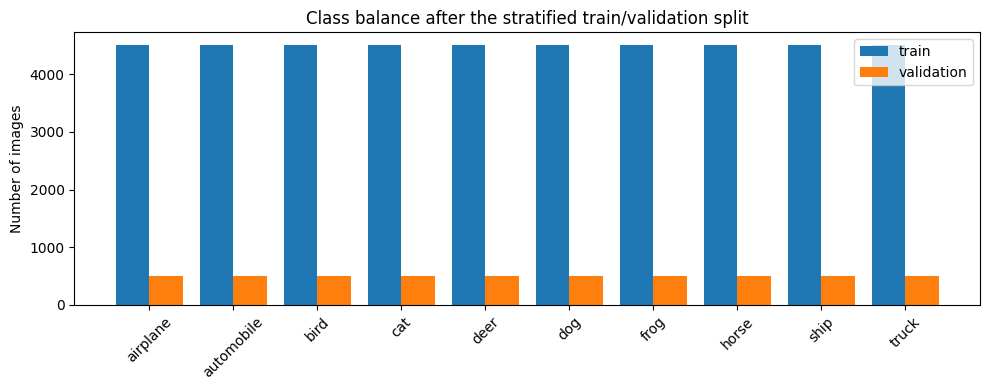

,class_id,class_name,original_pool,train,validation,test
0,0,airplane,5000,4500,500,1000
1,1,automobile,5000,4500,500,1000
2,2,bird,5000,4500,500,1000
3,3,cat,5000,4500,500,1000
4,4,deer,5000,4500,500,1000
5,5,dog,5000,4500,500,1000
6,6,frog,5000,4500,500,1000
7,7,horse,5000,4500,500,1000
8,8,ship,5000,4500,500,1000
9,9,truck,5000,4500,500,1000


All original CIFAR-10 training classes balanced: True
Validation images per class: [500, 500, 500, 500, 500, 500, 500, 500, 500, 500]


In [9]:
def count_classes(labels):
    return np.bincount(
        np.asarray(labels).reshape(-1),
        minlength=NUM_CLASSES,
    )

full_counts = count_classes(y_full)
train_counts = count_classes(y_train)
val_counts = count_classes(y_val)
test_counts = count_classes(y_test)

positions = np.arange(NUM_CLASSES)

plt.figure(figsize=(10, 4))
plt.bar(
    positions - 0.2,
    train_counts,
    width=0.4,
    label="train",
)
plt.bar(
    positions + 0.2,
    val_counts,
    width=0.4,
    label="validation",
)
plt.xticks(
    positions,
    CLASS_NAMES,
    rotation=45,
)
plt.ylabel("Number of images")
plt.title("Class balance after the stratified train/validation split")
plt.legend()
plt.tight_layout()
plt.show()

class_balance_table = pd.DataFrame({
    "class_id": np.arange(NUM_CLASSES),
    "class_name": CLASS_NAMES,
    "original_pool": full_counts,
    "train": train_counts,
    "validation": val_counts,
    "test": test_counts,
})

display(class_balance_table)
print(
    "All original CIFAR-10 training classes balanced:",
    bool(np.all(full_counts == full_counts[0])),
)
print(
    "Validation images per class:",
    val_counts.tolist(),
)

### Evaluation — class balance

The original CIFAR-10 training pool is perfectly balanced, and the
stratified split preserves equal representation in the training and
validation subsets. Therefore, class weighting, oversampling, and
undersampling are unnecessary.

This also supports balanced generation and evaluation: the final 1,000-image set
uses 100 images per class, while the quantitative GAN evaluation uses equal
numbers from all ten requested classes.

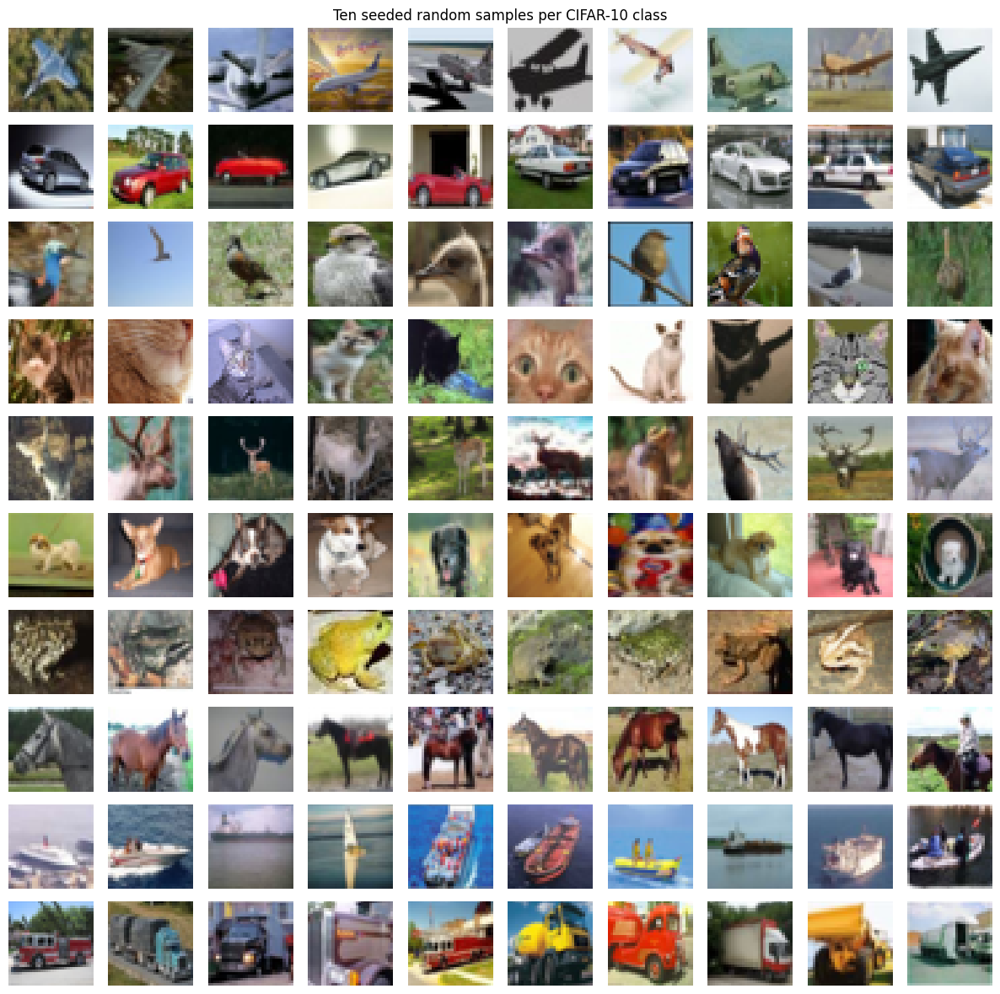

In [10]:
eda_rng = np.random.default_rng(SEED)
samples_per_class = 10

fig, axes = plt.subplots(
    NUM_CLASSES,
    samples_per_class,
    figsize=(12, 12),
)

for class_id in range(NUM_CLASSES):
    class_indices = np.flatnonzero(y_full == class_id)
    chosen_indices = eda_rng.choice(
        class_indices,
        size=samples_per_class,
        replace=False,
    )

    for column, image_index in enumerate(chosen_indices):
        axes[class_id, column].imshow(x_full[image_index])
        axes[class_id, column].axis("off")

        if column == 0:
            axes[class_id, column].set_ylabel(
                CLASS_NAMES[class_id],
                rotation=0,
                ha="right",
                va="center",
                fontsize=8,
            )

fig.suptitle("Ten seeded random samples per CIFAR-10 class")
plt.tight_layout()
plt.show()

### Evaluation — real-image variability

The sample grid shows substantial within-class variation. Objects appear
from different viewpoints, at different positions and scales, and against
varied backgrounds. A successful generator must therefore learn broad
class characteristics rather than memorising a single prototype.

The animal categories also contain considerable variation in pose and body
shape, while several vehicle categories share similar rigid structures.
These are exploratory observations only; final class difficulty is assessed
after model training.

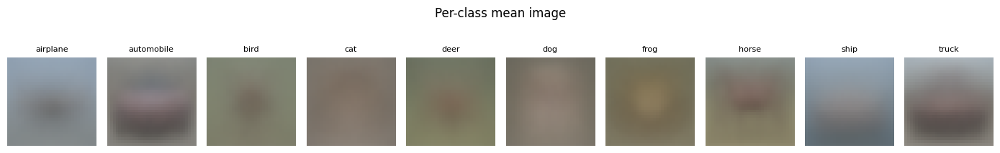

In [11]:
fig, axes = plt.subplots(
    1,
    NUM_CLASSES,
    figsize=(14, 2.4),
)

for class_id in range(NUM_CLASSES):
    class_mean = (
        x_full[y_full == class_id]
        .astype(np.float32)
        .mean(axis=0)
        / 255.0
    )

    axes[class_id].imshow(class_mean)
    axes[class_id].axis("off")
    axes[class_id].set_title(
        CLASS_NAMES[class_id],
        fontsize=8,
    )

fig.suptitle("Per-class mean image")
plt.tight_layout()
plt.show()

### Evaluation — class-average structure

Per-class mean images appear blurred because CIFAR-10 objects are not
spatially aligned. Some categories retain more visible global structure,
while others lose most local details after averaging.

This suggests that classes with more consistent silhouettes or backgrounds
may be easier to model. However, this remains a hypothesis because average
images do not measure generated-image realism, class control, or diversity.
The hypothesis is tested later using per-class conditioning accuracy,
confidence, confusion patterns, generated grids and classifier-based diagnostics.

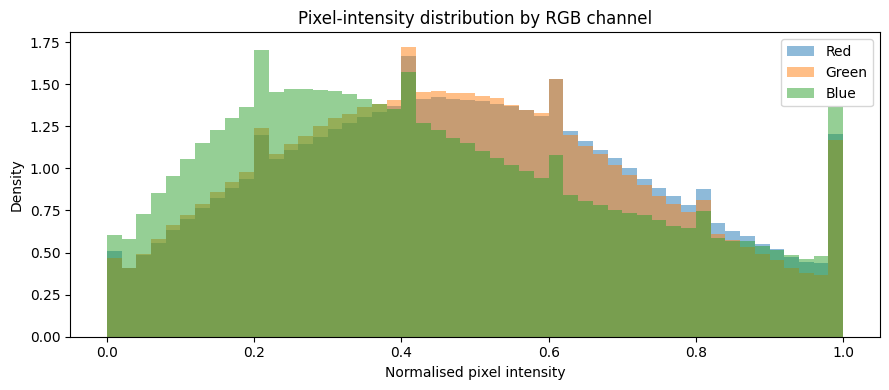

,channel,mean,standard_deviation
0,Red,0.4904,0.2446
1,Green,0.4809,0.2411
2,Blue,0.4447,0.2591


In [12]:
normalised_full = x_full.astype(np.float32) / 255.0
channel_names = ["Red", "Green", "Blue"]

plt.figure(figsize=(9, 4))

# Use a seeded subset to keep the histogram efficient and reproducible.
histogram_indices = eda_rng.choice(
    len(normalised_full),
    size=min(10_000, len(normalised_full)),
    replace=False,
)
histogram_sample = normalised_full[histogram_indices]

for channel_id, channel_name in enumerate(channel_names):
    plt.hist(
        histogram_sample[..., channel_id].ravel(),
        bins=50,
        alpha=0.5,
        density=True,
        label=channel_name,
    )

plt.xlabel("Normalised pixel intensity")
plt.ylabel("Density")
plt.title("Pixel-intensity distribution by RGB channel")
plt.legend()
plt.tight_layout()
plt.show()

flattened_pixels = histogram_sample.reshape(-1, 3)
channel_statistics = pd.DataFrame({
    "channel": channel_names,
    "mean": flattened_pixels.mean(axis=0),
    "standard_deviation": flattened_pixels.std(axis=0),
})

display(channel_statistics.round(4))

### Evaluation — RGB distribution

The RGB channels have broad and overlapping intensity distributions with no
severe channel imbalance or obvious anomaly. Therefore, the baseline keeps
the original RGB information and does not apply extra colour correction.

Colour may provide useful semantic and background cues, so grayscale is
treated as an exploratory comparison rather than the primary training
representation.

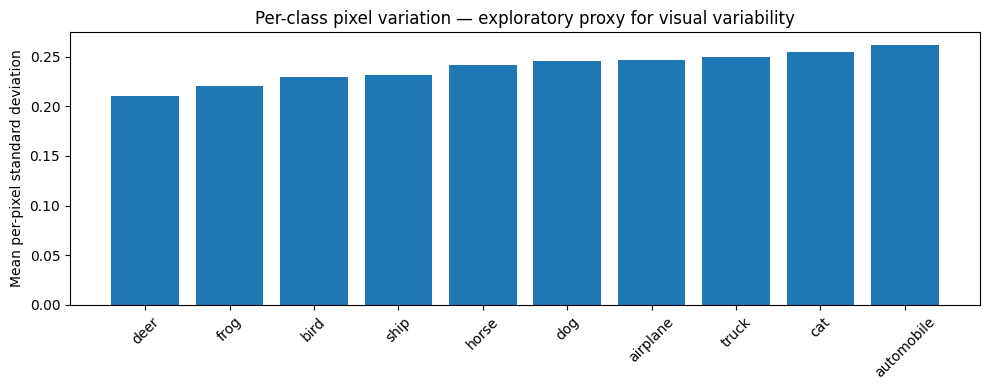

,class_id,class_name,mean_brightness,mean_pixel_std
0,1,automobile,0.457637,0.261379
1,3,cat,0.455811,0.254621
2,9,truck,0.487362,0.249992
3,0,airplane,0.558298,0.246182
4,5,dog,0.460370,0.245682
5,7,horse,0.466236,0.241542
6,8,ship,0.523435,0.231660
7,2,bird,0.468258,0.229102
8,6,frog,0.417890,0.220486
9,4,deer,0.438335,0.210310


In [13]:
variation_rows = []

for class_id, class_name in enumerate(CLASS_NAMES):
    class_images = (
        x_full[y_full == class_id]
        .astype(np.float32)
        / 255.0
    )

    variation_rows.append({
        "class_id": class_id,
        "class_name": class_name,
        "mean_brightness": float(class_images.mean()),
        "mean_pixel_std": float(
            class_images.std(axis=0).mean()
        ),
    })

eda_variation = pd.DataFrame(variation_rows)
ordered_variation = eda_variation.sort_values(
    "mean_pixel_std",
    ascending=True,
)

plt.figure(figsize=(10, 4))
plt.bar(
    ordered_variation["class_name"],
    ordered_variation["mean_pixel_std"],
)
plt.xticks(rotation=45)
plt.ylabel("Mean per-pixel standard deviation")
plt.title(
    "Per-class pixel variation — exploratory proxy for visual variability"
)
plt.tight_layout()
plt.show()

display(
    eda_variation.sort_values(
        "mean_pixel_std",
        ascending=False,
    ).reset_index(drop=True)
)

### Evaluation — exploratory class variability

Mean per-pixel standard deviation is only a rough proxy for visual
variability. It is affected by lighting, background, colour, object
position, alignment, and viewpoint—not only semantic class difficulty.

Therefore, this ranking is used to form hypotheses rather than to declare
the easiest or hardest class. Final conclusions must be supported by
generated-image evaluation.

## Exploratory feature-engineering candidates

Grayscale conversion and mild sharpening are visualised to understand how
they alter CIFAR-10 images. They are **not applied to the primary VAE or GAN
training data**, because doing so would change the original data
distribution and introduce another experimental variable.

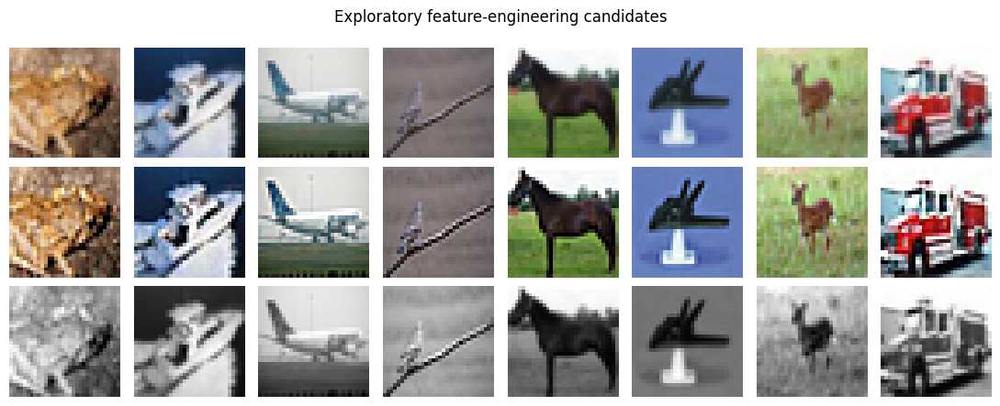

Mean Laplacian sharpness — original: 0.03570 | sharpened: 0.11540
Relative increase: 223.3%


In [14]:
def eda_conv3x3(gray_image, kernel):
    padded = np.pad(
        gray_image,
        1,
        mode="edge",
    )
    output = np.zeros_like(
        gray_image,
        dtype=np.float32,
    )

    for row_offset in range(3):
        for column_offset in range(3):
            output += (
                kernel[row_offset, column_offset]
                * padded[
                    row_offset:row_offset + gray_image.shape[0],
                    column_offset:column_offset + gray_image.shape[1],
                ]
            )

    return output


def eda_to_gray(image_01):
    weights = np.array(
        [0.299, 0.587, 0.114],
        dtype=np.float32,
    )
    return image_01 @ weights


def eda_unsharp(image_01, amount=1.0):
    blur_kernel = (
        np.ones((3, 3), dtype=np.float32) / 9.0
    )
    blurred = np.stack([
        eda_conv3x3(
            image_01[..., channel_id],
            blur_kernel,
        )
        for channel_id in range(3)
    ], axis=-1)

    return np.clip(
        image_01 + amount * (image_01 - blurred),
        0.0,
        1.0,
    )


def eda_sharpness(image_01):
    laplacian_kernel = np.array(
        [
            [0, 1, 0],
            [1, -4, 1],
            [0, 1, 0],
        ],
        dtype=np.float32,
    )

    return float(
        eda_conv3x3(
            eda_to_gray(image_01),
            laplacian_kernel,
        ).var()
    )


feature_indices = eda_rng.choice(
    len(x_full),
    size=8,
    replace=False,
)
feature_samples = (
    x_full[feature_indices]
    .astype(np.float32)
    / 255.0
)

fig, axes = plt.subplots(
    3,
    len(feature_samples),
    figsize=(11, 4.5),
)

for column, image in enumerate(feature_samples):
    axes[0, column].imshow(image)
    axes[1, column].imshow(eda_unsharp(image))
    axes[2, column].imshow(
        eda_to_gray(image),
        cmap="gray",
    )

    for row in range(3):
        axes[row, column].axis("off")

axes[0, 0].set_ylabel(
    "Original",
    rotation=0,
    ha="right",
    va="center",
)
axes[1, 0].set_ylabel(
    "Sharpened",
    rotation=0,
    ha="right",
    va="center",
)
axes[2, 0].set_ylabel(
    "Grayscale",
    rotation=0,
    ha="right",
    va="center",
)

fig.suptitle(
    "Exploratory feature-engineering candidates"
)
plt.tight_layout()
plt.show()

sharpness_subset = (
    x_full[:500]
    .astype(np.float32)
    / 255.0
)

original_sharpness = np.mean([
    eda_sharpness(image)
    for image in sharpness_subset
])
sharpened_sharpness = np.mean([
    eda_sharpness(eda_unsharp(image))
    for image in sharpness_subset
])

print(
    "Mean Laplacian sharpness — "
    f"original: {original_sharpness:.5f} | "
    f"sharpened: {sharpened_sharpness:.5f}"
)

if original_sharpness > 0:
    print(
        "Relative increase:",
        f"{100 * (sharpened_sharpness - original_sharpness) / original_sharpness:.1f}%"
    )

### Evaluation — feature-engineering candidates

Mild sharpening increases edge contrast and the Laplacian sharpness score,
while grayscale removes colour information and reduces each image to one
intensity channel.

These transformations were not used in the primary experiments:

- sharpening modifies the natural CIFAR-10 distribution and could train the
  model to imitate processed rather than original images;
- grayscale lowers output dimensionality but removes colour cues that may
  help distinguish visually similar categories;
- keeping the original RGB data makes comparisons with the shared models
  and evaluation reference more direct.

Sharpening and grayscale remain valid future-work or screening directions,
but they are not mixed into the controlled beta, generator-refinement, and
capacity-scaling experiments.

### Data augmentation consideration

Data augmentation was considered as a possible way to increase training
diversity. However, augmentation was not used in the primary experiments
because the objective is to learn the original CIFAR-10 distribution, and
adding transformations would introduce another factor into the controlled
model comparisons.

CIFAR-10 already contains substantial variation in object position,
viewpoint, colour, and background. Moderate augmentation may still be
investigated as future work, but no claim is made here that augmentation
would improve or worsen the current models.

## EDA conclusions and links to the experiments

| EDA finding | Implication | Response in this notebook |
|---|---|---|
| Classes are balanced | No resampling or class weighting is needed | Generate and evaluate equal numbers per class |
| Images are only 32 × 32 | Fine details are difficult to preserve | Use moderate convolutional architectures designed for three resolution changes |
| Within-class variation is substantial | Diversity and mode collapse must be checked | Report duplicate behaviour, generated grids, and class-wise performance |
| RGB channels contain broad useful variation | Colour cues may support recognisability | Retain RGB for primary training and discuss grayscale separately |
| GAN performance may depend on generator/discriminator update speeds | Equal learning rates may not give the best stability | Test TTUR in `CF-GAN-A1-TTUR` |
| Class-average structures differ | Generation difficulty may vary by class | Use per-class conditioning accuracy, confidence, confusion patterns and fixed-seed generated grids |
| Preprocessing changes alter the data distribution | Effects should not be mixed with architecture changes | Keep original images for the controlled VAE and supporting TTUR experiments |

### Final preprocessing decisions

| Decision | Choice | Reason |
|---|---|---|
| Main image mode | RGB | Preserves colour information from the original dataset |
| VAE range | `[0,1]` | Matches the sigmoid decoder |
| GAN range | `[-1,1]` | Matches the tanh generator |
| Validation set | 5,000 images from the shared stratified `train_test_split` | Supports balanced and reproducible model selection |
| Augmentation | Not used in primary experiments | Avoids an additional uncontrolled factor |
| Sharpening | Exploratory only | Changes the source-image distribution |
| Architecture depth | Three resolution-changing stages | Appropriate for 32 × 32 images |

In [15]:
# VAE arrays remain in [0, 1] because later classifier and latent-analysis
# cells use them directly.
x_train_vae = x_train_uint8.astype(np.float32) / 255.0
x_val_vae = x_val_uint8.astype(np.float32) / 255.0
x_test_vae = x_test_uint8.astype(np.float32) / 255.0


def make_vae_dataset(
    images_01,
    labels,
    batch_size,
    training,
):
    labels = np.asarray(labels, dtype=np.int32)

    # Keep the complete source arrays on CPU.
    with tf.device("/CPU:0"):
        dataset = tf.data.Dataset.from_tensor_slices(
            (images_01, labels)
        )

    if training:
        dataset = dataset.shuffle(
            buffer_size=min(len(images_01), 20_000),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    return (
        dataset
        .batch(batch_size, drop_remainder=training)
        .prefetch(1)
    )


def make_gan_dataset_from_uint8(
    images_uint8,
    labels,
    batch_size,
    training,
):
    '''
    Keep the full CIFAR-10 array as uint8 on CPU and convert only one
    sample/batch at a time to the GAN range [-1, 1].
    '''
    images_uint8 = np.asarray(images_uint8, dtype=np.uint8)
    labels = np.asarray(labels, dtype=np.int32)

    with tf.device("/CPU:0"):
        dataset = tf.data.Dataset.from_tensor_slices(
            (images_uint8, labels)
        )

    if training:
        dataset = dataset.shuffle(
            buffer_size=min(len(images_uint8), 20_000),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    def preprocess(image, label):
        image = tf.cast(image, tf.float32)
        image = image / 127.5 - 1.0
        return image, label

    return (
        dataset
        .map(preprocess, num_parallel_calls=1)
        .batch(batch_size, drop_remainder=training)
        .prefetch(1)
    )


vae_train_ds = make_vae_dataset(
    x_train_vae,
    y_train,
    BATCH_SIZE,
    True,
)
vae_val_ds = make_vae_dataset(
    x_val_vae,
    y_val,
    BATCH_SIZE,
    False,
)

# No full float32 x_train_gan copy is created.
gan_train_ds = make_gan_dataset_from_uint8(
    x_train_uint8,
    y_train,
    BATCH_SIZE,
    True,
)

fixed_labels = tf.repeat(
    tf.range(NUM_CLASSES, dtype=tf.int32),
    repeats=10,
)
fixed_vae_noise = tf.random.stateless_normal(
    (100, VAE_LATENT_DIM),
    seed=(SEED, 1),
)
fixed_gan_noise = tf.random.stateless_normal(
    (100, GAN_LATENT_DIM),
    seed=(SEED, 2),
)

print("VAE datasets use [0, 1] float32 images.")
print("GAN source images remain uint8 on CPU and are scaled batchwise.")


VAE datasets use [0, 1] float32 images.
GAN source images remain uint8 on CPU and are scaled batchwise.


In [16]:
def ensure_01(images):
    images = np.asarray(images, dtype=np.float32)
    if images.min() < -0.05:
        images = (images + 1.0) / 2.0
    return np.clip(images, 0.0, 1.0)

def plot_generated_by_class(images, labels, title, samples_per_class=10):
    images = ensure_01(images)
    labels = np.asarray(labels).reshape(-1)
    fig, axes = plt.subplots(
        NUM_CLASSES, samples_per_class,
        figsize=(samples_per_class * 1.25, NUM_CLASSES * 1.2)
    )
    for class_id in range(NUM_CLASSES):
        class_images = images[labels == class_id][:samples_per_class]
        for column in range(samples_per_class):
            axes[class_id, column].imshow(class_images[column])
            axes[class_id, column].axis("off")
            if column == 0:
                axes[class_id, column].set_title(
                    CLASS_NAMES[class_id], loc="left", fontsize=8
                )
    fig.suptitle(title, y=1.002)
    plt.tight_layout()
    plt.show()

def _safe_review_filename(text):
    text = re.sub(r"[^A-Za-z0-9._-]+", "_", str(text)).strip("_")
    return text[:160] or "figure"


def plot_history(history, keys, title):
    # Training histories are saved as JSON, so this plot can be reproduced
    # without retraining. Save a PNG as well for the persistent review section.
    fig = plt.figure(figsize=(9, 5))
    for key in keys:
        if key in history:
            plt.plot(history[key], label=key)
    plt.xlabel("Epoch")
    plt.ylabel("Metric")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    fig.savefig(
        REVIEW_FIGURE_DIR / f"{_safe_review_filename(title)}.png",
        dpi=170,
        bbox_inches="tight",
    )
    plt.show()

def save_image_grid(images, labels, path, samples_per_class=10):
    images = ensure_01(images)
    labels = np.asarray(labels).reshape(-1)
    fig, axes = plt.subplots(
        NUM_CLASSES, samples_per_class,
        figsize=(samples_per_class, NUM_CLASSES)
    )
    for class_id in range(NUM_CLASSES):
        class_images = images[labels == class_id][:samples_per_class]
        for column in range(samples_per_class):
            axes[class_id, column].imshow(class_images[column])
            axes[class_id, column].axis("off")
    plt.tight_layout()
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.close(fig)

def exact_duplicate_rate(images):
    images_uint8 = np.rint(
        ensure_01(images) * 255.0
    ).astype(np.uint8)
    hashes = [
        hashlib.sha1(image.tobytes()).hexdigest()
        for image in images_uint8
    ]
    return 1.0 - len(set(hashes)) / len(hashes)


# 4. Shared evaluation classifier

A separate CIFAR-10 classifier is trained only on real training images. Its real test accuracy is reported before it is used to estimate requested-class accuracy on generated images.

The classifier is an evaluation aid, not perfect ground truth.

In [17]:
def build_evaluation_classifier():
    inputs = keras.Input(shape=IMAGE_SHAPE)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(0.2)(x)

    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Conv2D(256, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name="cifar10_evaluation_classifier")
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

classifier = build_evaluation_classifier()
classifier_weights = CHECKPOINT_DIR / "evaluation_classifier.weights.h5"

if TRAIN_EVAL_CLASSIFIER:
    callbacks = [
        keras.callbacks.ModelCheckpoint(
            classifier_weights,
            monitor="val_accuracy",
            save_best_only=True,
            save_weights_only=True,
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_accuracy",
            patience=6,
            restore_best_weights=True,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=1e-5,
        ),
    ]
    classifier.fit(
        x_train_vae,
        y_train,
        validation_data=(x_val_vae, y_val),
        epochs=35,
        batch_size=BATCH_SIZE,
        callbacks=callbacks,
        verbose=2,
    )
elif classifier_weights.exists():
    classifier.load_weights(classifier_weights)
    print("Loaded:", classifier_weights)
else:
    print("Classifier weights not found. Set TRAIN_EVAL_CLASSIFIER=True once.")

if classifier_weights.exists() or TRAIN_EVAL_CLASSIFIER:
    _, test_accuracy = classifier.evaluate(
        x_test_vae, y_test, batch_size=BATCH_SIZE, verbose=0
    )
    print(f"Evaluation classifier real test accuracy: {test_accuracy:.4f}")

# This classifier is the independent final judge. It is never used as a
# training signal for A4 or A5.
classifier.trainable = False


Loaded: chun_fei_ca2_yx_split/checkpoints/evaluation_classifier.weights.h5


Evaluation classifier real test accuracy: 0.8625


In [18]:
def evaluate_conditioning(
    images,
    requested_labels,
    classifier_model,
    batch_size=128,
    show_confusion=True,
):
    images = ensure_01(images)
    requested_labels = np.asarray(requested_labels).reshape(-1).astype(np.int32)

    probabilities = classifier_model.predict(
        images, batch_size=batch_size, verbose=0
    )
    predictions = probabilities.argmax(axis=1)
    confidence = probabilities.max(axis=1)

    # Probability assigned specifically to each requested class.
    requested_confidence = probabilities[
        np.arange(len(requested_labels)),
        requested_labels,
    ]

    overall_accuracy = float(np.mean(predictions == requested_labels))
    per_class_accuracy = {}
    for class_id, class_name in enumerate(CLASS_NAMES):
        mask = requested_labels == class_id
        per_class_accuracy[class_name] = float(
            np.mean(predictions[mask] == class_id)
        )

    cm = confusion_matrix(
        requested_labels,
        predictions,
        labels=np.arange(NUM_CLASSES),
    )

    if show_confusion:
        display = ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES)
        fig, ax = plt.subplots(figsize=(10, 9))
        display.plot(ax=ax, xticks_rotation=45, colorbar=False)
        ax.set_title("Requested class versus classifier prediction")
        plt.tight_layout()
        plt.show()

    return {
        "overall_accuracy": overall_accuracy,
        "per_class_accuracy": per_class_accuracy,
        "mean_confidence": float(confidence.mean()),
        "mean_requested_confidence": float(requested_confidence.mean()),
        "confusion_matrix": cm,
        "predictions": predictions,
    }

## Separate training-only classifier for A4 and A5

A4 and A5 do not optimise against the shared evaluation classifier. Instead,
they use a second frozen classifier with a different architecture.

```text
Class-consistency helper:
real training images → frozen semantic training signal for A4/A5

Shared evaluation classifier:
never used by A4/A5 → independent final scoring
```

This separation prevents the final conditioning metric from becoming
circular. The helper is trained only on the real 45,000-image training split
and selected using the 5,000-image validation split.

A4 and A5 use the exact same saved helper weights. The helper is not retrained
for A5.

In [19]:
def build_class_consistency_helper():
    """
    A separate CIFAR-10 classifier used only to provide gradients to A4 and A5.

    Its architecture is intentionally different from the shared evaluation
    classifier so final conditioning accuracy remains an independent test.
    """
    inputs = keras.Input(
        shape=IMAGE_SHAPE,
        name="helper_image",
    )

    x = layers.Conv2D(
        48,
        3,
        padding="same",
        activation="relu",
    )(inputs)
    x = layers.Conv2D(
        48,
        3,
        padding="same",
        activation="relu",
    )(x)
    x = layers.MaxPooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.20)(x)

    x = layers.Conv2D(
        96,
        3,
        padding="same",
        activation="relu",
    )(x)
    x = layers.Conv2D(
        96,
        3,
        padding="same",
        activation="relu",
    )(x)
    x = layers.MaxPooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.30)(x)

    x = layers.Conv2D(
        192,
        3,
        padding="same",
        activation="relu",
    )(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(
        128,
        activation="relu",
    )(x)
    x = layers.Dropout(0.35)(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax",
        name="helper_class_probabilities",
    )(x)

    model = keras.Model(
        inputs,
        outputs,
        name="class_consistency_helper",
    )
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


class_consistency_helper = (
    build_class_consistency_helper()
)
class_helper_weights = (
    CHECKPOINT_DIR
    / "class_consistency_helper.weights.h5"
)

if TRAIN_CLASS_HELPER:
    helper_callbacks = [
        keras.callbacks.ModelCheckpoint(
            class_helper_weights,
            monitor="val_accuracy",
            save_best_only=True,
            save_weights_only=True,
            mode="max",
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_accuracy",
            patience=6,
            restore_best_weights=True,
            mode="max",
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=1e-5,
            mode="min",
        ),
    ]

    class_consistency_helper.fit(
        x_train_vae,
        y_train,
        validation_data=(
            x_val_vae,
            y_val,
        ),
        epochs=CLASS_HELPER_EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=helper_callbacks,
        verbose=2,
    )

    # Reload the checkpoint selected by validation accuracy.
    if class_helper_weights.exists():
        class_consistency_helper.load_weights(
            class_helper_weights
        )

elif class_helper_weights.exists():
    class_consistency_helper.load_weights(
        class_helper_weights
    )
    print(
        "Loaded class-consistency helper:",
        class_helper_weights,
    )
else:
    print(
        "Class-consistency helper weights not found. "
        "Set TRAIN_CLASS_HELPER=True before training A4 or A5."
    )

if (
    class_helper_weights.exists()
    or TRAIN_CLASS_HELPER
):
    _, helper_test_accuracy = (
        class_consistency_helper.evaluate(
            x_test_vae,
            y_test,
            batch_size=BATCH_SIZE,
            verbose=0,
        )
    )
    print(
        "Class-consistency helper real test accuracy:",
        f"{helper_test_accuracy:.4f}",
    )

# Freeze all helper weights. Gradients can still flow through the helper
# to generated images, but the helper itself will not be updated by A4 or A5.
class_consistency_helper.trainable = False

Loaded class-consistency helper: chun_fei_ca2_yx_split/checkpoints/class_consistency_helper.weights.h5


Class-consistency helper real test accuracy: 0.8571


# 5. Controlled VAE experiment chain

A2 is a rejected side branch. A4 and A5 are parallel class-loss weight
experiments built from the same clean A3 model design.

| Model | Parent | Warm-up | Free bits | Multi-stage conditioning | Class-loss weight |
|---|---|---:|---:|---:|---:|
| `CF-VAE-A0-BL` | — | None | None | No | 0 |
| `CF-VAE-A1-KLW` | A0 | 20 epochs | None | No | 0 |
| `CF-VAE-A2-FB` | A1 | 20 epochs | 0.125 nats/dim | No | 0 |
| `CF-VAE-A3-MSC-CLEAN` | A1 | 20 epochs | None | Yes | 0 |
| `CF-VAE-A4-CCL` | A3 | 20 epochs | None | Yes | 1.00 |
| `CF-VAE-A5-CCL025` | A3 | 20 epochs | None | Yes | 0.25 |

## Literature basis for the VAE experiment chain

### A0 baseline — VAE objective

**Kingma and Welling (2013), *Auto-Encoding Variational Bayes*.** The
variational objective used in `CF-VAE-A0-BL` was adapted from this paper. Our
encoder predicts `z_mean` and `z_log_var`, latent samples are obtained through
reparameterisation, and training combines reconstruction loss with raw KL
divergence. A0 therefore provides the literature-based VAE baseline from which
the later controlled variants are developed.  
**Source:** [arXiv:1312.6114](https://arxiv.org/abs/1312.6114)

### A1 — KL warm-up

**Bowman et al. (2015), *Generating Sentences from a Continuous Space*.** The
KL warm-up strategy used in `CF-VAE-A1-KLW` was adapted from the paper's
**KL cost annealing** method in Section 3.1, where the weight on the KL term
starts small and increases during training. In our implementation, `beta`
increases linearly to 1.0 over the first 20 epochs so reconstruction learning
can begin before full KL regularisation is applied. The exact 20-epoch linear
schedule is our experimental choice.  
**Source:** [arXiv:1511.06349](https://arxiv.org/abs/1511.06349)

### A2 — free bits

**Kingma et al. (2016), *Improving Variational Inference with Inverse
Autoregressive Flow*.** The free-bits mechanism tested in `CF-VAE-A2-FB` was
adapted from the paper's **Objective with Free Bits** in Appendix C.8. The
method prevents the model from being rewarded for reducing latent information
below a chosen allowance. In our notebook, A2 uses a threshold of `0.125`
nats per latent dimension and then checks how often the floor is actually
active. The resulting diagnostic shows that it is almost never active, so the
technique is rejected for this model.  
**Source:** [arXiv:1606.04934](https://arxiv.org/abs/1606.04934)

### A3 — multi-stage conditioning

**Mirza and Osindero (2014), *Conditional Generative Adversarial Nets*.** The
general conditioning principle used in A3 is related to the paper's method of
providing class information as an additional input to a generative model. In
our VAE, we extend that principle by re-injecting the learned label
representation at 8 × 8, 16 × 16 and 32 × 32 decoder stages. The repeated
multi-stage injection is therefore **our own VAE architecture design**, not a
method claimed to come directly from the paper.  
**Source:** [arXiv:1411.1784](https://arxiv.org/abs/1411.1784)

### A4/A5 — auxiliary class consistency

The auxiliary class-consistency objective used in A4 and A5 is a
**project-specific controlled extension**. A frozen helper classifier supplies
a class-correctness loss for posterior reconstructions and prior generations,
while the separate shared evaluation classifier remains independent. A4 uses
`lambda_class = 1.00` and A5 uses `0.25`; these weights are our own
experimental choices rather than values attributed to an external paper.

## Baseline architecture

**Encoder**

```text
image + spatial class map
→ Conv 32 → Conv 64 → Conv 128
→ Dense 256
→ z_mean, z_log_var, sampled z
```

**Decoder**

```text
z + class embedding
→ Dense 4×4×128
→ ConvTranspose 128 → 64 → 32
→ sigmoid RGB output
```

A3, A4 and A5 use the same multi-stage decoder. The learned class map is
reintroduced after the 8×8, 16×16 and 32×32 decoder stages.

## Auxiliary class-consistency objective

A4 and A5 use:

\[
L
=
L_{\text{reconstruction}}
+
\beta L_{\text{KL}}
+
\lambda_{\text{class}}L_{\text{class}}.
\]

The class term averages:

1. correct-class cross-entropy on posterior reconstructions;
2. correct-class cross-entropy on standard-normal prior generations.

The only A4-versus-A5 change is:

```text
A4: λclass = 1.00
A5: λclass = 0.25
```

The shared evaluation classifier is never used in this objective.

## Why A5 was tested

A4 demonstrated that explicit semantic supervision greatly improved class
control but introduced a substantial FID penalty. A5 was therefore trained to
test whether weaker semantic pressure could retain part of the conditioning
gain while allowing greater emphasis on reconstruction and latent
regularisation.

The completed results show that A5 partially recovered FID relative to A4,
but lost a considerable amount of conditioning accuracy and requested-class
confidence and produced the lowest VAE Inception Score. A5 is retained as a
controlled weight-sensitivity result, not selected as the final VAE.

## Metric interpretation

- `raw_kl_loss` measures actual latent KL information.
- `effective_kl_loss` differs only for A2, which uses free bits.
- `class_consistency_loss` is non-zero only for A4 and A5.
- A3, A4 and A5 total losses are not directly comparable because their
  weighted objectives differ.

In [20]:
@keras.utils.register_keras_serializable(package="CA2")
class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        epsilon = tf.random.normal(tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon


def build_cf_vae_encoder(
    latent_dim=VAE_LATENT_DIM,
    name="CF_VAE_encoder",
):
    image_input = keras.Input(
        shape=IMAGE_SHAPE,
        name="image",
    )
    label_input = keras.Input(
        shape=(),
        dtype="int32",
        name="label",
    )

    label_embedding = layers.Embedding(
        NUM_CLASSES,
        16,
        name="encoder_label_embedding",
    )(label_input)
    label_map = layers.Dense(
        32 * 32,
        activation="relu",
        name="encoder_label_map_dense",
    )(label_embedding)
    label_map = layers.Reshape(
        (32, 32, 1),
        name="encoder_label_map",
    )(label_map)

    x = layers.Concatenate(name="encoder_conditioning")([
        image_input,
        label_map,
    ])
    x = layers.Conv2D(
        32,
        4,
        strides=2,
        padding="same",
    )(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)

    x = layers.Conv2D(
        64,
        4,
        strides=2,
        padding="same",
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)

    x = layers.Conv2D(
        128,
        4,
        strides=2,
        padding="same",
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)

    x = layers.Flatten()(x)
    x = layers.Dense(256, activation="relu")(x)

    z_mean = layers.Dense(
        latent_dim,
        name="z_mean",
    )(x)
    z_log_var = layers.Dense(
        latent_dim,
        name="z_log_var",
    )(x)
    z = Sampling(name="z")([
        z_mean,
        z_log_var,
    ])

    return keras.Model(
        [image_input, label_input],
        [z_mean, z_log_var, z],
        name=name,
    )


def _decoder_label_map(
    label_embedding,
    resolution,
    prefix,
):
    label_map = layers.Dense(
        resolution * resolution,
        activation="relu",
        name=f"{prefix}_dense",
    )(label_embedding)
    return layers.Reshape(
        (resolution, resolution, 1),
        name=f"{prefix}_reshape",
    )(label_map)


def build_cf_vae_decoder(
    latent_dim=VAE_LATENT_DIM,
    multi_stage_conditioning=False,
    name="CF_VAE_decoder",
):
    latent_input = keras.Input(
        shape=(latent_dim,),
        name="latent",
    )
    label_input = keras.Input(
        shape=(),
        dtype="int32",
        name="label",
    )

    label_embedding = layers.Embedding(
        NUM_CLASSES,
        16,
        name="decoder_label_embedding",
    )(label_input)

    x = layers.Concatenate(name="decoder_initial_conditioning")([
        latent_input,
        label_embedding,
    ])
    x = layers.Dense(
        4 * 4 * 128,
        activation="relu",
    )(x)
    x = layers.Reshape((4, 4, 128))(x)

    x = layers.Conv2DTranspose(
        128,
        4,
        strides=2,
        padding="same",
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    if multi_stage_conditioning:
        label_map_8 = _decoder_label_map(
            label_embedding,
            resolution=8,
            prefix="decoder_label_map_8",
        )
        x = layers.Concatenate(
            name="decoder_conditioning_8"
        )([x, label_map_8])

    x = layers.Conv2DTranspose(
        64,
        4,
        strides=2,
        padding="same",
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    if multi_stage_conditioning:
        label_map_16 = _decoder_label_map(
            label_embedding,
            resolution=16,
            prefix="decoder_label_map_16",
        )
        x = layers.Concatenate(
            name="decoder_conditioning_16"
        )([x, label_map_16])

    x = layers.Conv2DTranspose(
        32,
        4,
        strides=2,
        padding="same",
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    if multi_stage_conditioning:
        label_map_32 = _decoder_label_map(
            label_embedding,
            resolution=32,
            prefix="decoder_label_map_32",
        )
        x = layers.Concatenate(
            name="decoder_conditioning_32"
        )([x, label_map_32])

    output = layers.Conv2D(
        3,
        3,
        padding="same",
        activation="sigmoid",
        name="reconstruction",
    )(x)

    return keras.Model(
        [latent_input, label_input],
        output,
        name=name,
    )

In [21]:
@keras.utils.register_keras_serializable(package="CA2")
class ConditionalVAE(keras.Model):
    def __init__(
        self,
        encoder,
        decoder,
        target_beta=1.0,
        warmup_epochs=0,
        free_bits_per_dim=0.0,
        reconstruction_type="mse",
        class_consistency_weight=0.0,
        class_consistency_prior_fraction=0.0,
        class_helper_model=None,
        **kwargs,
    ):
        super().__init__(**kwargs)

        if reconstruction_type not in {
            "mse",
            "bce",
        }:
            raise ValueError(
                "reconstruction_type must be 'mse' or 'bce'."
            )
        if target_beta < 0:
            raise ValueError(
                "target_beta must be non-negative."
            )
        if warmup_epochs < 0:
            raise ValueError(
                "warmup_epochs must be non-negative."
            )
        if free_bits_per_dim < 0:
            raise ValueError(
                "free_bits_per_dim must be non-negative."
            )
        if class_consistency_weight < 0:
            raise ValueError(
                "class_consistency_weight must be non-negative."
            )
        if not (
            0.0
            <= class_consistency_prior_fraction
            <= 1.0
        ):
            raise ValueError(
                "class_consistency_prior_fraction must be "
                "between 0 and 1."
            )
        if (
            class_consistency_weight > 0.0
            and class_helper_model is None
        ):
            raise ValueError(
                "A frozen class helper is required when "
                "class_consistency_weight is positive."
            )

        self.encoder = encoder
        self.decoder = decoder
        self.target_beta = float(
            target_beta
        )
        self.warmup_epochs = int(
            warmup_epochs
        )
        self.free_bits_per_dim = float(
            free_bits_per_dim
        )
        self.reconstruction_type = (
            reconstruction_type
        )
        self.class_consistency_weight = float(
            class_consistency_weight
        )
        self.class_consistency_prior_fraction = float(
            class_consistency_prior_fraction
        )
        self.class_helper_model = (
            class_helper_model
        )

        if self.class_helper_model is not None:
            self.class_helper_model.trainable = False

        initial_beta = (
            self.target_beta
            if self.warmup_epochs == 0
            else 0.0
        )
        self.current_beta = self.add_weight(
            name="current_beta",
            shape=(),
            initializer=keras.initializers.Constant(
                initial_beta
            ),
            trainable=False,
        )

        self.total_loss_tracker = keras.metrics.Mean(
            name="total_loss"
        )
        self.reconstruction_loss_tracker = (
            keras.metrics.Mean(
                name="reconstruction_loss"
            )
        )
        self.raw_kl_loss_tracker = keras.metrics.Mean(
            name="raw_kl_loss"
        )
        self.effective_kl_loss_tracker = (
            keras.metrics.Mean(
                name="effective_kl_loss"
            )
        )
        self.beta_tracker = keras.metrics.Mean(
            name="beta_value"
        )
        self.free_bits_fraction_tracker = (
            keras.metrics.Mean(
                name="free_bits_active_fraction"
            )
        )
        self.class_consistency_loss_tracker = (
            keras.metrics.Mean(
                name="class_consistency_loss"
            )
        )
        self.reconstruction_class_loss_tracker = (
            keras.metrics.Mean(
                name="reconstruction_class_loss"
            )
        )
        self.prior_class_loss_tracker = (
            keras.metrics.Mean(
                name="prior_class_loss"
            )
        )

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.raw_kl_loss_tracker,
            self.effective_kl_loss_tracker,
            self.beta_tracker,
            self.free_bits_fraction_tracker,
            self.class_consistency_loss_tracker,
            self.reconstruction_class_loss_tracker,
            self.prior_class_loss_tracker,
        ]

    def call(
        self,
        inputs,
        training=False,
    ):
        images, labels = inputs
        _, _, z = self.encoder(
            [
                images,
                labels,
            ],
            training=training,
        )
        return self.decoder(
            [
                z,
                labels,
            ],
            training=training,
        )

    def reconstruction_per_sample(
        self,
        images,
        reconstructions,
    ):
        if self.reconstruction_type == "mse":
            values = tf.square(
                images - reconstructions
            )
        else:
            epsilon = keras.backend.epsilon()
            reconstructions = tf.clip_by_value(
                reconstructions,
                epsilon,
                1.0 - epsilon,
            )
            values = -(
                images
                * tf.math.log(
                    reconstructions
                )
                + (
                    1.0 - images
                )
                * tf.math.log(
                    1.0 - reconstructions
                )
            )

        return tf.reduce_sum(
            values,
            axis=(
                1,
                2,
                3,
            ),
        )

    def _classification_loss(
        self,
        images,
        labels,
    ):
        probabilities = self.class_helper_model(
            images,
            training=False,
        )
        per_sample_loss = (
            keras.losses.sparse_categorical_crossentropy(
                labels,
                probabilities,
            )
        )
        return tf.reduce_mean(
            per_sample_loss
        )

    def compute_losses(
        self,
        images,
        labels,
        training,
    ):
        z_mean, z_log_var, z = self.encoder(
            [
                images,
                labels,
            ],
            training=training,
        )
        reconstructions = self.decoder(
            [
                z,
                labels,
            ],
            training=training,
        )

        reconstruction_loss = tf.reduce_mean(
            self.reconstruction_per_sample(
                images,
                reconstructions,
            )
        )

        kl_per_sample_dim = -0.5 * (
            1.0
            + z_log_var
            - tf.square(
                z_mean
            )
            - tf.exp(
                z_log_var
            )
        )

        raw_kl_per_sample = tf.reduce_sum(
            kl_per_sample_dim,
            axis=1,
        )
        raw_kl_loss = tf.reduce_mean(
            raw_kl_per_sample
        )

        mean_kl_per_dim = tf.reduce_mean(
            kl_per_sample_dim,
            axis=0,
        )

        if self.free_bits_per_dim > 0.0:
            effective_kl_per_dim = tf.maximum(
                mean_kl_per_dim,
                tf.cast(
                    self.free_bits_per_dim,
                    mean_kl_per_dim.dtype,
                ),
            )
            free_bits_active_fraction = (
                tf.reduce_mean(
                    tf.cast(
                        mean_kl_per_dim
                        < self.free_bits_per_dim,
                        tf.float32,
                    )
                )
            )
        else:
            effective_kl_per_dim = (
                mean_kl_per_dim
            )
            free_bits_active_fraction = (
                tf.constant(
                    0.0,
                    dtype=tf.float32,
                )
            )

        effective_kl_loss = tf.reduce_sum(
            effective_kl_per_dim
        )

        zero = tf.constant(
            0.0,
            dtype=tf.float32,
        )
        reconstruction_class_loss = zero
        prior_class_loss = zero
        class_consistency_loss = zero

        if self.class_consistency_weight > 0.0:
            reconstruction_class_loss = (
                self._classification_loss(
                    reconstructions,
                    labels,
                )
            )

            prior_z = tf.random.normal(
                tf.shape(
                    z_mean
                ),
                dtype=z_mean.dtype,
            )
            prior_images = self.decoder(
                [
                    prior_z,
                    labels,
                ],
                training=training,
            )
            prior_class_loss = (
                self._classification_loss(
                    prior_images,
                    labels,
                )
            )

            prior_fraction = tf.cast(
                self.class_consistency_prior_fraction,
                tf.float32,
            )
            class_consistency_loss = (
                (
                    1.0 - prior_fraction
                )
                * reconstruction_class_loss
                + prior_fraction
                * prior_class_loss
            )

        total_loss = (
            reconstruction_loss
            + self.current_beta
            * effective_kl_loss
            + tf.cast(
                self.class_consistency_weight,
                tf.float32,
            )
            * class_consistency_loss
        )

        return {
            "total_loss": total_loss,
            "reconstruction_loss": (
                reconstruction_loss
            ),
            "raw_kl_loss": raw_kl_loss,
            "effective_kl_loss": (
                effective_kl_loss
            ),
            "free_bits_active_fraction": (
                free_bits_active_fraction
            ),
            "class_consistency_loss": (
                class_consistency_loss
            ),
            "reconstruction_class_loss": (
                reconstruction_class_loss
            ),
            "prior_class_loss": (
                prior_class_loss
            ),
        }

    def _update_trackers(
        self,
        losses,
    ):
        self.total_loss_tracker.update_state(
            losses[
                "total_loss"
            ]
        )
        self.reconstruction_loss_tracker.update_state(
            losses[
                "reconstruction_loss"
            ]
        )
        self.raw_kl_loss_tracker.update_state(
            losses[
                "raw_kl_loss"
            ]
        )
        self.effective_kl_loss_tracker.update_state(
            losses[
                "effective_kl_loss"
            ]
        )
        self.beta_tracker.update_state(
            self.current_beta
        )
        self.free_bits_fraction_tracker.update_state(
            losses[
                "free_bits_active_fraction"
            ]
        )
        self.class_consistency_loss_tracker.update_state(
            losses[
                "class_consistency_loss"
            ]
        )
        self.reconstruction_class_loss_tracker.update_state(
            losses[
                "reconstruction_class_loss"
            ]
        )
        self.prior_class_loss_tracker.update_state(
            losses[
                "prior_class_loss"
            ]
        )

    def train_step(
        self,
        data,
    ):
        images, labels = data

        with tf.GradientTape() as tape:
            losses = self.compute_losses(
                images,
                labels,
                training=True,
            )

        gradients = tape.gradient(
            losses[
                "total_loss"
            ],
            self.trainable_weights,
        )
        gradient_pairs = [
            (
                gradient,
                variable,
            )
            for gradient, variable in zip(
                gradients,
                self.trainable_weights,
            )
            if gradient is not None
        ]
        self.optimizer.apply_gradients(
            gradient_pairs
        )

        self._update_trackers(
            losses
        )
        return {
            metric.name: metric.result()
            for metric in self.metrics
        }

    def test_step(
        self,
        data,
    ):
        images, labels = data
        losses = self.compute_losses(
            images,
            labels,
            training=False,
        )
        self._update_trackers(
            losses
        )
        return {
            metric.name: metric.result()
            for metric in self.metrics
        }


def build_cf_vae(
    target_beta,
    warmup_epochs,
    free_bits_per_dim,
    multi_stage_conditioning,
    reconstruction_type="mse",
    class_consistency_weight=0.0,
    class_consistency_prior_fraction=0.0,
    latent_dim=VAE_LATENT_DIM,
    name="CF_VAE",
    class_helper_model=None,
):
    safe_name = name.replace(
        "-",
        "_",
    )

    helper_for_model = (
        class_helper_model
        if class_consistency_weight > 0.0
        else None
    )

    model = ConditionalVAE(
        encoder=build_cf_vae_encoder(
            latent_dim=latent_dim,
            name=f"{safe_name}_encoder",
        ),
        decoder=build_cf_vae_decoder(
            latent_dim=latent_dim,
            multi_stage_conditioning=(
                multi_stage_conditioning
            ),
            name=f"{safe_name}_decoder",
        ),
        target_beta=target_beta,
        warmup_epochs=warmup_epochs,
        free_bits_per_dim=(
            free_bits_per_dim
        ),
        reconstruction_type=(
            reconstruction_type
        ),
        class_consistency_weight=(
            class_consistency_weight
        ),
        class_consistency_prior_fraction=(
            class_consistency_prior_fraction
        ),
        class_helper_model=(
            helper_for_model
        ),
        name=safe_name,
    )
    model.compile(
        optimizer=keras.optimizers.Adam(
            2e-4
        )
    )

    dummy_images = tf.zeros(
        (
            1,
            *IMAGE_SHAPE,
        ),
        dtype=tf.float32,
    )
    dummy_labels = tf.zeros(
        (
            1,
        ),
        dtype=tf.int32,
    )
    model(
        [
            dummy_images,
            dummy_labels,
        ]
    )
    return model

In [22]:
VAE_EXPERIMENTS = {
    VAE_A0_ID: {
        "target_beta": 1.0,
        "warmup_epochs": 0,
        "free_bits_per_dim": 0.0,
        "multi_stage_conditioning": False,
        "reconstruction_type": "mse",
        "class_consistency_weight": 0.0,
        "class_consistency_prior_fraction": 0.0,
    },
    VAE_A1_ID: {
        "target_beta": 1.0,
        "warmup_epochs": KL_WARMUP_EPOCHS,
        "free_bits_per_dim": 0.0,
        "multi_stage_conditioning": False,
        "reconstruction_type": "mse",
        "class_consistency_weight": 0.0,
        "class_consistency_prior_fraction": 0.0,
    },
    VAE_A2_ID: {
        "target_beta": 1.0,
        "warmup_epochs": KL_WARMUP_EPOCHS,
        "free_bits_per_dim": FREE_BITS_PER_DIM,
        "multi_stage_conditioning": False,
        "reconstruction_type": "mse",
        "class_consistency_weight": 0.0,
        "class_consistency_prior_fraction": 0.0,
    },
    VAE_A3_ID: {
        "target_beta": 1.0,
        "warmup_epochs": KL_WARMUP_EPOCHS,
        "free_bits_per_dim": 0.0,
        "multi_stage_conditioning": True,
        "reconstruction_type": "mse",
        "class_consistency_weight": 0.0,
        "class_consistency_prior_fraction": 0.0,
    },
    VAE_A4_ID: {
        "target_beta": 1.0,
        "warmup_epochs": KL_WARMUP_EPOCHS,
        "free_bits_per_dim": 0.0,
        "multi_stage_conditioning": True,
        "reconstruction_type": "mse",
        "class_consistency_weight": (
            CLASS_CONSISTENCY_WEIGHT
        ),
        "class_consistency_prior_fraction": (
            CLASS_CONSISTENCY_PRIOR_FRACTION
        ),
    },
    VAE_A5_ID: {
        "target_beta": 1.0,
        "warmup_epochs": KL_WARMUP_EPOCHS,
        "free_bits_per_dim": 0.0,
        "multi_stage_conditioning": True,
        "reconstruction_type": "mse",
        "class_consistency_weight": (
            CLASS_CONSISTENCY_LITE_WEIGHT
        ),
        "class_consistency_prior_fraction": (
            CLASS_CONSISTENCY_PRIOR_FRACTION
        ),
    },
}

demo_parameter_rows = []
demo_models = {}

for model_id, experiment in (
    VAE_EXPERIMENTS.items()
):
    demo_model = build_cf_vae(
        **experiment,
        name=f"{model_id}_demo",
        class_helper_model=(
            class_consistency_helper
        ),
    )
    demo_models[
        model_id
    ] = demo_model
    demo_parameter_rows.append({
        "model_id": model_id,
        "encoder_parameters": (
            demo_model.encoder.count_params()
        ),
        "decoder_parameters": (
            demo_model.decoder.count_params()
        ),
        "total_generative_parameters": (
            demo_model.encoder.count_params()
            + demo_model.decoder.count_params()
        ),
        "warmup_epochs": experiment[
            "warmup_epochs"
        ],
        "free_bits_per_dim": experiment[
            "free_bits_per_dim"
        ],
        "multi_stage_conditioning": experiment[
            "multi_stage_conditioning"
        ],
        "class_consistency_weight": experiment[
            "class_consistency_weight"
        ],
        "class_consistency_prior_fraction": experiment[
            "class_consistency_prior_fraction"
        ],
    })

vae_architecture_table = pd.DataFrame(
    demo_parameter_rows
)
display(
    vae_architecture_table
)

print(
    "\nA0 baseline encoder"
)
demo_models[
    VAE_A0_ID
].encoder.summary()

print(
    "\nA0 baseline decoder"
)
demo_models[
    VAE_A0_ID
].decoder.summary()

print(
    "\nA3/A4/A5 multi-stage decoder"
)
demo_models[
    VAE_A3_ID
].decoder.summary()

del demo_models
gc.collect()

,model_id,encoder_parameters,decoder_parameters,total_generative_parameters,warmup_epochs,free_bits_per_dim,multi_stage_conditioning,class_consistency_weight,class_consistency_prior_fraction
0,CF-VAE-A0-BL,725440,528483,1253923,0,0.000,False,0.00,0.0
1,CF-VAE-A1-KLW,725440,528483,1253923,20,0.000,False,0.00,0.0
2,CF-VAE-A2-FB,725440,528483,1253923,20,0.125,False,0.00,0.0
3,CF-VAE-A3-MSC-CLEAN,725440,552894,1278334,20,0.000,True,0.00,0.0
4,CF-VAE-A4-CCL,725440,552894,1278334,20,0.000,True,1.00,0.5
5,CF-VAE-A5-CCL025,725440,552894,1278334,20,0.000,True,0.25,0.5



A0 baseline encoder


Model: "CF_VAE_A0_BL_demo_encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ label (InputLayer)  │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_label_embe… │ (None, 16)        │        160 │ label[0][0]       │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_label_map_… │ (None, 1024)      │     17,408 │ encoder_label_em… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image (InputLayer)  │ (None, 32, 32, 3) │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_label_map   │ (None, 32, 32, 1) │          0 │ encoder_label_ma… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_conditioni… │ (None, 32, 32, 4) │          0 │ image[0][0],      │
│ (Concatenate)       │                   │            │ encoder_label_ma… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 16, 16,    │      2,080 │ encoder_conditio… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu         │ (None, 16, 16,    │          0 │ conv2d_10[0][0]   │
│ (LeakyReLU)         │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 8, 8, 64)  │     32,832 │ leaky_re_lu[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 8, 8, 64)  │        256 │ conv2d_11[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_1       │ (None, 8, 8, 64)  │          0 │ batch_normalizat… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 4, 4, 128) │    131,200 │ leaky_re_lu_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 4, 4, 128) │        512 │ conv2d_12[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_2       │ (None, 4, 4, 128) │          0 │ batch_normalizat… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 2048)      │          0 │ leaky_re_lu_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 256)       │    524,544 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 32)        │      8,224 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 32)        │      8,224 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z (Sampling)        │ (None, 32)        │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴─────────────────

 Total params: 725,440 (2.77 MB)

...

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ label (InputLayer)  │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ latent (InputLayer) │ (None, 32)        │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_label_embe… │ (None, 16)        │        160 │ label[0][0]       │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_initial_co… │ (None, 48)        │          0 │ latent[0][0],     │
│ (Concatenate)       │                   │            │ decoder_label_em… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 2048)      │    100,352 │ decoder_initial_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_3 (Reshape) │ (None, 4, 4, 128) │          0 │ dense_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_9  │ (None, 8, 8, 128) │    262,272 │ reshape_3[0][0]   │
│ (Conv2DTranspose)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 8, 8, 128) │        512 │ conv2d_transpose… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_label_map_… │ (None, 64)        │      1,088 │ decoder_label_em… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_9 (ReLU)      │ (None, 8, 8, 128) │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_label_map_… │ (None, 8, 8, 1)   │          0 │ decoder_label_ma… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_conditioni… │ (None, 8, 8, 129) │          0 │ re_lu_9[0][0],    │
│ (Concatenate)       │                   │            │ decoder_label_ma… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_10 │ (None, 16, 16,    │    132,160 │ decoder_conditio… │
│ (Conv2DTranspose)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        256 │ conv2d_transpose… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_label_map_… │ (None, 256)       │      4,352 │ decoder_label_em… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_10 (ReLU)     │ (None, 16, 16,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_label_map_… │ (None, 16, 16, 1) │          0 │ decoder_label_ma… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_conditioni… │ (None, 16, 16,    │          0 │ re_lu_10[0][0],   │
│ (Concatenate)       │ 65)               │            │ decoder_label_ma… │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 552,894 (2.11 MB)

 Trainable params: 552,446 (2.11 MB)

 Non-trainable params: 448 (1.75 KB)

59736

In [23]:
class KLWarmupCallback(keras.callbacks.Callback):
    def __init__(
        self,
        target_beta,
        warmup_epochs,
    ):
        super().__init__()
        self.target_beta = float(target_beta)
        self.warmup_epochs = int(warmup_epochs)

    def _beta_for_epoch(self, epoch):
        if self.warmup_epochs <= 0:
            return self.target_beta

        progress = min(
            (epoch + 1) / self.warmup_epochs,
            1.0,
        )
        return self.target_beta * progress

    def on_train_begin(self, logs=None):
        initial_beta = (
            self.target_beta
            if self.warmup_epochs <= 0
            else 0.0
        )
        self.model.current_beta.assign(
            initial_beta
        )

    def on_epoch_begin(self, epoch, logs=None):
        beta_value = self._beta_for_epoch(epoch)
        self.model.current_beta.assign(
            beta_value
        )
        print(
            f"Epoch {epoch + 1}: beta={beta_value:.4f}"
        )

    def on_train_end(self, logs=None):
        self.model.current_beta.assign(
            self.target_beta
        )


class DelayedModelCheckpoint(
    keras.callbacks.ModelCheckpoint
):
    def __init__(
        self,
        start_epoch=1,
        **kwargs,
    ):
        super().__init__(**kwargs)
        self.start_epoch = int(start_epoch)

    def on_epoch_end(self, epoch, logs=None):
        if epoch + 1 < self.start_epoch:
            return
        super().on_epoch_end(epoch, logs)


class DelayedEarlyStopping(
    keras.callbacks.EarlyStopping
):
    def __init__(
        self,
        start_epoch=1,
        **kwargs,
    ):
        super().__init__(**kwargs)
        self.start_epoch = int(start_epoch)

    def on_epoch_end(self, epoch, logs=None):
        if epoch + 1 < self.start_epoch:
            return
        super().on_epoch_end(epoch, logs)


class DelayedReduceLROnPlateau(
    keras.callbacks.ReduceLROnPlateau
):
    def __init__(
        self,
        start_epoch=1,
        **kwargs,
    ):
        super().__init__(**kwargs)
        self.start_epoch = int(start_epoch)

    def on_epoch_end(self, epoch, logs=None):
        if epoch + 1 < self.start_epoch:
            return
        super().on_epoch_end(epoch, logs)


class VAEImageCheckpoint(keras.callbacks.Callback):
    def __init__(
        self,
        model_id,
        noise,
        labels,
        interval=10,
    ):
        super().__init__()
        self.model_id = model_id
        self.noise = noise
        self.labels = labels
        self.interval = int(interval)
        self.model_folder = (
            CHECKPOINT_DIR / model_id
        )
        self.sample_folder = (
            SAMPLE_DIR / model_id
        )
        self.model_folder.mkdir(
            parents=True,
            exist_ok=True,
        )
        self.sample_folder.mkdir(
            parents=True,
            exist_ok=True,
        )

    def on_epoch_end(self, epoch, logs=None):
        epoch_number = epoch + 1

        if epoch_number % self.interval != 0:
            return

        self.model.save_weights(
            self.model_folder
            / f"epoch_{epoch_number:03d}.weights.h5"
        )
        generated = self.model.decoder(
            [self.noise, self.labels],
            training=False,
        ).numpy()
        save_image_grid(
            generated,
            self.labels.numpy(),
            self.sample_folder
            / f"epoch_{epoch_number:03d}.png",
        )

def train_or_load_vae(
    model_id,
    experiment,
    train_flag,
):
    uses_class_consistency = (
        experiment[
            "class_consistency_weight"
        ]
        > 0.0
    )

    if (
        train_flag
        and uses_class_consistency
        and not class_helper_weights.exists()
    ):
        raise FileNotFoundError(
            "A4 requires the separate class-consistency helper. "
            "Run Stage 0B with TRAIN_CLASS_HELPER=True first."
        )

    model = build_cf_vae(
        **experiment,
        name=model_id,
        class_helper_model=(
            class_consistency_helper
        ),
    )

    model_folder = (
        CHECKPOINT_DIR
        / model_id
    )
    model_folder.mkdir(
        parents=True,
        exist_ok=True,
    )

    best_weights = (
        model_folder
        / "best.weights.h5"
    )
    config_path = (
        model_folder
        / "experiment_config.json"
    )
    history_path = (
        RESULT_DIR
        / f"{model_id}_history.json"
    )

    serialisable_config = {
        "model_id": model_id,
        "latent_dim": VAE_LATENT_DIM,
        "target_beta": float(
            experiment[
                "target_beta"
            ]
        ),
        "warmup_epochs": int(
            experiment[
                "warmup_epochs"
            ]
        ),
        "free_bits_per_dim": float(
            experiment[
                "free_bits_per_dim"
            ]
        ),
        "multi_stage_conditioning": bool(
            experiment[
                "multi_stage_conditioning"
            ]
        ),
        "reconstruction_type": experiment[
            "reconstruction_type"
        ],
        "class_consistency_weight": float(
            experiment[
                "class_consistency_weight"
            ]
        ),
        "class_consistency_prior_fraction": float(
            experiment[
                "class_consistency_prior_fraction"
            ]
        ),
        "class_helper_name": (
            class_consistency_helper.name
            if uses_class_consistency
            else None
        ),
        "learning_rate": 2e-4,
    }

    history = None

    if train_flag:
        with open(
            config_path,
            "w",
            encoding="utf-8",
        ) as file:
            json.dump(
                serialisable_config,
                file,
                indent=2,
            )

        selection_start_epoch = max(
            1,
            experiment[
                "warmup_epochs"
            ],
        )

        callbacks = [
            KLWarmupCallback(
                target_beta=experiment[
                    "target_beta"
                ],
                warmup_epochs=experiment[
                    "warmup_epochs"
                ],
            ),
            DelayedModelCheckpoint(
                start_epoch=(
                    selection_start_epoch
                ),
                filepath=best_weights,
                monitor="val_total_loss",
                save_best_only=True,
                save_weights_only=True,
                mode="min",
            ),
            DelayedEarlyStopping(
                start_epoch=(
                    selection_start_epoch
                ),
                monitor="val_total_loss",
                patience=10,
                restore_best_weights=True,
                mode="min",
            ),
            DelayedReduceLROnPlateau(
                start_epoch=(
                    selection_start_epoch
                ),
                monitor="val_total_loss",
                factor=0.5,
                patience=4,
                min_lr=1e-6,
                mode="min",
            ),
            VAEImageCheckpoint(
                model_id=model_id,
                noise=fixed_vae_noise,
                labels=fixed_labels,
                interval=CHECKPOINT_INTERVAL,
            ),
        ]

        print(
            f"Training {model_id}: "
            f"warmup={experiment['warmup_epochs']}, "
            f"free_bits={experiment['free_bits_per_dim']}, "
            f"multi_stage={experiment['multi_stage_conditioning']}, "
            f"class_weight={experiment['class_consistency_weight']}, "
            "prior_fraction="
            f"{experiment['class_consistency_prior_fraction']}"
        )

        history = model.fit(
            vae_train_ds,
            validation_data=vae_val_ds,
            epochs=VAE_EPOCHS,
            callbacks=callbacks,
            verbose=2,
        )

        model.current_beta.assign(
            experiment[
                "target_beta"
            ]
        )

        with open(
            history_path,
            "w",
            encoding="utf-8",
        ) as file:
            json.dump(
                history.history,
                file,
                indent=2,
            )

    elif best_weights.exists():
        if config_path.exists():
            with open(
                config_path,
                "r",
                encoding="utf-8",
            ) as file:
                saved_config = json.load(
                    file
                )

            # Backward compatibility for existing A0-A2 checkpoints
            # created before class-consistency fields existed.
            normalised_saved_config = dict(
                saved_config
            )
            normalised_saved_config.setdefault(
                "class_consistency_weight",
                0.0,
            )
            normalised_saved_config.setdefault(
                "class_consistency_prior_fraction",
                0.0,
            )
            normalised_saved_config.setdefault(
                "class_helper_name",
                None,
            )

            if (
                normalised_saved_config
                != serialisable_config
            ):
                raise ValueError(
                    f"{model_id} checkpoint configuration does "
                    "not match this notebook. Rename or remove "
                    "the incompatible model folder before training."
                )

        model.load_weights(
            best_weights
        )
        model.current_beta.assign(
            experiment[
                "target_beta"
            ]
        )
        print(
            "Loaded:",
            best_weights,
        )

    else:
        print(
            f"{model_id}: no compatible weights found. "
            "Enable only its training flag when ready."
        )

    return (
        model,
        history,
    )

## VAE research questions

### A0 → A1: KL warm-up

**Bowman et al. (2015), *Generating Sentences from a Continuous Space*.** The
KL warm-up experiment is motivated by the paper's **KL cost annealing** method
in Section 3.1, where the KL contribution is increased gradually during
training. In A1, we apply this idea by increasing `beta` to 1.0 over the first
20 epochs and test whether this improves optimisation and latent usage relative
to applying full KL pressure from the start.  
**Source:** [arXiv:1511.06349](https://arxiv.org/abs/1511.06349)

**Question:** Does gradually increasing beta improve early optimisation,
reconstruction and latent usage relative to applying full KL pressure from
the first epoch?

### A1 → A2: free-bits side branch

**Kingma et al. (2016), *Improving Variational Inference with Inverse
Autoregressive Flow*.** The free-bits side branch is motivated by the
**Objective with Free Bits** in Appendix C.8. We test the idea using a
0.125-nat allowance per latent dimension and measure whether the mechanism is
actually active and whether it improves latent usage or final metrics.  
**Source:** [arXiv:1606.04934](https://arxiv.org/abs/1606.04934)

**Question:** After warm-up, does a 0.125-nat allowance per latent dimension
improve latent usage?

**Result:** A2 is retained as negative evidence because the
free-bits floor is almost never active and does not improve FID or class
control.

### A1 → A3: clean multi-stage conditioning

**Mirza and Osindero (2014), *Conditional Generative Adversarial Nets*.** The
general idea of conditioning generation on class information motivates this
experiment. In A3, we adapt the principle to our VAE by re-injecting label
information at 8 × 8, 16 × 16 and 32 × 32 decoder stages. The repeated
multi-stage injection itself is our own architectural extension.  
**Source:** [arXiv:1411.1784](https://arxiv.org/abs/1411.1784)

**Question:** Does reinjecting labels at 8×8, 16×16 and 32×32 improve class
control and FID when free bits is removed?

### A3 → A4: strong auxiliary class consistency

**Question:** Does an explicit class-correctness objective improve requested
class accuracy?

**Observed result:** The strong weight greatly improved class control but
worsened FID, revealing a semantic-control versus realism trade-off.

### A3 → A5: lighter auxiliary class consistency

**Question:** Can a class-loss weight of 0.25 retain a meaningful portion of
A4's conditioning improvement while reducing its FID penalty?

**Hypothesis:** Reducing the class-loss weight allows reconstruction and KL
regularisation to exert more influence, so A5 may lie between A3 and A4:

```text
A3: strongest FID, weak class control
A4: strongest class control, weakest FID
A5: intended middle-ground trade-off
```

### A4 versus A5: weight sensitivity

A4 and A5 have identical architectures, data, optimiser, helper classifier,
prior fraction and training budget. Their only difference is
`lambda_class`. This is a controlled hyperparameter comparison, not a new
model family.

**Independence safeguard:** the helper classifier remains separate from the
shared evaluation classifier used for final scoring.


In [24]:
VAE_TRAIN_FLAGS = {
    VAE_A0_ID: TRAIN_VAE_A0_BL,
    VAE_A1_ID: TRAIN_VAE_A1_KLW,
    VAE_A2_ID: TRAIN_VAE_A2_FB,
    VAE_A3_ID: TRAIN_VAE_A3_MSC_CLEAN,
    VAE_A4_ID: TRAIN_VAE_A4_CCL,
    VAE_A5_ID: TRAIN_VAE_A5_CCL025,
}

enabled_vae_training = [
    model_id
    for model_id, enabled in (
        VAE_TRAIN_FLAGS.items()
    )
    if enabled
]

if len(
    enabled_vae_training
) > 1:
    raise ValueError(
        "Enable at most one VAE training flag per run. "
        f"Currently enabled: {enabled_vae_training}"
    )

if (
    TRAIN_CLASS_HELPER
    and enabled_vae_training
):
    raise ValueError(
        "Train the class helper and a VAE in separate runs."
    )

cf_vae_models = {}
cf_vae_histories = {}

for model_id, experiment in (
    VAE_EXPERIMENTS.items()
):
    model, history = train_or_load_vae(
        model_id=model_id,
        experiment=experiment,
        train_flag=(
            VAE_TRAIN_FLAGS[
                model_id
            ]
        ),
    )
    cf_vae_models[
        model_id
    ] = model
    cf_vae_histories[
        model_id
    ] = history

Loaded: chun_fei_ca2_yx_split/checkpoints/CF-VAE-A0-BL/best.weights.h5
Loaded: chun_fei_ca2_yx_split/checkpoints/CF-VAE-A1-KLW/best.weights.h5
Loaded: chun_fei_ca2_yx_split/checkpoints/CF-VAE-A2-FB/best.weights.h5


Loaded: chun_fei_ca2_yx_split/checkpoints/CF-VAE-A3-MSC-CLEAN/best.weights.h5
Loaded: chun_fei_ca2_yx_split/checkpoints/CF-VAE-A4-CCL/best.weights.h5
Loaded: chun_fei_ca2_yx_split/checkpoints/CF-VAE-A5-CCL025/best.weights.h5


## VAE training-history evidence

Each output cell below contains only one small group of **related training plots** for a single model, followed immediately by its interpretation.

### A0 baseline — reconstruction and KL

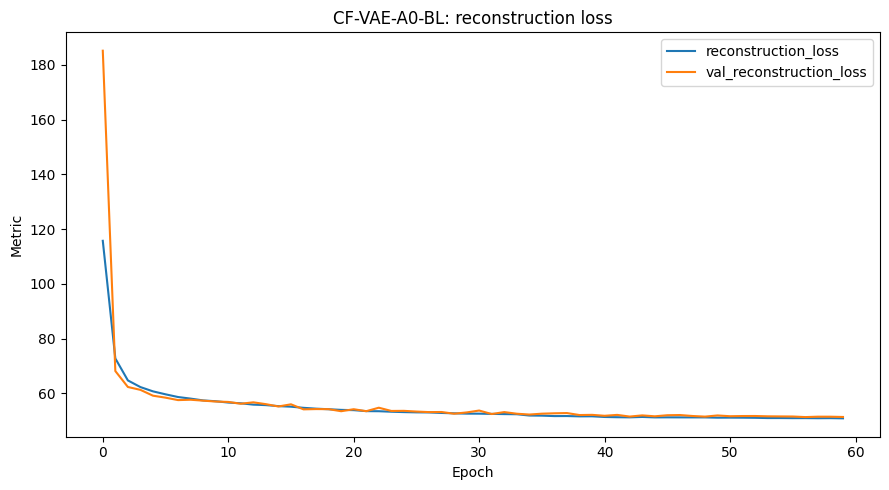

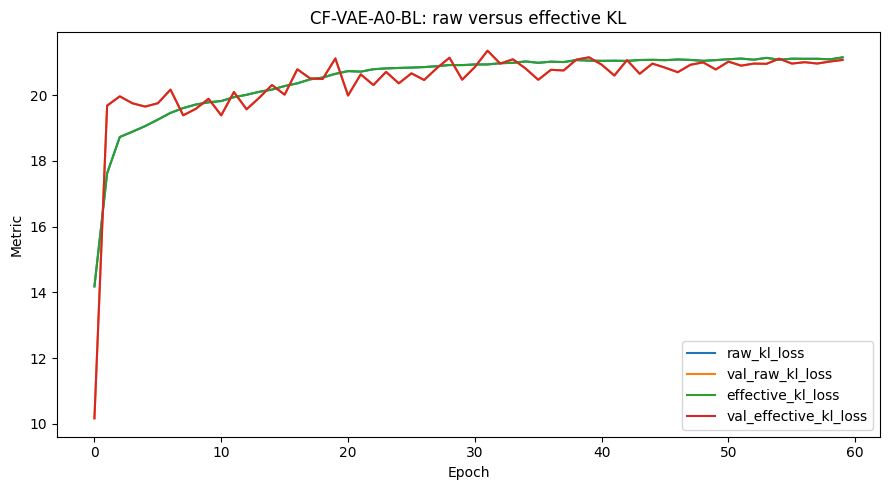

In [25]:
model_id = VAE_A0_ID
history_path = RESULT_DIR / f"{model_id}_history.json"

if history_path.exists():
    with open(history_path, "r", encoding="utf-8") as file:
        history_data = json.load(file)

    plot_history(
        history_data,
        ["reconstruction_loss", "val_reconstruction_loss"],
        f"{model_id}: reconstruction loss",
    )
    plot_history(
        history_data,
        [
            "raw_kl_loss",
            "val_raw_kl_loss",
            "effective_kl_loss",
            "val_effective_kl_loss",
        ],
        f"{model_id}: raw versus effective KL",
    )

#### Evaluation

The reconstruction loss drops quickly and then improves more gradually, while the KL term rises and settles into a stable non-zero region. This gives a usable baseline, but the later latent analysis shows only **30/32 active dimensions**, so there is still room to improve latent utilisation.

### A0 baseline — objective / technique-specific behaviour

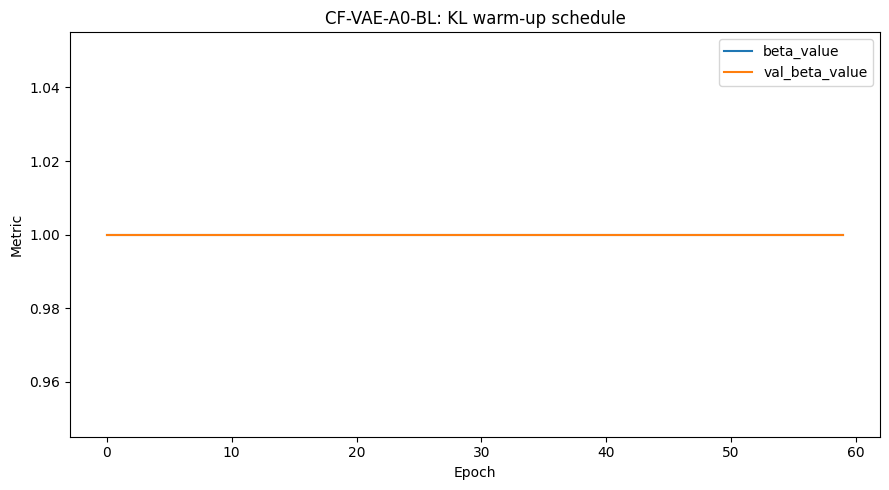

In [25]:
model_id = VAE_A0_ID
experiment = VAE_EXPERIMENTS[model_id]
history_path = RESULT_DIR / f"{model_id}_history.json"

if history_path.exists():
    with open(history_path, "r", encoding="utf-8") as file:
        history_data = json.load(file)

    plot_history(
        history_data,
        ["beta_value", "val_beta_value"],
        f"{model_id}: KL warm-up schedule",
    )

    if experiment["free_bits_per_dim"] > 0:
        plot_history(
            history_data,
            ["free_bits_active_fraction", "val_free_bits_active_fraction"],
            f"{model_id}: fraction of dimensions below free-bits floor",
        )

    if experiment["class_consistency_weight"] > 0.0:
        plot_history(
            history_data,
            [
                "class_consistency_loss",
                "val_class_consistency_loss",
                "reconstruction_class_loss",
                "val_reconstruction_class_loss",
                "prior_class_loss",
                "val_prior_class_loss",
            ],
            f"{model_id}: auxiliary class-consistency losses",
        )

#### Evaluation

A0 applies full KL pressure from the beginning, so the beta schedule is effectively constant at 1.0. This provides the reference for judging whether a gradual warm-up changes optimisation behaviour.

### A1 KL warm-up — reconstruction and KL

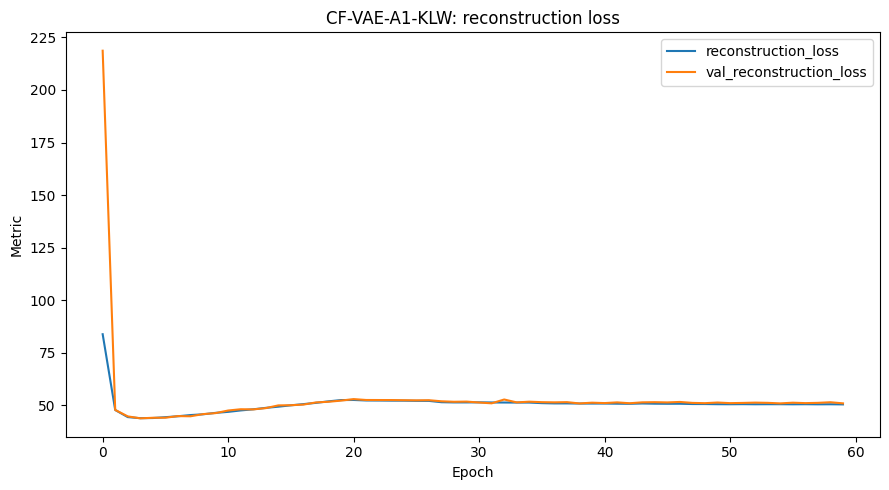

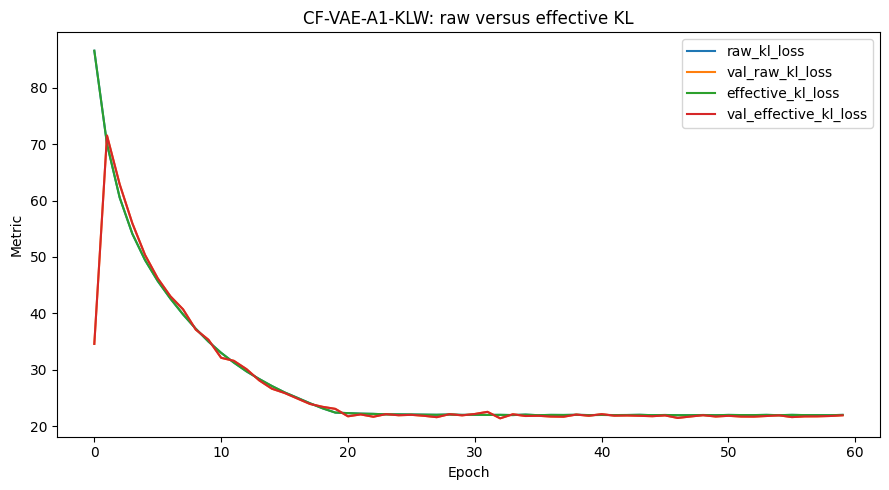

In [25]:
model_id = VAE_A1_ID
history_path = RESULT_DIR / f"{model_id}_history.json"

if history_path.exists():
    with open(history_path, "r", encoding="utf-8") as file:
        history_data = json.load(file)

    plot_history(
        history_data,
        ["reconstruction_loss", "val_reconstruction_loss"],
        f"{model_id}: reconstruction loss",
    )
    plot_history(
        history_data,
        [
            "raw_kl_loss",
            "val_raw_kl_loss",
            "effective_kl_loss",
            "val_effective_kl_loss",
        ],
        f"{model_id}: raw versus effective KL",
    )

#### Evaluation

A1 remains stable while reconstruction and KL adjust to one another. Compared with A0, the final evidence improves: FID changes from **185.82 to 179.37** and active dimensions increase from **30/32 to 32/32**. The improvement is therefore consistent with better latent use rather than a collapse of the KL term.

### A1 KL warm-up — objective / technique-specific behaviour

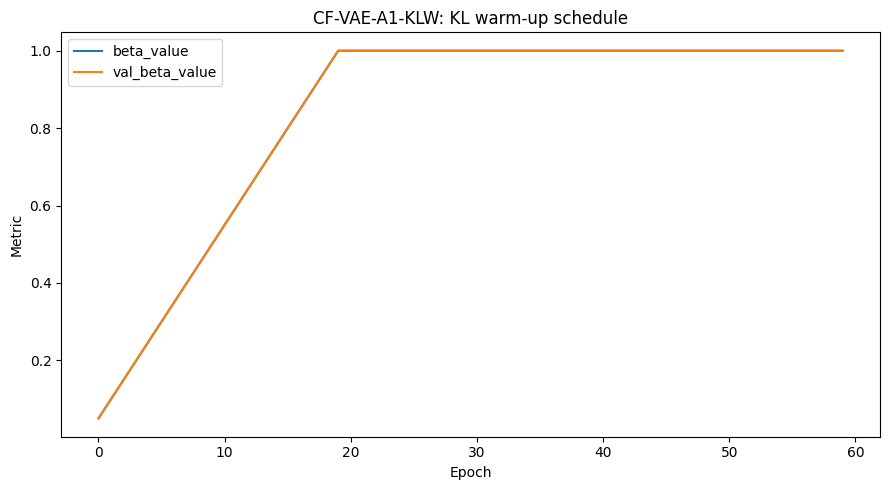

In [25]:
model_id = VAE_A1_ID
experiment = VAE_EXPERIMENTS[model_id]
history_path = RESULT_DIR / f"{model_id}_history.json"

if history_path.exists():
    with open(history_path, "r", encoding="utf-8") as file:
        history_data = json.load(file)

    plot_history(
        history_data,
        ["beta_value", "val_beta_value"],
        f"{model_id}: KL warm-up schedule",
    )

    if experiment["free_bits_per_dim"] > 0:
        plot_history(
            history_data,
            ["free_bits_active_fraction", "val_free_bits_active_fraction"],
            f"{model_id}: fraction of dimensions below free-bits floor",
        )

    if experiment["class_consistency_weight"] > 0.0:
        plot_history(
            history_data,
            [
                "class_consistency_loss",
                "val_class_consistency_loss",
                "reconstruction_class_loss",
                "val_reconstruction_class_loss",
                "prior_class_loss",
                "val_prior_class_loss",
            ],
            f"{model_id}: auxiliary class-consistency losses",
        )

#### Evaluation

The beta plot shows the intended gradual increase to full KL weight over the first 20 epochs. This controlled ramp gives reconstruction learning time before full regularisation is imposed, which supports retaining KL warm-up in the later VAE variants.

### A2 free-bits branch — reconstruction and KL

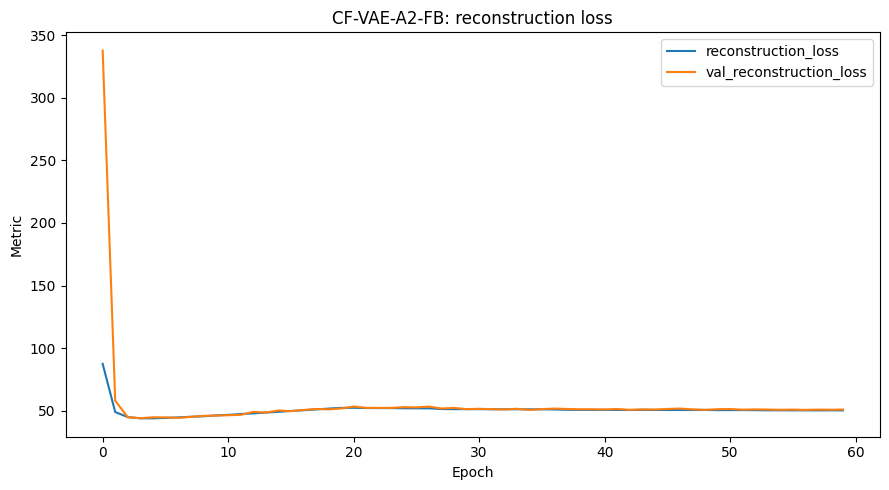

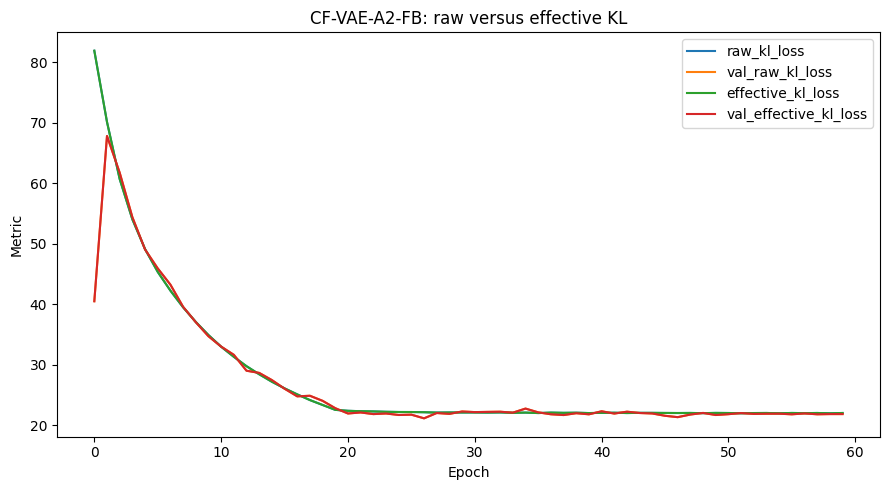

In [25]:
model_id = VAE_A2_ID
history_path = RESULT_DIR / f"{model_id}_history.json"

if history_path.exists():
    with open(history_path, "r", encoding="utf-8") as file:
        history_data = json.load(file)

    plot_history(
        history_data,
        ["reconstruction_loss", "val_reconstruction_loss"],
        f"{model_id}: reconstruction loss",
    )
    plot_history(
        history_data,
        [
            "raw_kl_loss",
            "val_raw_kl_loss",
            "effective_kl_loss",
            "val_effective_kl_loss",
        ],
        f"{model_id}: raw versus effective KL",
    )

#### Evaluation

A2's reconstruction and KL histories are very similar to A1, so adding free bits does not visibly create a new optimisation regime. Its final FID (**180.11**) and class-control metrics also fail to improve on A1.

### A2 free-bits branch — objective / technique-specific behaviour

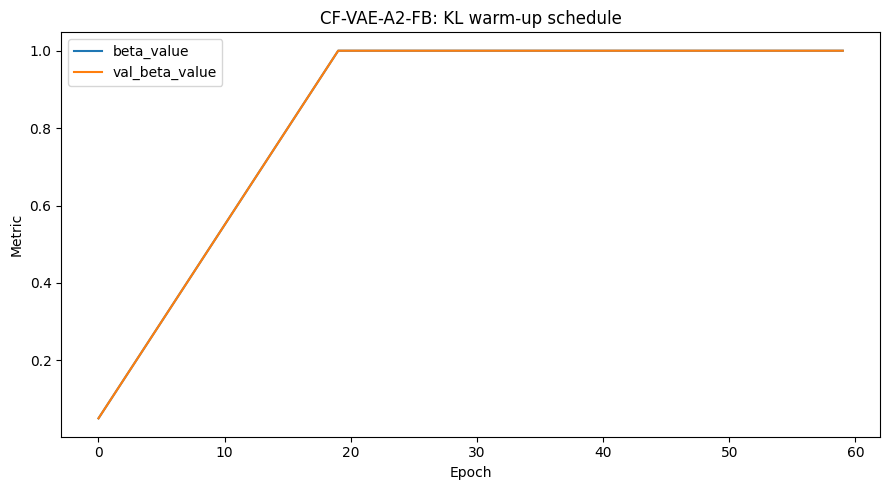

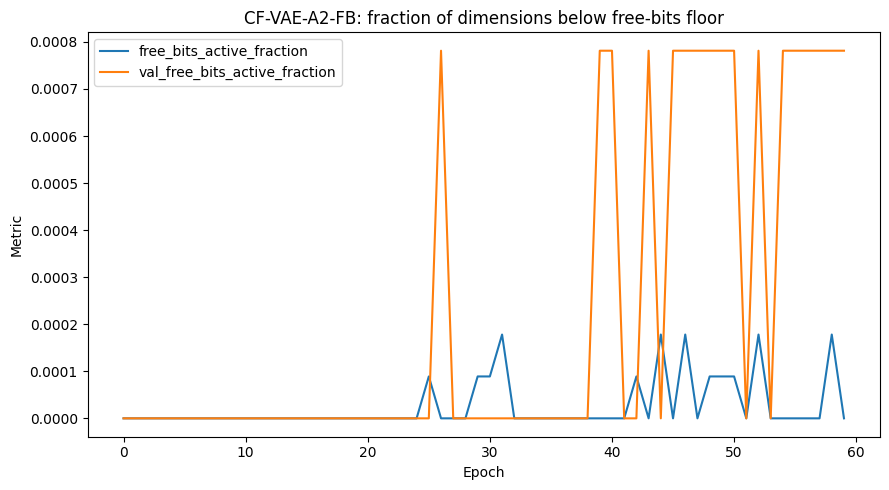

In [25]:
model_id = VAE_A2_ID
experiment = VAE_EXPERIMENTS[model_id]
history_path = RESULT_DIR / f"{model_id}_history.json"

if history_path.exists():
    with open(history_path, "r", encoding="utf-8") as file:
        history_data = json.load(file)

    plot_history(
        history_data,
        ["beta_value", "val_beta_value"],
        f"{model_id}: KL warm-up schedule",
    )

    if experiment["free_bits_per_dim"] > 0:
        plot_history(
            history_data,
            ["free_bits_active_fraction", "val_free_bits_active_fraction"],
            f"{model_id}: fraction of dimensions below free-bits floor",
        )

    if experiment["class_consistency_weight"] > 0.0:
        plot_history(
            history_data,
            [
                "class_consistency_loss",
                "val_class_consistency_loss",
                "reconstruction_class_loss",
                "val_reconstruction_class_loss",
                "prior_class_loss",
                "val_prior_class_loss",
            ],
            f"{model_id}: auxiliary class-consistency losses",
        )

#### Evaluation

The free-bits-active-fraction curve stays essentially at zero, meaning very few or no latent dimensions actually fall below the 0.125-nat floor. The mechanism therefore has little opportunity to influence training. This is the key reason free bits is rejected as a negative result.

### A3 multi-stage conditioning — reconstruction and KL

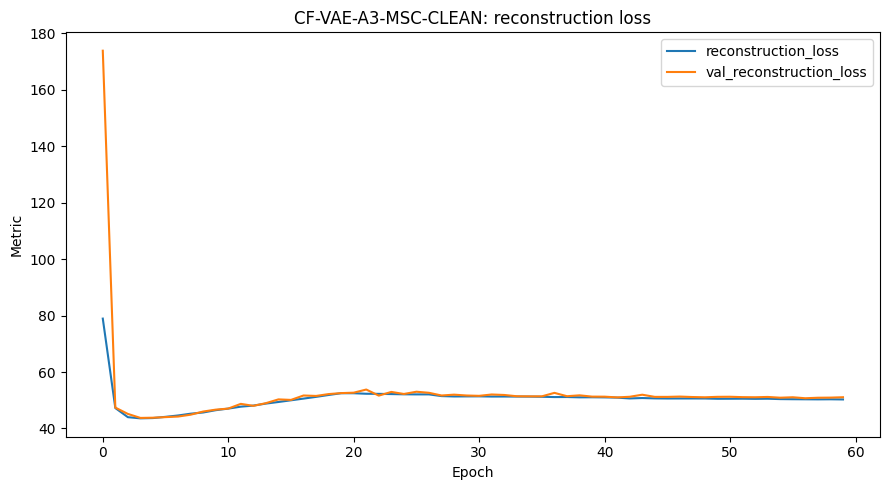

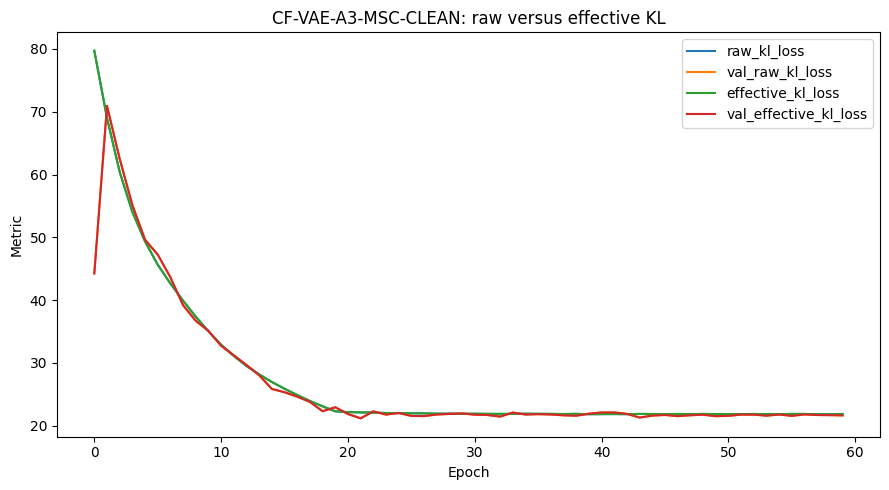

In [25]:
model_id = VAE_A3_ID
history_path = RESULT_DIR / f"{model_id}_history.json"

if history_path.exists():
    with open(history_path, "r", encoding="utf-8") as file:
        history_data = json.load(file)

    plot_history(
        history_data,
        ["reconstruction_loss", "val_reconstruction_loss"],
        f"{model_id}: reconstruction loss",
    )
    plot_history(
        history_data,
        [
            "raw_kl_loss",
            "val_raw_kl_loss",
            "effective_kl_loss",
            "val_effective_kl_loss",
        ],
        f"{model_id}: raw versus effective KL",
    )

#### Evaluation

The reconstruction and KL curves remain stable after labels are injected at multiple decoder resolutions. A3 reaches the **best VAE FID of 177.88**, so the architectural change improves distribution similarity without destabilising the latent objective.

### A3 multi-stage conditioning — objective / technique-specific behaviour

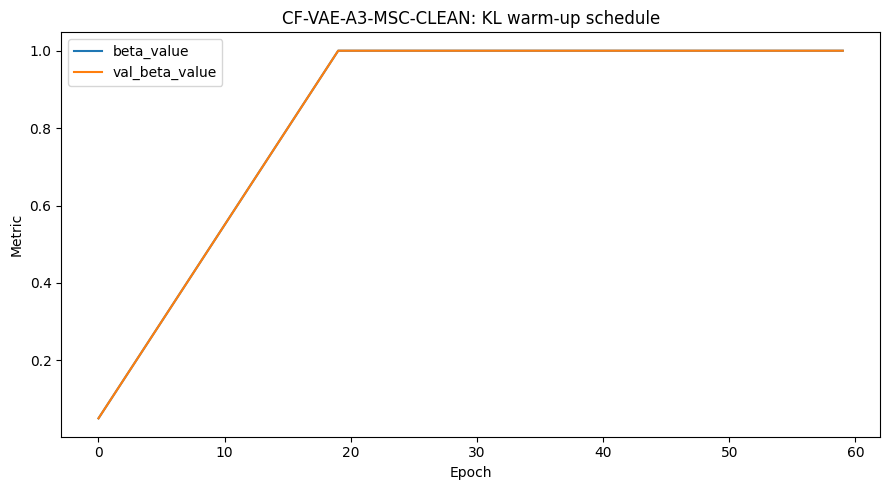

In [25]:
model_id = VAE_A3_ID
experiment = VAE_EXPERIMENTS[model_id]
history_path = RESULT_DIR / f"{model_id}_history.json"

if history_path.exists():
    with open(history_path, "r", encoding="utf-8") as file:
        history_data = json.load(file)

    plot_history(
        history_data,
        ["beta_value", "val_beta_value"],
        f"{model_id}: KL warm-up schedule",
    )

    if experiment["free_bits_per_dim"] > 0:
        plot_history(
            history_data,
            ["free_bits_active_fraction", "val_free_bits_active_fraction"],
            f"{model_id}: fraction of dimensions below free-bits floor",
        )

    if experiment["class_consistency_weight"] > 0.0:
        plot_history(
            history_data,
            [
                "class_consistency_loss",
                "val_class_consistency_loss",
                "reconstruction_class_loss",
                "val_reconstruction_class_loss",
                "prior_class_loss",
                "val_prior_class_loss",
            ],
            f"{model_id}: auxiliary class-consistency losses",
        )

#### Evaluation

A3 uses the same KL warm-up schedule as A1. Since the later conditioning accuracy is still only **21.18%**, the training evidence suggests that stronger label injection alone is not enough to make the requested class dominate the generated semantics.

### A4 strong class consistency — reconstruction and KL

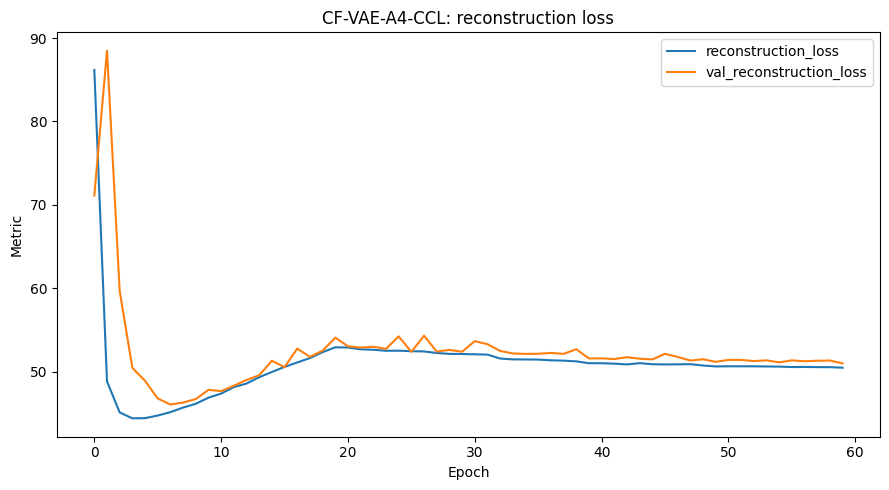

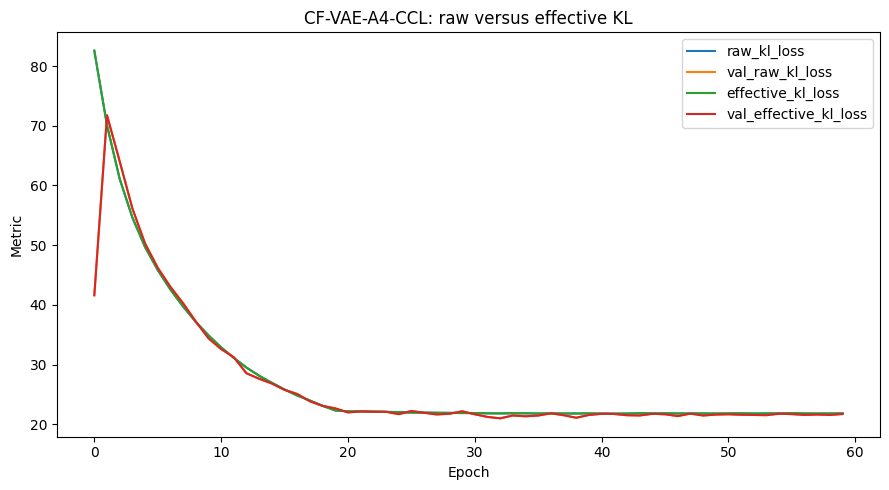

In [25]:
model_id = VAE_A4_ID
history_path = RESULT_DIR / f"{model_id}_history.json"

if history_path.exists():
    with open(history_path, "r", encoding="utf-8") as file:
        history_data = json.load(file)

    plot_history(
        history_data,
        ["reconstruction_loss", "val_reconstruction_loss"],
        f"{model_id}: reconstruction loss",
    )
    plot_history(
        history_data,
        [
            "raw_kl_loss",
            "val_raw_kl_loss",
            "effective_kl_loss",
            "val_effective_kl_loss",
        ],
        f"{model_id}: raw versus effective KL",
    )

#### Evaluation

A4 remains numerically stable, but its reconstruction behaviour reflects the additional semantic objective rather than reconstruction/KL alone. The final trade-off is clear: FID worsens to **200.08**, while conditioning accuracy rises sharply to **58.36%**.

### A4 strong class consistency — objective / technique-specific behaviour

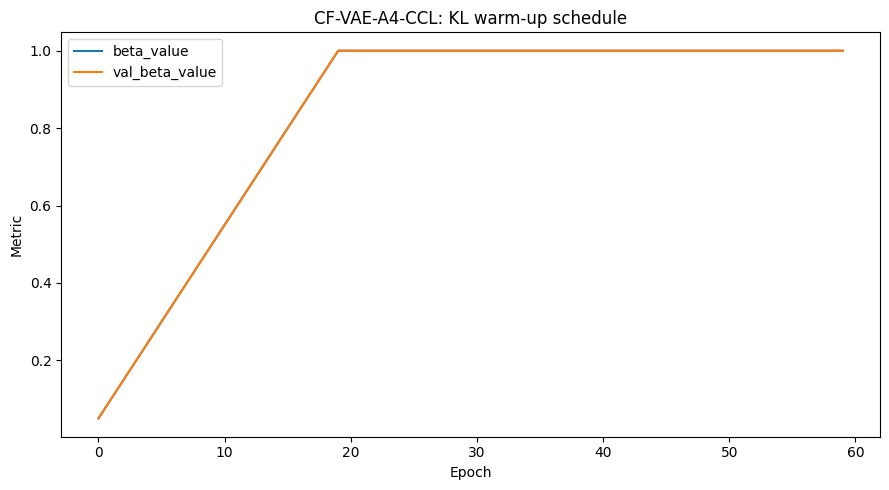

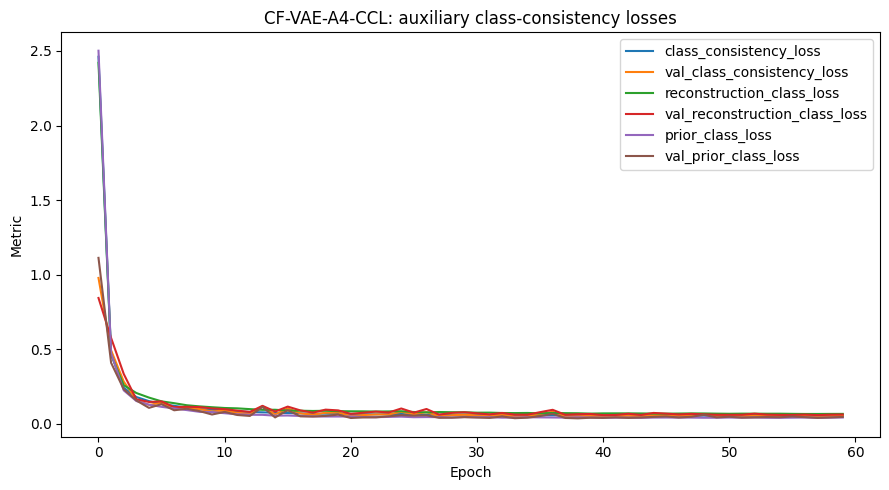

In [25]:
model_id = VAE_A4_ID
experiment = VAE_EXPERIMENTS[model_id]
history_path = RESULT_DIR / f"{model_id}_history.json"

if history_path.exists():
    with open(history_path, "r", encoding="utf-8") as file:
        history_data = json.load(file)

    plot_history(
        history_data,
        ["beta_value", "val_beta_value"],
        f"{model_id}: KL warm-up schedule",
    )

    if experiment["free_bits_per_dim"] > 0:
        plot_history(
            history_data,
            ["free_bits_active_fraction", "val_free_bits_active_fraction"],
            f"{model_id}: fraction of dimensions below free-bits floor",
        )

    if experiment["class_consistency_weight"] > 0.0:
        plot_history(
            history_data,
            [
                "class_consistency_loss",
                "val_class_consistency_loss",
                "reconstruction_class_loss",
                "val_reconstruction_class_loss",
                "prior_class_loss",
                "val_prior_class_loss",
            ],
            f"{model_id}: auxiliary class-consistency losses",
        )

#### Evaluation

The auxiliary class-consistency losses fall strongly during training and then stabilise, showing that the model is learning the extra class-correctness signal. This is the main evidence that the large semantic gain is caused by explicit class supervision rather than by KL warm-up alone.

### A5 lighter class consistency — reconstruction and KL

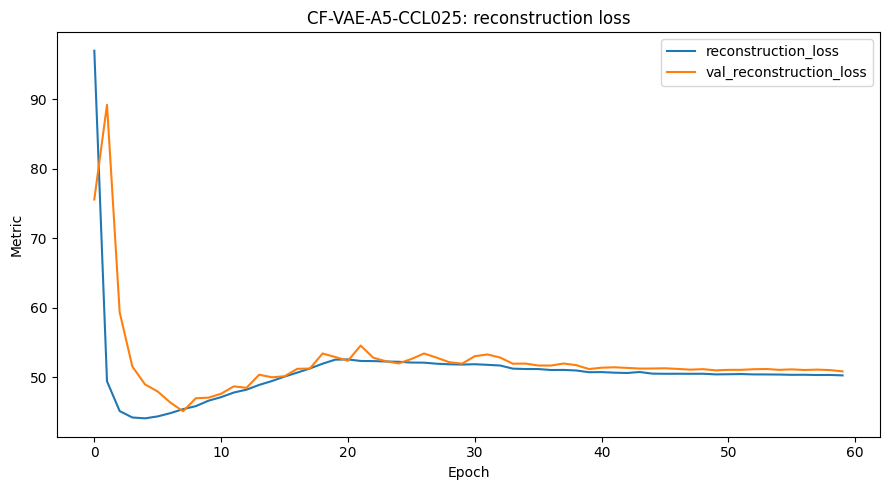

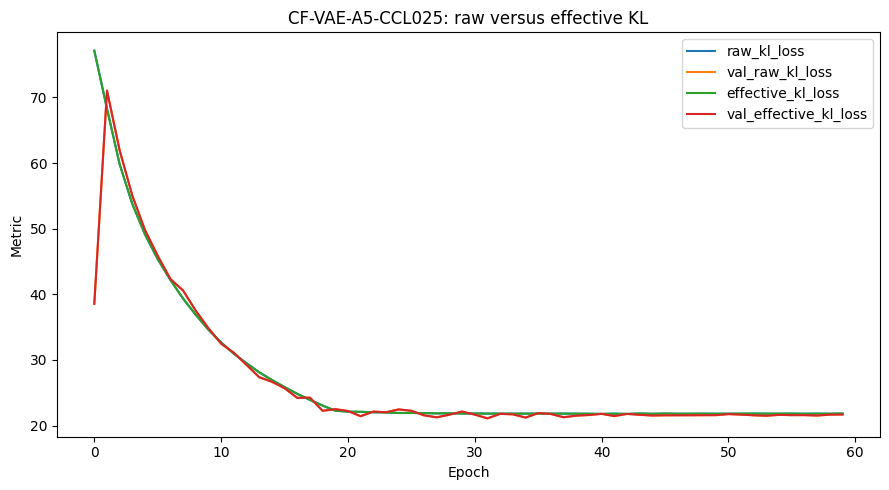

In [25]:
model_id = VAE_A5_ID
history_path = RESULT_DIR / f"{model_id}_history.json"

if history_path.exists():
    with open(history_path, "r", encoding="utf-8") as file:
        history_data = json.load(file)

    plot_history(
        history_data,
        ["reconstruction_loss", "val_reconstruction_loss"],
        f"{model_id}: reconstruction loss",
    )
    plot_history(
        history_data,
        [
            "raw_kl_loss",
            "val_raw_kl_loss",
            "effective_kl_loss",
            "val_effective_kl_loss",
        ],
        f"{model_id}: raw versus effective KL",
    )

#### Evaluation

A5 also trains stably and recovers some FID relative to A4 (**193.84 vs 200.08**), but its class-control metrics fall to **45.38% accuracy** and **41.77% requested-class confidence**. It behaves as an intermediate trade-off rather than a new winner.

### A5 lighter class consistency — objective / technique-specific behaviour

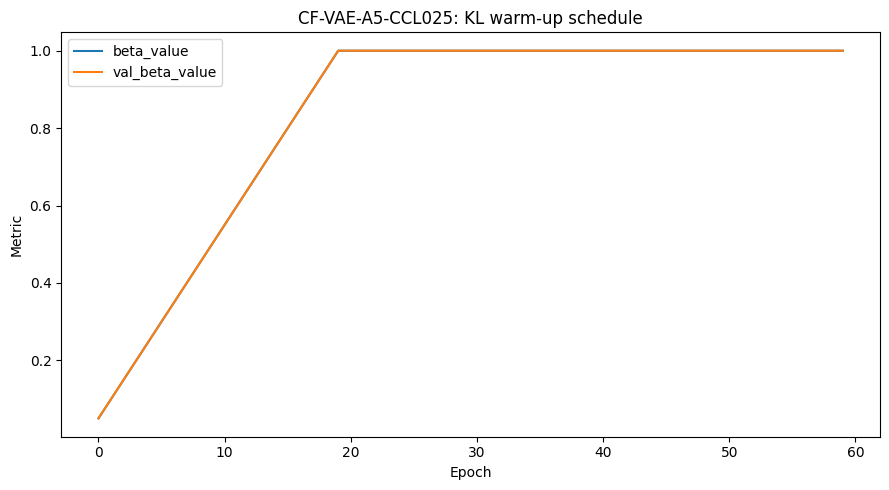

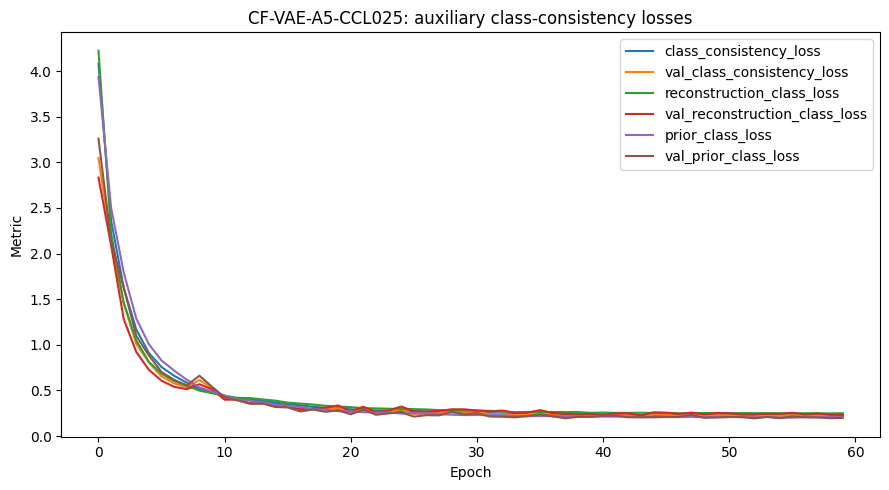

In [25]:
model_id = VAE_A5_ID
experiment = VAE_EXPERIMENTS[model_id]
history_path = RESULT_DIR / f"{model_id}_history.json"

if history_path.exists():
    with open(history_path, "r", encoding="utf-8") as file:
        history_data = json.load(file)

    plot_history(
        history_data,
        ["beta_value", "val_beta_value"],
        f"{model_id}: KL warm-up schedule",
    )

    if experiment["free_bits_per_dim"] > 0:
        plot_history(
            history_data,
            ["free_bits_active_fraction", "val_free_bits_active_fraction"],
            f"{model_id}: fraction of dimensions below free-bits floor",
        )

    if experiment["class_consistency_weight"] > 0.0:
        plot_history(
            history_data,
            [
                "class_consistency_loss",
                "val_class_consistency_loss",
                "reconstruction_class_loss",
                "val_reconstruction_class_loss",
                "prior_class_loss",
                "val_prior_class_loss",
            ],
            f"{model_id}: auxiliary class-consistency losses",
        )

#### Evaluation

The auxiliary class-consistency objective is still active, but with a smaller weight. The weaker semantic pressure explains why A5 gives back some distribution similarity while losing a substantial part of A4's class-control improvement. A5 is therefore not selected.

In [26]:
def generate_vae_balanced(
    model,
    n_per_class,
    seed,
    batch_size=128,
):
    labels = np.repeat(
        np.arange(
            NUM_CLASSES,
            dtype=np.int32,
        ),
        n_per_class,
    )
    latent_dim = model.decoder.input_shape[0][-1]
    rng = np.random.default_rng(seed)
    noise = rng.standard_normal(
        size=(len(labels), latent_dim)
    ).astype(np.float32)

    batches = []

    for start in range(
        0,
        len(labels),
        batch_size,
    ):
        stop = start + batch_size
        batch = model.decoder(
            [
                tf.convert_to_tensor(
                    noise[start:stop]
                ),
                tf.convert_to_tensor(
                    labels[start:stop]
                ),
            ],
            training=False,
        )
        batches.append(batch.numpy())

    return (
        np.concatenate(batches, axis=0),
        labels,
    )

## Fixed conditional VAE generation

Each selected checkpoint is displayed separately so its visual evidence and evaluation stay together.

### `VAE_A0` fixed conditional grid

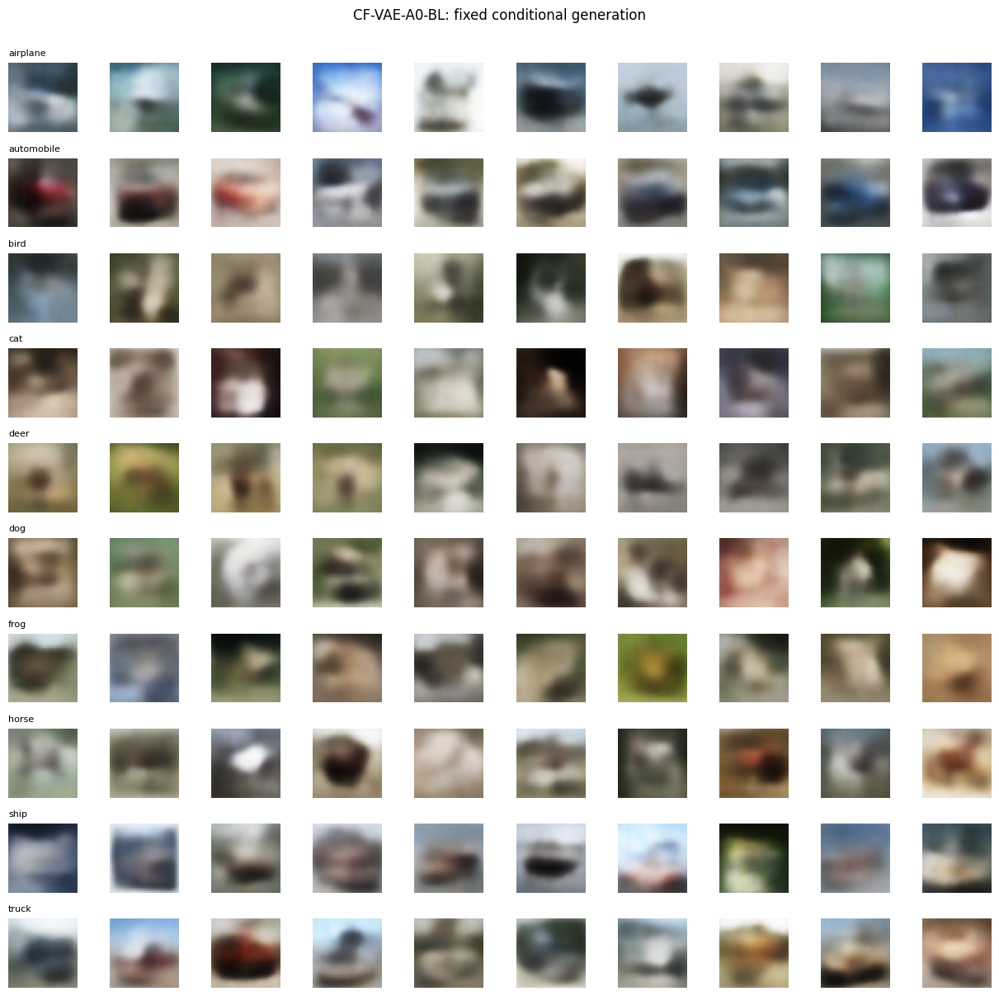

In [26]:
model_id = VAE_A0_ID
model = cf_vae_models[model_id]
path = CHECKPOINT_DIR / model_id / "best.weights.h5"

if path.exists():
    generated = model.decoder(
        [fixed_vae_noise, fixed_labels],
        training=False,
    ).numpy()
    plot_generated_by_class(
        generated,
        fixed_labels.numpy(),
        title=f"{model_id}: fixed conditional generation",
    )

#### Evaluation

The A0 grid is visibly soft and many requested rows share similar coarse colour/shape patterns. This agrees with the low conditioning accuracy (**20.78%**): the model learns CIFAR-10-like structure, but the requested label has only weak control over the final image.

### `VAE_A1` fixed conditional grid

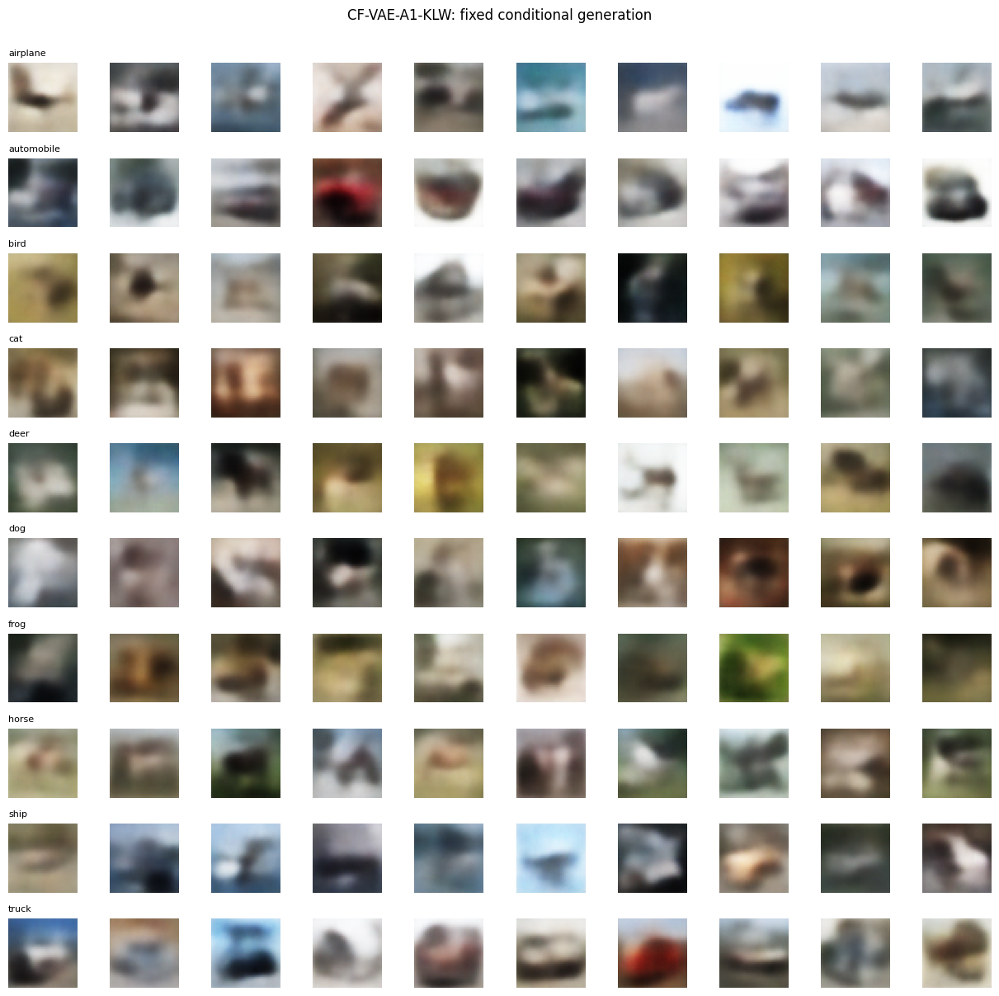

In [26]:
model_id = VAE_A1_ID
model = cf_vae_models[model_id]
path = CHECKPOINT_DIR / model_id / "best.weights.h5"

if path.exists():
    generated = model.decoder(
        [fixed_vae_noise, fixed_labels],
        training=False,
    ).numpy()
    plot_generated_by_class(
        generated,
        fixed_labels.numpy(),
        title=f"{model_id}: fixed conditional generation",
    )

#### Evaluation

A1 looks broadly similar to the baseline, which is expected because KL warm-up targets optimisation and latent use rather than direct semantic supervision. Its FID improves to **179.37**, but conditioning accuracy remains about **20.32%**, so warm-up does not solve the class-control problem.

### `VAE_A2` fixed conditional grid

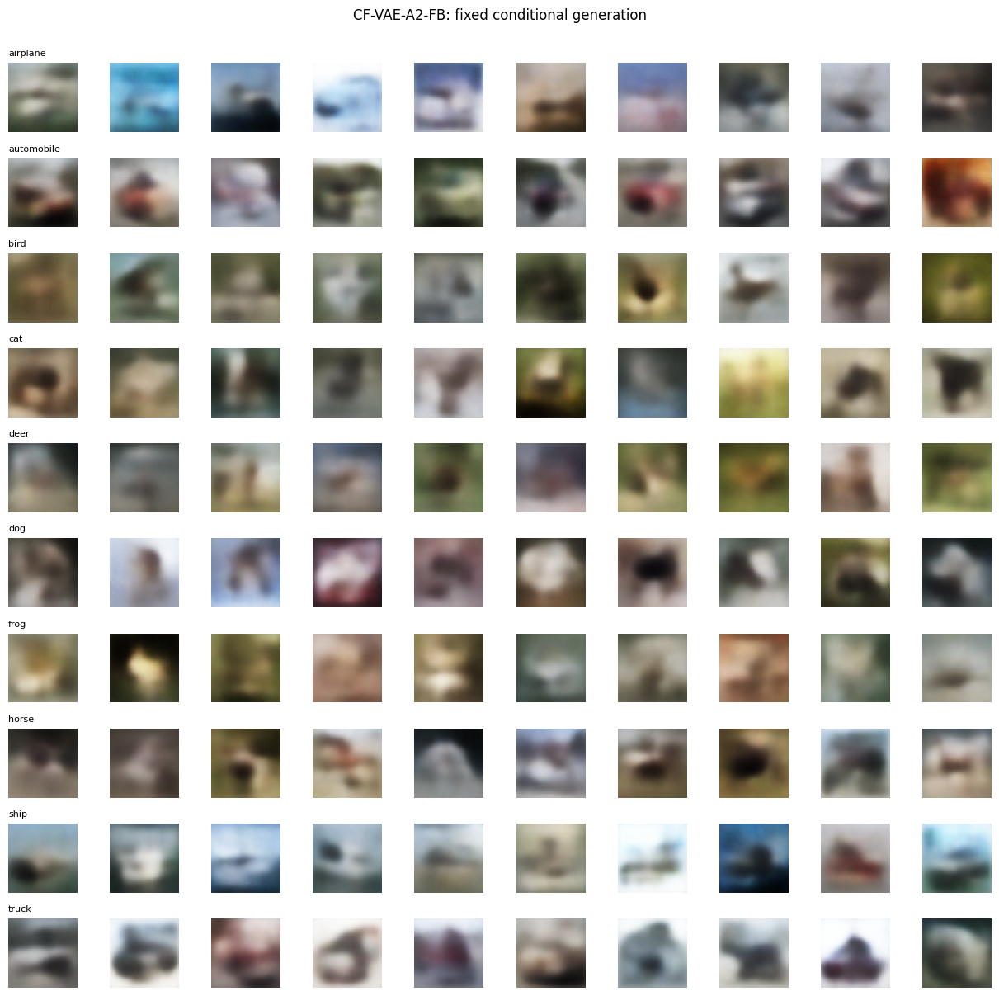

In [26]:
model_id = VAE_A2_ID
model = cf_vae_models[model_id]
path = CHECKPOINT_DIR / model_id / "best.weights.h5"

if path.exists():
    generated = model.decoder(
        [fixed_vae_noise, fixed_labels],
        training=False,
    ).numpy()
    plot_generated_by_class(
        generated,
        fixed_labels.numpy(),
        title=f"{model_id}: fixed conditional generation",
    )

#### Evaluation

The A2 grid does not show a meaningful visual improvement over A1. Together with the nearly inactive free-bits diagnostic and similar metrics, this supports rejecting free bits under the tested setting.

### `VAE_A3` fixed conditional grid

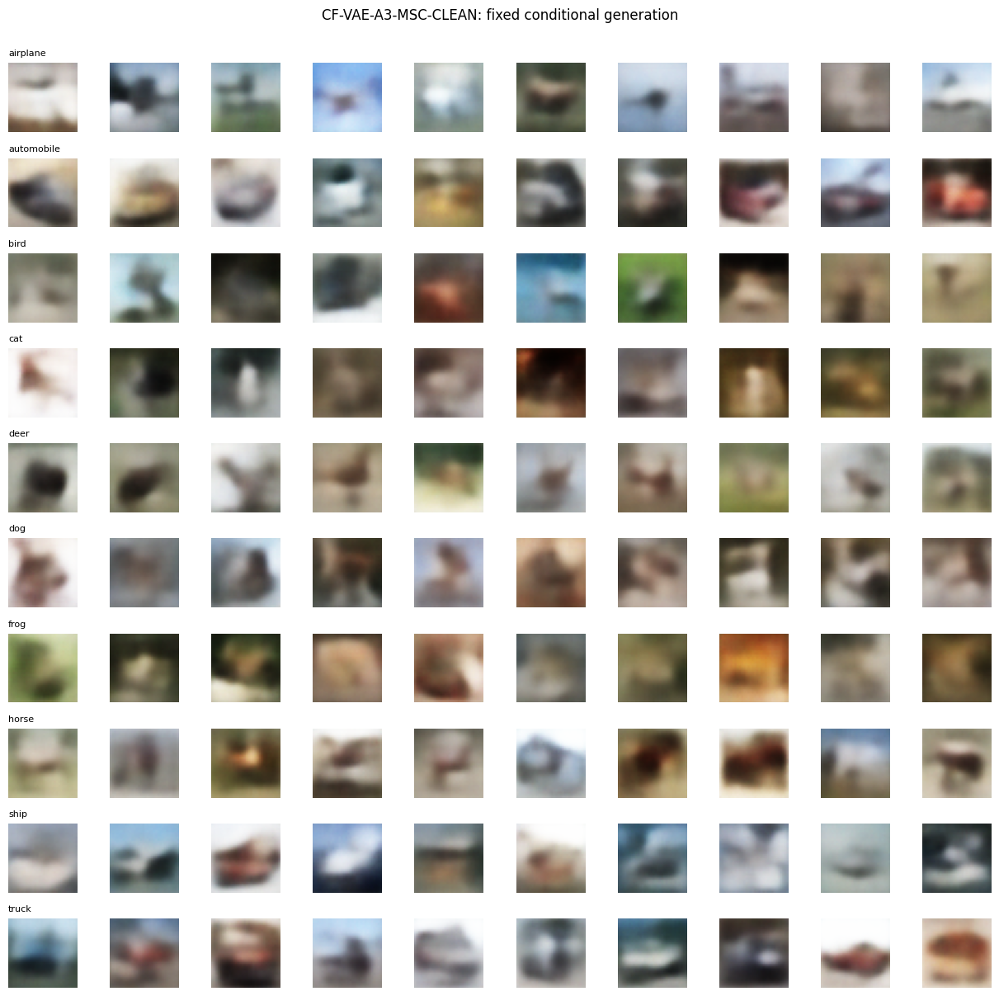

In [26]:
model_id = VAE_A3_ID
model = cf_vae_models[model_id]
path = CHECKPOINT_DIR / model_id / "best.weights.h5"

if path.exists():
    generated = model.decoder(
        [fixed_vae_noise, fixed_labels],
        training=False,
    ).numpy()
    plot_generated_by_class(
        generated,
        fixed_labels.numpy(),
        title=f"{model_id}: fixed conditional generation",
    )

#### Evaluation

A3 provides the strongest VAE distribution similarity (**FID 177.88**) but the requested rows are still not consistently class-distinct. This is consistent with only **21.18%** conditioning accuracy: multi-stage label injection helps the overall distribution without making the class label sufficiently dominant.

### `VAE_A4` fixed conditional grid

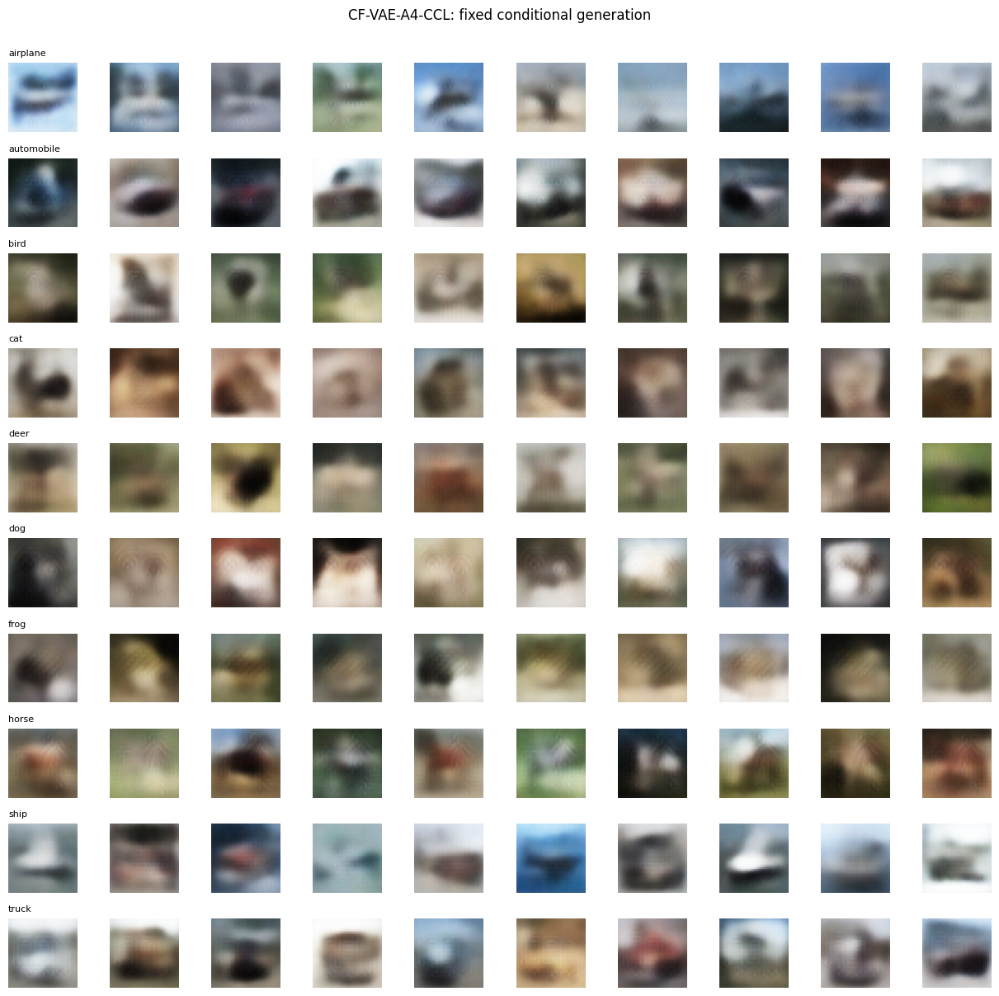

In [26]:
model_id = VAE_A4_ID
model = cf_vae_models[model_id]
path = CHECKPOINT_DIR / model_id / "best.weights.h5"

if path.exists():
    generated = model.decoder(
        [fixed_vae_noise, fixed_labels],
        training=False,
    ).numpy()
    plot_generated_by_class(
        generated,
        fixed_labels.numpy(),
        title=f"{model_id}: fixed conditional generation",
    )

#### Evaluation

A4 shows noticeably stronger class-dependent colour and silhouette cues than A0-A3. This matches its large rise to **58.36% conditioning accuracy** and **52.83% requested-class confidence**. The images are still VAE-like and soft, so A4 is selected for controllability rather than sharpness.

### `VAE_A5` fixed conditional grid

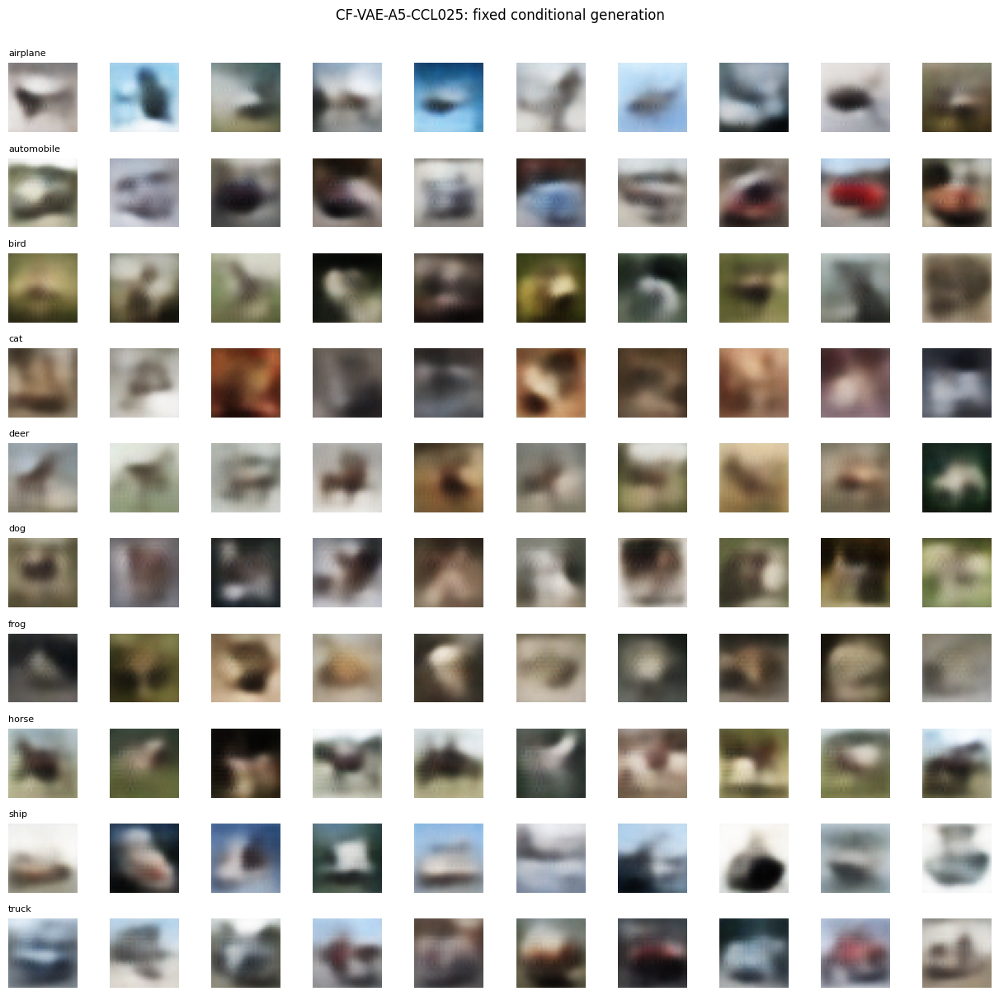

In [26]:
model_id = VAE_A5_ID
model = cf_vae_models[model_id]
path = CHECKPOINT_DIR / model_id / "best.weights.h5"

if path.exists():
    generated = model.decoder(
        [fixed_vae_noise, fixed_labels],
        training=False,
    ).numpy()
    plot_generated_by_class(
        generated,
        fixed_labels.numpy(),
        title=f"{model_id}: fixed conditional generation",
    )

#### Evaluation

A5 retains more class-dependent structure than A3 but is weaker than A4, matching its intermediate **45.38% conditioning accuracy**. The grid therefore supports the quantitative conclusion: lowering the class-loss weight recovers some FID but sacrifices too much requested-class control.

In [27]:
def plot_vae_reconstructions(
    model,
    images,
    labels,
    n=12,
    title="VAE reconstructions",
):
    original = images[:n]
    label_batch = labels[:n]
    reconstructed = model(
        [
            tf.convert_to_tensor(original),
            tf.convert_to_tensor(label_batch),
        ],
        training=False,
    ).numpy()

    fig, axes = plt.subplots(2, n, figsize=(n * 1.3, 3.2))
    for idx in range(n):
        axes[0, idx].imshow(original[idx])
        axes[0, idx].axis("off")
        axes[1, idx].imshow(reconstructed[idx])
        axes[1, idx].axis("off")
    axes[0, 0].set_ylabel("Original")
    axes[1, 0].set_ylabel("Recon.")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

## VAE reconstruction evidence

Each model's original-versus-reconstruction grid is followed immediately by its interpretation.

### `VAE_A0` reconstruction

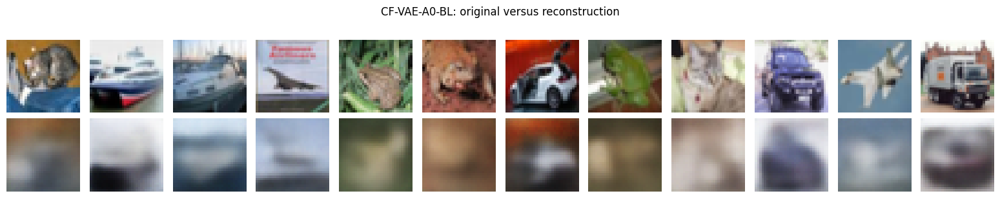

In [27]:
model_id = VAE_A0_ID
model = cf_vae_models[model_id]

if (CHECKPOINT_DIR / model_id / "best.weights.h5").exists():
    plot_vae_reconstructions(
        model,
        x_test_vae,
        y_test,
        title=f"{model_id}: original versus reconstruction",
    )

#### Evaluation

A0 preserves dominant colours and rough object placement, but fine edges and small details are smoothed. This establishes the characteristic reconstruction limitation of the baseline VAE.

### `VAE_A1` reconstruction

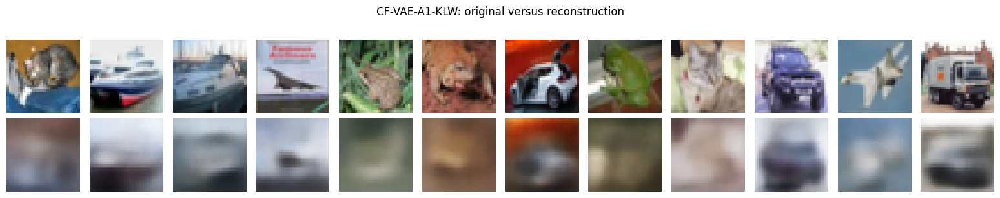

In [27]:
model_id = VAE_A1_ID
model = cf_vae_models[model_id]

if (CHECKPOINT_DIR / model_id / "best.weights.h5").exists():
    plot_vae_reconstructions(
        model,
        x_test_vae,
        y_test,
        title=f"{model_id}: original versus reconstruction",
    )

#### Evaluation

A1 reconstructions remain similarly soft, so KL warm-up does not create a dramatic visual reconstruction change. Its benefit is better latent utilisation and FID rather than visibly sharper reconstructions.

### `VAE_A2` reconstruction

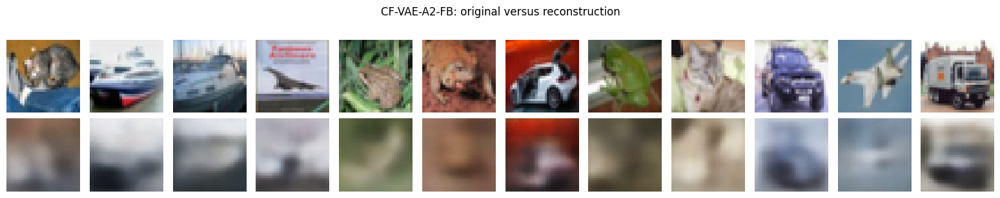

In [27]:
model_id = VAE_A2_ID
model = cf_vae_models[model_id]

if (CHECKPOINT_DIR / model_id / "best.weights.h5").exists():
    plot_vae_reconstructions(
        model,
        x_test_vae,
        y_test,
        title=f"{model_id}: original versus reconstruction",
    )

#### Evaluation

A2 reconstructions are again very similar to A1. Since free bits is almost never active, the absence of a strong reconstruction difference is consistent with the quantitative result that A2 adds little value.

### `VAE_A3` reconstruction

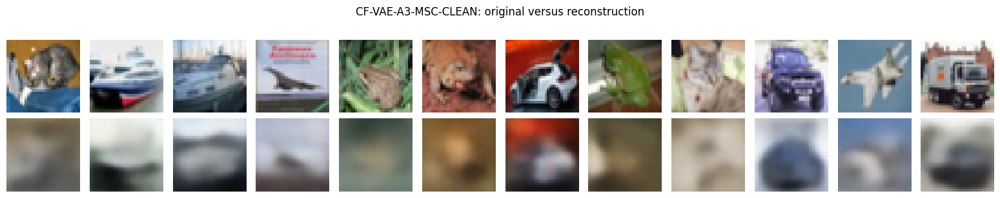

In [27]:
model_id = VAE_A3_ID
model = cf_vae_models[model_id]

if (CHECKPOINT_DIR / model_id / "best.weights.h5").exists():
    plot_vae_reconstructions(
        model,
        x_test_vae,
        y_test,
        title=f"{model_id}: original versus reconstruction",
    )

#### Evaluation

A3 preserves coarse content while remaining blurry at local detail. The important improvement is not reconstruction sharpness but the better FID obtained after multi-stage conditioning.

### `VAE_A4` reconstruction

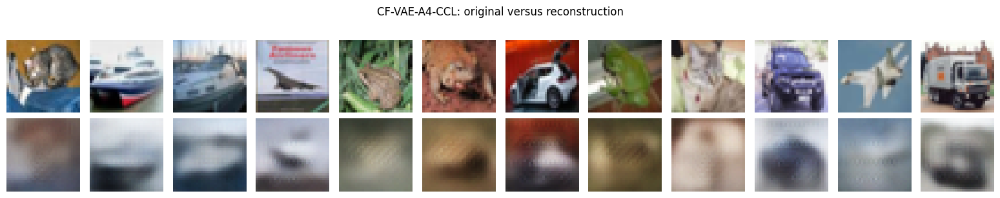

In [27]:
model_id = VAE_A4_ID
model = cf_vae_models[model_id]

if (CHECKPOINT_DIR / model_id / "best.weights.h5").exists():
    plot_vae_reconstructions(
        model,
        x_test_vae,
        y_test,
        title=f"{model_id}: original versus reconstruction",
    )

#### Evaluation

A4 still reconstructs broad structure but smooths fine details. The class-consistency objective mainly changes semantic class behaviour; it does not remove the VAE's reconstruction blur, which helps explain its higher FID than A3.

### `VAE_A5` reconstruction

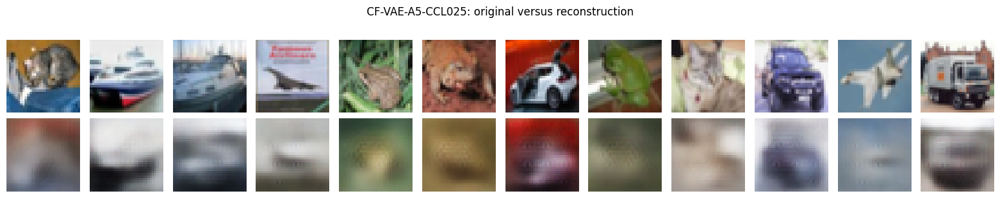

In [27]:
model_id = VAE_A5_ID
model = cf_vae_models[model_id]

if (CHECKPOINT_DIR / model_id / "best.weights.h5").exists():
    plot_vae_reconstructions(
        model,
        x_test_vae,
        y_test,
        title=f"{model_id}: original versus reconstruction",
    )

#### Evaluation

A5 shows the same general VAE reconstruction pattern: recognisable global content with limited fine detail. The lighter class-loss weight changes the realism-versus-control balance, but not the underlying softness of the reconstruction family.

In [28]:
def latent_diagnostics(
    model,
    images,
    labels,
    sample_n=5_000,
    active_std_threshold=0.10,
):
    sample_n = min(
        sample_n,
        len(images),
    )
    z_mean, z_log_var, _ = (
        model.encoder.predict(
            [
                images[:sample_n],
                labels[:sample_n],
            ],
            batch_size=128,
            verbose=0,
        )
    )

    latent_std = z_mean.std(axis=0)
    mean_kl = 0.5 * np.mean(
        np.square(z_mean)
        + np.exp(z_log_var)
        - 1.0
        - z_log_var,
        axis=0,
    )

    free_bits_floor = float(
        model.free_bits_per_dim
    )

    return pd.DataFrame({
        "dimension": np.arange(
            z_mean.shape[1]
        ),
        "z_mean_std": latent_std,
        "mean_raw_kl": mean_kl,
        "active_by_std": (
            latent_std
            > active_std_threshold
        ),
        "below_free_bits_floor": (
            mean_kl < free_bits_floor
            if free_bits_floor > 0
            else np.zeros_like(
                mean_kl,
                dtype=bool,
            )
        ),
    })


latent_summary_rows = []

if RUN_LATENT_ANALYSIS:
    for model_id, model in cf_vae_models.items():
        path = (
            CHECKPOINT_DIR
            / model_id
            / "best.weights.h5"
        )

        if not path.exists():
            continue

        table = latent_diagnostics(
            model,
            x_test_vae,
            y_test,
        )
        table.to_csv(
            RESULT_DIR
            / f"{model_id}_latent_dimensions.csv",
            index=False,
        )

        active_dimensions = int(
            table["active_by_std"].sum()
        )
        below_floor = int(
            table[
                "below_free_bits_floor"
            ].sum()
        )

        latent_summary_rows.append({
            "model_id": model_id,
            "active_dimensions": active_dimensions,
            "total_dimensions": len(table),
            "total_raw_kl": float(
                table["mean_raw_kl"].sum()
            ),
            "median_raw_kl_per_dim": float(
                table["mean_raw_kl"].median()
            ),
            "dimensions_below_free_bits_floor": below_floor,
        })

        print(
            model_id,
            "active dimensions:",
            active_dimensions,
            "/",
            len(table),
        )

        plt.figure(figsize=(10, 4))
        plt.bar(
            table["dimension"],
            table["z_mean_std"],
        )
        plt.axhline(
            0.10,
            linestyle="--",
            label="Active-dimension threshold",
        )
        plt.xlabel("Latent dimension")
        plt.ylabel("Std of z_mean")
        plt.title(
            f"{model_id}: latent activation"
        )
        plt.legend()
        plt.tight_layout()
        plt.savefig(
            REVIEW_FIGURE_DIR / f"{model_id}_latent_activation.png",
            dpi=170, bbox_inches="tight"
        )
        plt.show()

        plt.figure(figsize=(10, 4))
        plt.bar(
            table["dimension"],
            table["mean_raw_kl"],
        )

        if model.free_bits_per_dim > 0:
            plt.axhline(
                model.free_bits_per_dim,
                linestyle="--",
                label=(
                    "Free-bits floor "
                    f"({model.free_bits_per_dim:.3f} nats)"
                ),
            )

        plt.xlabel("Latent dimension")
        plt.ylabel("Mean raw KL (nats)")
        plt.title(
            f"{model_id}: per-dimension raw KL"
        )

        if model.free_bits_per_dim > 0:
            plt.legend()

        plt.tight_layout()
        plt.savefig(
            REVIEW_FIGURE_DIR / f"{model_id}_per_dimension_raw_kl.png",
            dpi=170, bbox_inches="tight"
        )
        plt.show()

    latent_summary_table = pd.DataFrame(
        latent_summary_rows
    )
    latent_summary_table.to_csv(
        RESULT_DIR
        / "CF_VAE_latent_summary.csv",
        index=False,
    )
    display(latent_summary_table)


In [29]:
def plot_latent_interpolation(
    model,
    class_id,
    steps=12,
    seed=42,
    title=None,
):
    latent_dim = model.decoder.input_shape[0][-1]
    rng = np.random.default_rng(seed)
    z_start = rng.standard_normal((1, latent_dim)).astype(np.float32)
    z_end = rng.standard_normal((1, latent_dim)).astype(np.float32)
    alphas = np.linspace(0.0, 1.0, steps, dtype=np.float32)[:, None]
    z = (1.0 - alphas) * z_start + alphas * z_end
    labels = np.full((steps,), class_id, dtype=np.int32)

    images = model.decoder([z, labels], training=False).numpy()

    fig, axes = plt.subplots(1, steps, figsize=(steps * 1.35, 1.7))
    for idx, ax in enumerate(axes):
        ax.imshow(images[idx])
        ax.axis("off")
    plt.suptitle(title or f"Latent interpolation: {CLASS_NAMES[class_id]}")
    plt.tight_layout()
    figure_name = _safe_review_filename(
        title or f"Latent_interpolation_{CLASS_NAMES[class_id]}"
    )
    fig.savefig(
        REVIEW_FIGURE_DIR / f"{figure_name}.png",
        dpi=170, bbox_inches="tight"
    )
    plt.show()

if RUN_LATENT_ANALYSIS:
    for model_id, model in cf_vae_models.items():
        if (CHECKPOINT_DIR / model_id / "best.weights.h5").exists():
            plot_latent_interpolation(
                model,
                class_id=3,
                title=f"{model_id}: cat interpolation",
            )

In [30]:
def balanced_latent_sample(
    images,
    labels,
    n_per_class=200,
    seed=SEED,
):
    rng = np.random.default_rng(seed)
    selected_indices = []

    for class_id in range(NUM_CLASSES):
        class_indices = np.flatnonzero(
            labels == class_id
        )
        selected = rng.choice(
            class_indices,
            size=min(
                n_per_class,
                len(class_indices),
            ),
            replace=False,
        )
        selected_indices.extend(
            selected.tolist()
        )

    selected_indices = np.asarray(
        selected_indices,
        dtype=np.int64,
    )
    rng.shuffle(selected_indices)

    return (
        images[selected_indices],
        labels[selected_indices],
    )


def plot_latent_tsne(
    model,
    images,
    labels,
    model_id,
):
    sample_images, sample_labels = (
        balanced_latent_sample(
            images,
            labels,
            n_per_class=200,
            seed=SEED,
        )
    )

    z_mean, _, _ = model.encoder.predict(
        [
            sample_images,
            sample_labels,
        ],
        batch_size=128,
        verbose=0,
    )

    pca_dimensions = min(
        20,
        z_mean.shape[1],
    )
    reduced = PCA(
        n_components=pca_dimensions,
        random_state=SEED,
    ).fit_transform(z_mean)

    embedding = TSNE(
        n_components=2,
        perplexity=30,
        init="pca",
        learning_rate="auto",
        random_state=SEED,
    ).fit_transform(reduced)

    plt.figure(figsize=(9, 7))

    for class_id, class_name in enumerate(
        CLASS_NAMES
    ):
        mask = sample_labels == class_id
        plt.scatter(
            embedding[mask, 0],
            embedding[mask, 1],
            s=10,
            alpha=0.65,
            label=class_name,
        )

    plt.xlabel("t-SNE dimension 1")
    plt.ylabel("t-SNE dimension 2")
    plt.title(
        f"{model_id}: t-SNE of encoder z_mean"
    )
    plt.legend(
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
    )
    plt.tight_layout()
    plt.savefig(
        REVIEW_FIGURE_DIR / f"{model_id}_latent_tsne.png",
        dpi=170, bbox_inches="tight"
    )
    plt.show()


if RUN_TSNE_ANALYSIS:
    for model_id, model in cf_vae_models.items():
        path = (
            CHECKPOINT_DIR
            / model_id
            / "best.weights.h5"
        )

        if path.exists():
            plot_latent_tsne(
                model,
                x_test_vae,
                y_test,
                model_id,
            )


# 6. Independent FID@5k and Inception Score evaluation

FID and Inception Score now have **separate evaluation flags**:

```python
RUN_FID_EVALUATION_VAE = False
RUN_IS_EVALUATION_VAE = True

RUN_FID_EVALUATION_GAN = False
RUN_IS_EVALUATION_GAN = False
```

These are evaluation controls, not training controls. All model-training flags
should remain `False` when only calculating metrics.

Each enabled metric follows the same balanced generated-image protocol:

- 5,000 generated images per repeat;
- exactly 500 generated images per CIFAR-10 class;
- identical resizing and InceptionV3 preprocessing;
- five independently generated balanced sets;
- mean and sample standard deviation across the five repeats.

When both FID and IS are enabled for the same model family, the notebook reuses
the same generated images within each repeat. This avoids unnecessary image
generation and makes the two metrics describe the same sampled outputs.

## FID

**Heusel et al. (2017), *GANs Trained by a Two Time-Scale Update Rule
Converge to a Local Nash Equilibrium*.** The FID evaluation used in this
notebook was adapted from the paper's **Fréchet Inception Distance** method,
which compares the mean and covariance of Inception-feature distributions for
real and generated images. In our implementation, pooled InceptionV3 features
are computed for the official CIFAR-10 test reference and each balanced
generated set, and the Fréchet distance between their feature statistics is
reported. Lower FID is better. Our five independently generated 5,000-image
repeats are a project evaluation protocol rather than a sample-count setting
claimed from the paper.  
**Source:** [arXiv:1706.08500](https://arxiv.org/abs/1706.08500)

Results are saved as:

```text
<model_id>_fid5k.json
```

## Inception Score

**Salimans et al. (2016), *Improved Techniques for Training GANs*.** The
Inception Score used in this notebook was adapted from the paper's
Inception-based sample-quality measure in Section 4. The method rewards
generated images that receive confident class predictions while also rewarding
diversity across the prediction distribution. In our implementation,
ImageNet-pretrained InceptionV3 probabilities are used to calculate the score
for each balanced 5,000-image generated set, with 10 splits per repeat.
Higher IS is better. The five-repeat protocol is our common project setting.  
**Source:** [arXiv:1606.03498](https://arxiv.org/abs/1606.03498)

Results are saved as:

```text
<model_id>_is5k.json
```

Because CIFAR-10 images are only 32 × 32 and the classifier was trained on
ImageNet classes, IS is supporting evidence rather than the sole selection
criterion. It does not use the requested CIFAR-10 labels and cannot directly
measure conditional accuracy.

FID and IS must still be interpreted together with reconstruction behaviour,
raw KL, latent diagnostics, requested-class accuracy, requested-class
confidence, duplicate rate, and visual evidence.


In [31]:
def build_inception_feature_extractor():
    """InceptionV3 pooled features used by FID."""
    return keras.applications.InceptionV3(
        include_top=False,
        weights="imagenet",
        pooling="avg",
        input_shape=(299, 299, 3),
    )


def build_inception_classifier():
    """ImageNet InceptionV3 probabilities used by Inception Score."""
    return keras.applications.InceptionV3(
        include_top=True,
        weights="imagenet",
        classifier_activation="softmax",
    )


inception_model = None
inception_classifier_model = None


def preprocess_for_inception(images_01):
    """Resize [0, 1] RGB images and apply InceptionV3 preprocessing."""
    images_01 = ensure_01(images_01)
    batch = tf.convert_to_tensor(images_01, dtype=tf.float32)
    batch = tf.image.resize(
        batch,
        (299, 299),
        method="bilinear",
    )
    return keras.applications.inception_v3.preprocess_input(
        batch * 255.0
    )


def extract_inception_features(
    images_01,
    feature_model,
    batch_size=128,
):
    images_01 = ensure_01(images_01)
    features = []

    for start in range(0, len(images_01), batch_size):
        batch = preprocess_for_inception(
            images_01[start:start + batch_size]
        )
        batch_features = feature_model(
            batch,
            training=False,
        )
        features.append(batch_features.numpy())

    return np.concatenate(features, axis=0)


def extract_inception_probabilities(
    images_01,
    classifier_model,
    batch_size=128,
):
    """Return ImageNet class probabilities for generated images."""
    images_01 = ensure_01(images_01)
    probabilities = []

    for start in range(0, len(images_01), batch_size):
        batch = preprocess_for_inception(
            images_01[start:start + batch_size]
        )
        batch_probabilities = classifier_model(
            batch,
            training=False,
        )
        probabilities.append(
            batch_probabilities.numpy()
        )

    probabilities = np.concatenate(
        probabilities,
        axis=0,
    )
    probabilities = np.clip(
        probabilities,
        IS_EPSILON,
        1.0,
    )
    probabilities /= probabilities.sum(
        axis=1,
        keepdims=True,
    )
    return probabilities


def calculate_inception_score_from_probabilities(
    probabilities,
    splits=IS_SPLITS,
):
    """
    Calculate standard Inception Score.

    IS = exp(E_x[KL(p(y|x) || p(y))])

    The returned standard deviation describes variation across the splits
    within this generated set.
    """
    probabilities = np.asarray(
        probabilities,
        dtype=np.float64,
    )

    if probabilities.ndim != 2:
        raise ValueError(
            "probabilities must have shape (N, number_of_classes)."
        )
    if len(probabilities) < splits:
        raise ValueError(
            "The number of images must be at least the number of IS splits."
        )

    split_scores = []
    for split_probabilities in np.array_split(
        probabilities,
        splits,
    ):
        marginal = np.mean(
            split_probabilities,
            axis=0,
            keepdims=True,
        )
        kl = split_probabilities * (
            np.log(split_probabilities)
            - np.log(
                np.clip(
                    marginal,
                    IS_EPSILON,
                    1.0,
                )
            )
        )
        split_scores.append(
            float(
                np.exp(
                    np.mean(
                        np.sum(kl, axis=1)
                    )
                )
            )
        )

    return {
        "is_split_scores": split_scores,
        "is_mean": float(
            np.mean(split_scores)
        ),
        "is_std": float(
            np.std(
                split_scores,
                ddof=1,
            )
            if len(split_scores) > 1
            else 0.0
        ),
    }


def calculate_fid_from_features(
    real_features,
    generated_features,
    epsilon=1e-6,
):
    mu_real = np.mean(real_features, axis=0)
    mu_generated = np.mean(generated_features, axis=0)
    cov_real = np.cov(real_features, rowvar=False)
    cov_generated = np.cov(generated_features, rowvar=False)

    mean_difference = mu_real - mu_generated
    eye = np.eye(cov_real.shape[0]) * epsilon
    covariance_mean, _ = linalg.sqrtm(
        (cov_real + eye) @ (cov_generated + eye),
        disp=False,
    )

    if np.iscomplexobj(covariance_mean):
        covariance_mean = covariance_mean.real

    fid = (
        mean_difference @ mean_difference
        + np.trace(cov_real)
        + np.trace(cov_generated)
        - 2.0 * np.trace(covariance_mean)
    )
    return float(fid)


def get_real_reference_features():
    global inception_model
    cache_path = CACHE_DIR / "cifar10_test_inception_features.npy"

    if cache_path.exists():
        return np.load(cache_path)

    if inception_model is None:
        inception_model = build_inception_feature_extractor()

    real_images = (
        x_test_uint8[:REAL_REFERENCE_N].astype(np.float32) / 255.0
    )
    features = extract_inception_features(
        real_images,
        inception_model,
        batch_size=FID_BATCH_SIZE,
    )
    np.save(cache_path, features)
    return features


In [32]:
def load_saved_metric_result(model_id, metric_name):
    """Load a previously saved FID or IS result when available."""
    metric_name = metric_name.lower()
    if metric_name not in {"fid", "is"}:
        raise ValueError("metric_name must be 'fid' or 'is'.")

    result_path = RESULT_DIR / f"{model_id}_{metric_name}5k.json"
    if not result_path.exists():
        return None

    with open(result_path, "r", encoding="utf-8") as file:
        return json.load(file)


def repeated_distribution_evaluation(
    generate_fn,
    model_id,
    run_fid,
    run_is,
    repeats=FID_REPEATS,
    generated_n=FID_GENERATED_N,
):
    """
    Run FID, IS, or both according to independent flags.

    If both metrics are enabled, each repeat generates one balanced image set
    and reuses it for FID and IS. The metrics are saved to separate JSON files.
    """
    if not run_fid and not run_is:
        return {"fid": None, "is": None}

    if generated_n % NUM_CLASSES != 0:
        raise ValueError(
            "generated_n must be divisible by NUM_CLASSES."
        )

    global inception_model
    global inception_classifier_model

    real_features = None
    if run_fid:
        if inception_model is None:
            inception_model = build_inception_feature_extractor()
        real_features = get_real_reference_features()

    if run_is and inception_classifier_model is None:
        inception_classifier_model = build_inception_classifier()

    n_per_class = generated_n // NUM_CLASSES
    fid_scores = []
    is_repeat_means = []
    is_repeat_split_stds = []
    is_split_scores_by_repeat = []

    for repeat_id in range(repeats):
        images, labels = generate_fn(
            n_per_class,
            SEED + 10_000 + repeat_id,
        )
        assert len(images) == generated_n
        assert np.all(
            np.bincount(labels, minlength=NUM_CLASSES)
            == n_per_class
        )

        status_parts = []

        if run_fid:
            generated_features = extract_inception_features(
                images,
                inception_model,
                batch_size=FID_BATCH_SIZE,
            )
            fid_score = calculate_fid_from_features(
                real_features,
                generated_features,
            )
            fid_scores.append(fid_score)
            status_parts.append(f"FID@5k = {fid_score:.3f}")

        if run_is:
            inception_probabilities = extract_inception_probabilities(
                images,
                inception_classifier_model,
                batch_size=FID_BATCH_SIZE,
            )
            split_result = calculate_inception_score_from_probabilities(
                inception_probabilities,
                splits=IS_SPLITS,
            )
            is_repeat_means.append(split_result["is_mean"])
            is_repeat_split_stds.append(split_result["is_std"])
            is_split_scores_by_repeat.append(
                split_result["is_split_scores"]
            )
            status_parts.append(
                f"IS@5k = {split_result['is_mean']:.3f} "
                f"± {split_result['is_std']:.3f} across splits"
            )

        print(
            f"{model_id} repeat {repeat_id + 1}/{repeats}: "
            + ", ".join(status_parts)
        )

    results = {"fid": None, "is": None}

    if run_fid:
        fid_result = {
            "model_id": model_id,
            "metric": "FID",
            "fid_n": generated_n,
            "repeats": repeats,
            "fid_scores": fid_scores,
            "fid_mean": float(np.mean(fid_scores)),
            "fid_std": float(
                np.std(fid_scores, ddof=1)
                if len(fid_scores) > 1
                else 0.0
            ),
        }
        with open(
            RESULT_DIR / f"{model_id}_fid5k.json",
            "w",
            encoding="utf-8",
        ) as file:
            json.dump(fid_result, file, indent=2)
        results["fid"] = fid_result

    if run_is:
        is_result = {
            "model_id": model_id,
            "metric": "Inception Score",
            "is_n": generated_n,
            "repeats": repeats,
            "is_splits": IS_SPLITS,
            "is_repeat_means": is_repeat_means,
            "is_repeat_split_stds": is_repeat_split_stds,
            "is_split_scores_by_repeat": is_split_scores_by_repeat,
            "is_mean": float(np.mean(is_repeat_means)),
            "is_std": float(
                np.std(is_repeat_means, ddof=1)
                if len(is_repeat_means) > 1
                else 0.0
            ),
        }
        with open(
            RESULT_DIR / f"{model_id}_is5k.json",
            "w",
            encoding="utf-8",
        ) as file:
            json.dump(is_result, file, indent=2)
        results["is"] = is_result

    return results


def repeated_fid_evaluation(
    generate_fn,
    model_id,
    repeats=FID_REPEATS,
    generated_n=FID_GENERATED_N,
):
    """Run FID only and return its result dictionary."""
    return repeated_distribution_evaluation(
        generate_fn=generate_fn,
        model_id=model_id,
        run_fid=True,
        run_is=False,
        repeats=repeats,
        generated_n=generated_n,
    )["fid"]


def repeated_inception_score_evaluation(
    generate_fn,
    model_id,
    repeats=FID_REPEATS,
    generated_n=FID_GENERATED_N,
):
    """Run Inception Score only and return its result dictionary."""
    return repeated_distribution_evaluation(
        generate_fn=generate_fn,
        model_id=model_id,
        run_fid=False,
        run_is=True,
        repeats=repeats,
        generated_n=generated_n,
    )["is"]


In [33]:
def best_post_warmup_epoch(
    model_id,
    warmup_epochs,
):
    history_path = (
        RESULT_DIR / f"{model_id}_history.json"
    )

    if not history_path.exists():
        return np.nan

    with open(
        history_path,
        "r",
        encoding="utf-8",
    ) as file:
        history = json.load(file)

    values = history.get(
        "val_total_loss",
        [],
    )
    if not values:
        return np.nan

    start_index = max(
        0,
        warmup_epochs - 1,
    )
    post_warmup = np.asarray(
        values[start_index:],
        dtype=np.float64,
    )

    if len(post_warmup) == 0:
        return np.nan

    return int(
        start_index
        + np.argmin(post_warmup)
        + 1
    )


vae_evaluation_rows = []

RUN_ANY_VAE_DISTRIBUTION_EVALUATION = (
    RUN_FID_EVALUATION_VAE
    or RUN_IS_EVALUATION_VAE
)

if RUN_ANY_VAE_DISTRIBUTION_EVALUATION:
    if (
        not classifier_weights.exists()
        and not TRAIN_EVAL_CLASSIFIER
    ):
        raise FileNotFoundError(
            "Train or load the evaluation classifier first."
        )

    for model_id, model in cf_vae_models.items():
        path = (
            CHECKPOINT_DIR
            / model_id
            / "best.weights.h5"
        )

        if not path.exists():
            print(
                "Skipping evaluation because weights "
                f"were not found for {model_id}."
            )
            continue

        experiment = VAE_EXPERIMENTS[model_id]

        metric_results = repeated_distribution_evaluation(
            generate_fn=(
                lambda n, seed, m=model:
                generate_vae_balanced(
                    m,
                    n_per_class=n,
                    seed=seed,
                )
            ),
            model_id=model_id,
            run_fid=RUN_FID_EVALUATION_VAE,
            run_is=RUN_IS_EVALUATION_VAE,
        )

        # Use newly calculated results. If one metric is disabled, retain a
        # previously saved result in the combined comparison table when found.
        fid_result = (
            metric_results["fid"]
            or load_saved_metric_result(model_id, "fid")
        )
        is_result = (
            metric_results["is"]
            or load_saved_metric_result(model_id, "is")
        )

        images, labels = generate_vae_balanced(
            model,
            n_per_class=500,
            seed=SEED + 20_000,
        )
        conditioning = evaluate_conditioning(
            images,
            labels,
            classifier,
            show_confusion=False,
        )

        diagnostic_table = latent_diagnostics(
            model,
            x_test_vae,
            y_test,
        )

        vae_evaluation_rows.append({
            "model_id": model_id,
            "target_beta": experiment["target_beta"],
            "warmup_epochs": experiment["warmup_epochs"],
            "free_bits_per_dim": experiment["free_bits_per_dim"],
            "multi_stage_conditioning": experiment[
                "multi_stage_conditioning"
            ],
            "class_consistency_weight": experiment[
                "class_consistency_weight"
            ],
            "class_consistency_prior_fraction": experiment[
                "class_consistency_prior_fraction"
            ],
            "best_post_warmup_epoch": best_post_warmup_epoch(
                model_id,
                experiment["warmup_epochs"],
            ),
            "fid5k_mean": (
                fid_result["fid_mean"]
                if fid_result is not None
                else np.nan
            ),
            "fid5k_std": (
                fid_result["fid_std"]
                if fid_result is not None
                else np.nan
            ),
            "is5k_mean": (
                is_result["is_mean"]
                if is_result is not None
                else np.nan
            ),
            "is5k_std": (
                is_result["is_std"]
                if is_result is not None
                else np.nan
            ),
            "conditioning_accuracy": conditioning[
                "overall_accuracy"
            ],
            "mean_confidence": conditioning["mean_confidence"],
            "requested_class_confidence": conditioning[
                "mean_requested_confidence"
            ],
            "exact_duplicate_rate": exact_duplicate_rate(images),
            "active_dimensions": int(
                diagnostic_table["active_by_std"].sum()
            ),
            "total_raw_kl": float(
                diagnostic_table["mean_raw_kl"].sum()
            ),
            "encoder_parameters": model.encoder.count_params(),
            "decoder_parameters": model.decoder.count_params(),
        })

        per_class_table = pd.DataFrame({
            "class_name": list(
                conditioning["per_class_accuracy"].keys()
            ),
            "accuracy": list(
                conditioning["per_class_accuracy"].values()
            ),
        })
        per_class_table.to_csv(
            RESULT_DIR
            / f"{model_id}_per_class_conditioning.csv",
            index=False,
        )

    vae_evaluation_table = pd.DataFrame(vae_evaluation_rows)
    vae_evaluation_table.to_csv(
        RESULT_DIR / "CF_VAE_RETAINED_PATH_evaluation.csv",
        index=False,
    )
    display(vae_evaluation_table)
else:
    print(
        "VAE FID/IS are not recomputed in this run. "
        "Previously saved VAE metrics are reused by SHOW_SAVED_REVIEW."
    )


VAE FID/IS are not recomputed in this run. Previously saved VAE metrics are reused by SHOW_SAVED_REVIEW.


## VAE decision framework and completed findings

The experiment graph contains one rejected technique branch and one
class-loss weight comparison:

```text
A0 → A1 → A3
      └→ A2, rejected
           A3 ─→ A4, λclass = 1.00
             └→ A5, λclass = 0.25
```

### Quantitative summary

| Model | FID@5k ↓ | IS@5k ↑ | Conditioning accuracy ↑ | Requested-class confidence ↑ | Active dimensions | Total raw KL |
|---|---:|---:|---:|---:|---:|---:|
| A0-BL | 185.82 | 2.1176 | 20.78% | 19.27% | 30/32 | 21.132 |
| A1-KLW | 179.37 | 2.1440 | 20.32% | 18.90% | 32/32 | 21.872 |
| A2-FB | 180.11 | 2.1377 | 20.36% | 18.75% | 32/32 | 22.071 |
| A3-MSC-CLEAN | **177.88** | 2.1240 | 21.18% | 19.33% | 32/32 | 21.954 |
| A4-CCL | 200.08 | **2.1466** | **58.36%** | **52.83%** | 32/32 | 21.882 |
| A5-CCL025 | 193.84 | 2.0923 | 45.38% | 41.77% | 32/32 | 21.849 |

All reported comparisons use the same saved-checkpoint and evaluation
protocol. Differences in total training loss are not used to rank A3, A4 and
A5 because their weighted objectives differ.

### A0 versus A1 — retain KL warm-up

KL warm-up was retained. The architecture did not change, but active latent
dimensions increased from 30/32 to 32/32 and total raw KL increased from
21.132 to 21.872. FID improved from 185.82 to 179.37 and IS increased from
2.1176 to 2.1440. Conditioning accuracy changed only slightly from 20.78% to
20.32%, so warm-up did not solve class control, but it improved distribution
quality and latent usage without adding parameters.

### A1 versus A2 — reject free bits

Free bits was rejected as a side branch. At the final latent diagnostic,
zero dimensions were below the 0.125-nat floor, indicating that the floor was
not meaningfully active for the evaluated checkpoint. FID worsened slightly
from 179.37 to 180.11, IS decreased from 2.1440 to 2.1377, conditioning
accuracy remained effectively unchanged at about 20%, and requested-class
confidence decreased from 18.90% to 18.75%. The extra objective mechanism did
not provide a defensible improvement.

### A1 versus A3 — retain clean multi-stage conditioning

Multi-stage conditioning was retained. Conditioning accuracy increased from
20.32% to 21.18%, requested-class confidence increased from 18.90% to 19.33%,
and FID improved from 179.37 to the best VAE value of 177.88. IS decreased
slightly from 2.1440 to 2.1240, so the change did not improve every metric.
Nevertheless, A3 provided the strongest VAE distribution similarity, used all
32 latent dimensions and became the clean parent for the class-consistency
experiments.

### A3 versus A4 — strong class consistency

The class-consistency objective produced a major class-control improvement.
Conditioning accuracy increased from 21.18% to 58.36%, while requested-class
confidence increased from 19.33% to 52.83%. IS also increased from 2.1240 to
2.1466, the highest VAE mean.

The trade-off was a worse FID, increasing from 177.88 to 200.08. This shows
that a model can become substantially more class-controllable while moving
further from the overall real-image feature distribution. A4 therefore
demonstrates a clear semantic-control versus distribution-similarity trade-off.

### A3 versus A5 — lighter class consistency

The lighter class objective also improved class control relative to A3.
Conditioning accuracy increased from 21.18% to 45.38%, and requested-class
confidence increased from 19.33% to 41.77%. However, FID worsened from 177.88
to 193.84 and IS decreased from 2.1240 to 2.0923. A5 achieved a middle
conditioning level, but it did not produce a superior overall metric balance.

### A4 versus A5 — select A4

Reducing the class-loss weight from 1.00 to 0.25 improved FID from 200.08 to
193.84, a recovery of 6.24 points. However, conditioning accuracy fell from
58.36% to 45.38%, requested-class confidence fell from 52.83% to 41.77%, and
IS fell from 2.1466 to 2.0923.

The FID recovery was not large enough to compensate for the substantial loss
of class control and the lowest VAE IS. Based on the completed automated and latent evidence, A4 is selected
as Chun Fei's best conditional VAE.

### VAE finalist decision

- **Best VAE for distribution similarity:** `CF-VAE-A3-MSC-CLEAN`
- **Best conditional VAE and selected finalist:** `CF-VAE-A4-CCL`

A4 is selected because the goal is requested-class generation.
The selection does not claim that A4 wins every metric; it explicitly accepts
a FID penalty in return for a large and measurable improvement in class
control.


In [34]:
if SELECTED_VAE_MODEL_ID not in cf_vae_models:
    raise ValueError(
        "SELECTED_VAE_MODEL_ID must be one of: "
        f"{list(cf_vae_models)}"
    )

FINAL_CF_VAE_ID = SELECTED_VAE_MODEL_ID
print("Current final CF-VAE:", FINAL_CF_VAE_ID)


Current final CF-VAE: CF-VAE-A4-CCL


# 6A. Diagnostic investigation of VAE class conditioning

The original three diagnostics were used to determine why clean A3 had weak
semantic control. After A5 is trained, run the same tests on A5 and compare
its behaviour with A3 and A4.

Recommended diagnostic targets:

```python
DIAGNOSTIC_VAE_MODEL_ID = VAE_A3_ID  # no class loss
DIAGNOSTIC_VAE_MODEL_ID = VAE_A4_ID  # weight 1.00
DIAGNOSTIC_VAE_MODEL_ID = VAE_A5_ID  # weight 0.25
```

The tests are:

1. **Fixed-\(z\) label sweep:** hold the latent vector fixed and change only
   the requested label.
2. **Reconstruction versus random-prior conditioning:** compare posterior
   reconstructions with samples from \(z \sim \mathcal{N}(0,I)\).
3. **Posterior label swap:** encode a real image once, then decode the same
   posterior latent under all ten labels.

A useful A5 result would show more semantic response to labels than A3 while
avoiding the overly classifier-driven appearance that may contribute to A4's
FID penalty.

These tests never update the VAE or either classifier.

In [35]:

def diagnostic_balanced_indices(
    labels,
    n_per_class,
    seed=SEED,
):
    """Return reproducible, class-balanced indices."""
    labels = np.asarray(labels).reshape(-1)
    rng = np.random.default_rng(seed)
    selected_indices = []

    for class_id in range(NUM_CLASSES):
        class_indices = np.flatnonzero(
            labels == class_id
        )

        if len(class_indices) < n_per_class:
            raise ValueError(
                f"Class {class_id} has only {len(class_indices)} "
                f"examples, fewer than requested {n_per_class}."
            )

        selected = rng.choice(
            class_indices,
            size=n_per_class,
            replace=False,
        )
        selected_indices.extend(
            selected.tolist()
        )

    selected_indices = np.asarray(
        selected_indices,
        dtype=np.int64,
    )
    rng.shuffle(selected_indices)
    return selected_indices


def diagnostic_predict(
    images,
    requested_labels,
    classifier_model=classifier,
    batch_size=BATCH_SIZE,
):
    """Return classifier probabilities, predictions and requested confidence."""
    images = ensure_01(images)
    requested_labels = np.asarray(
        requested_labels,
        dtype=np.int32,
    ).reshape(-1)

    probabilities = classifier_model.predict(
        images,
        batch_size=batch_size,
        verbose=0,
    )
    predictions = probabilities.argmax(axis=1)
    requested_confidence = probabilities[
        np.arange(len(requested_labels)),
        requested_labels,
    ]

    return {
        "probabilities": probabilities,
        "predictions": predictions,
        "requested_confidence": requested_confidence,
        "accuracy": float(
            np.mean(
                predictions == requested_labels
            )
        ),
        "mean_requested_confidence": float(
            requested_confidence.mean()
        ),
    }


def require_vae_diagnostic_assets(model_id):
    """Fail early when the model or shared classifier is unavailable."""
    if model_id not in cf_vae_models:
        raise KeyError(
            f"{model_id} is not present in cf_vae_models."
        )

    model_path = (
        CHECKPOINT_DIR
        / model_id
        / "best.weights.h5"
    )
    if not model_path.exists():
        raise FileNotFoundError(
            f"VAE checkpoint not found: {model_path}"
        )

    if not classifier_weights.exists():
        raise FileNotFoundError(
            "Shared evaluation-classifier weights were not found at "
            f"{classifier_weights}."
        )

    return cf_vae_models[model_id]


In [36]:

def run_fixed_z_label_sweep(
    model,
    model_id,
    n_latents=5,
    seed=SEED + 31_000,
):
    """
    Test 1: hold z constant while requesting all ten classes.

    A strong visual or semantic change across columns indicates that the
    decoder uses the label. Nearly identical outputs suggest label neglect.
    """
    latent_dim = model.decoder.input_shape[0][-1]
    rng = np.random.default_rng(seed)

    base_z = rng.standard_normal(
        (n_latents, latent_dim)
    ).astype(np.float32)

    repeated_z = np.repeat(
        base_z,
        NUM_CLASSES,
        axis=0,
    )
    requested_labels = np.tile(
        np.arange(
            NUM_CLASSES,
            dtype=np.int32,
        ),
        n_latents,
    )

    generated = model.decoder.predict(
        [
            repeated_z,
            requested_labels,
        ],
        batch_size=BATCH_SIZE,
        verbose=0,
    )
    generated = ensure_01(generated)

    prediction_result = diagnostic_predict(
        generated,
        requested_labels,
    )
    predictions = prediction_result[
        "predictions"
    ]
    requested_confidence = prediction_result[
        "requested_confidence"
    ]

    rows = []
    sensitivity_rows = []

    for latent_id in range(n_latents):
        start = latent_id * NUM_CLASSES
        stop = start + NUM_CLASSES
        latent_images = generated[start:stop]

        pairwise_l1 = []
        for left in range(NUM_CLASSES):
            for right in range(left + 1, NUM_CLASSES):
                pairwise_l1.append(
                    float(
                        np.mean(
                            np.abs(
                                latent_images[left]
                                - latent_images[right]
                            )
                        )
                    )
                )

        sensitivity_rows.append({
            "latent_id": latent_id,
            "mean_pixel_std_across_labels": float(
                np.mean(
                    np.std(
                        latent_images,
                        axis=0,
                    )
                )
            ),
            "mean_pairwise_l1_across_labels": float(
                np.mean(pairwise_l1)
            ),
        })

        for class_id in range(NUM_CLASSES):
            flat_index = start + class_id
            rows.append({
                "latent_id": latent_id,
                "requested_class_id": class_id,
                "requested_class": CLASS_NAMES[
                    class_id
                ],
                "predicted_class_id": int(
                    predictions[flat_index]
                ),
                "predicted_class": CLASS_NAMES[
                    int(predictions[flat_index])
                ],
                "requested_class_confidence": float(
                    requested_confidence[flat_index]
                ),
                "correct": bool(
                    predictions[flat_index]
                    == class_id
                ),
            })

    result_table = pd.DataFrame(rows)
    sensitivity_table = pd.DataFrame(
        sensitivity_rows
    )

    figure, axes = plt.subplots(
        n_latents,
        NUM_CLASSES,
        figsize=(15, 1.8 * n_latents),
        squeeze=False,
    )

    for latent_id in range(n_latents):
        for class_id in range(NUM_CLASSES):
            flat_index = (
                latent_id * NUM_CLASSES
                + class_id
            )
            axis = axes[latent_id, class_id]
            axis.imshow(generated[flat_index])
            axis.axis("off")
            axis.set_xlabel(
                "pred: "
                + CLASS_NAMES[
                    int(predictions[flat_index])
                ],
                fontsize=7,
            )

            if latent_id == 0:
                axis.set_title(
                    CLASS_NAMES[class_id],
                    fontsize=8,
                )

            if class_id == 0:
                axis.text(
                    -0.12,
                    0.5,
                    f"fixed z {latent_id + 1}",
                    transform=axis.transAxes,
                    rotation=90,
                    va="center",
                    ha="right",
                    fontsize=8,
                )

    figure.suptitle(
        f"{model_id}: fixed-z label sweep",
        y=1.005,
    )
    plt.tight_layout()

    figure_path = (
        RESULT_DIR
        / f"{model_id}_diagnostic_fixed_z_label_sweep.png"
    )
    figure.savefig(
        figure_path,
        dpi=170,
        bbox_inches="tight",
    )
    plt.show()

    result_table.to_csv(
        RESULT_DIR
        / f"{model_id}_diagnostic_fixed_z_predictions.csv",
        index=False,
    )
    sensitivity_table.to_csv(
        RESULT_DIR
        / f"{model_id}_diagnostic_fixed_z_sensitivity.csv",
        index=False,
    )

    summary = pd.DataFrame([{
        "model_id": model_id,
        "test": "fixed_z_label_sweep",
        "n_latent_vectors": n_latents,
        "n_generated_images": len(generated),
        "conditioning_accuracy": prediction_result[
            "accuracy"
        ],
        "mean_requested_class_confidence": (
            prediction_result[
                "mean_requested_confidence"
            ]
        ),
        "mean_pixel_std_across_labels": float(
            sensitivity_table[
                "mean_pixel_std_across_labels"
            ].mean()
        ),
        "mean_pairwise_l1_across_labels": float(
            sensitivity_table[
                "mean_pairwise_l1_across_labels"
            ].mean()
        ),
    }])

    return {
        "images": generated,
        "predictions": result_table,
        "sensitivity": sensitivity_table,
        "summary": summary,
        "figure_path": figure_path,
    }


In [37]:

def run_reconstruction_vs_prior_test(
    model,
    model_id,
    images,
    labels,
    n_per_class=500,
    seed=SEED + 32_000,
):
    """
    Test 2: compare real images, posterior-mean reconstructions and random
    prior generations under the same balanced class labels.
    """
    selected_indices = diagnostic_balanced_indices(
        labels,
        n_per_class=n_per_class,
        seed=seed,
    )
    selected_images = ensure_01(
        images[selected_indices]
    )
    selected_labels = np.asarray(
        labels[selected_indices],
        dtype=np.int32,
    )

    z_mean, _, _ = model.encoder.predict(
        [
            selected_images,
            selected_labels,
        ],
        batch_size=BATCH_SIZE,
        verbose=0,
    )

    reconstructions = model.decoder.predict(
        [
            z_mean,
            selected_labels,
        ],
        batch_size=BATCH_SIZE,
        verbose=0,
    )
    reconstructions = ensure_01(
        reconstructions
    )

    rng = np.random.default_rng(seed + 1)
    prior_z = rng.standard_normal(
        z_mean.shape
    ).astype(np.float32)

    prior_generations = model.decoder.predict(
        [
            prior_z,
            selected_labels,
        ],
        batch_size=BATCH_SIZE,
        verbose=0,
    )
    prior_generations = ensure_01(
        prior_generations
    )

    real_result = diagnostic_predict(
        selected_images,
        selected_labels,
    )
    reconstruction_result = diagnostic_predict(
        reconstructions,
        selected_labels,
    )
    prior_result = diagnostic_predict(
        prior_generations,
        selected_labels,
    )

    reconstruction_mse = float(
        np.mean(
            np.square(
                selected_images
                - reconstructions
            )
        )
    )

    summary = pd.DataFrame([
        {
            "model_id": model_id,
            "source": "real_test_images",
            "n_images": len(selected_images),
            "conditioning_accuracy": real_result[
                "accuracy"
            ],
            "mean_requested_class_confidence": (
                real_result[
                    "mean_requested_confidence"
                ]
            ),
            "reconstruction_mse": np.nan,
        },
        {
            "model_id": model_id,
            "source": "posterior_mean_reconstructions",
            "n_images": len(reconstructions),
            "conditioning_accuracy": (
                reconstruction_result[
                    "accuracy"
                ]
            ),
            "mean_requested_class_confidence": (
                reconstruction_result[
                    "mean_requested_confidence"
                ]
            ),
            "reconstruction_mse": reconstruction_mse,
        },
        {
            "model_id": model_id,
            "source": "random_standard_normal_prior",
            "n_images": len(prior_generations),
            "conditioning_accuracy": prior_result[
                "accuracy"
            ],
            "mean_requested_class_confidence": (
                prior_result[
                    "mean_requested_confidence"
                ]
            ),
            "reconstruction_mse": np.nan,
        },
    ])

    per_class_rows = []
    source_results = {
        "real_test_images": real_result,
        "posterior_mean_reconstructions": (
            reconstruction_result
        ),
        "random_standard_normal_prior": (
            prior_result
        ),
    }

    for source_name, source_result in (
        source_results.items()
    ):
        predictions = source_result[
            "predictions"
        ]

        for class_id, class_name in enumerate(
            CLASS_NAMES
        ):
            mask = selected_labels == class_id
            class_requested_confidence = (
                source_result[
                    "requested_confidence"
                ][mask]
            )

            per_class_rows.append({
                "source": source_name,
                "class_id": class_id,
                "class_name": class_name,
                "accuracy": float(
                    np.mean(
                        predictions[mask]
                        == class_id
                    )
                ),
                "mean_requested_class_confidence": float(
                    class_requested_confidence.mean()
                ),
            })

    per_class_table = pd.DataFrame(
        per_class_rows
    )

    summary.to_csv(
        RESULT_DIR
        / f"{model_id}_diagnostic_reconstruction_vs_prior.csv",
        index=False,
    )
    per_class_table.to_csv(
        RESULT_DIR
        / f"{model_id}_diagnostic_reconstruction_vs_prior_per_class.csv",
        index=False,
    )

    plot_table = summary.copy()
    plot_table["display_source"] = [
        "Real",
        "Reconstruction",
        "Random prior",
    ]

    figure, axis = plt.subplots(
        figsize=(8, 4.8)
    )
    axis.bar(
        plot_table["display_source"],
        plot_table[
            "conditioning_accuracy"
        ],
    )
    axis.axhline(
        1.0 / NUM_CLASSES,
        linestyle="--",
        label="Random-chance accuracy",
    )
    axis.set_ylim(0.0, 1.0)
    axis.set_ylabel(
        "Conditioning accuracy"
    )
    axis.set_title(
        f"{model_id}: real vs reconstruction vs prior"
    )
    axis.legend()
    plt.tight_layout()

    figure_path = (
        RESULT_DIR
        / f"{model_id}_diagnostic_reconstruction_vs_prior.png"
    )
    figure.savefig(
        figure_path,
        dpi=170,
        bbox_inches="tight",
    )
    plt.show()

    return {
        "summary": summary,
        "per_class": per_class_table,
        "selected_indices": selected_indices,
        "selected_labels": selected_labels,
        "reconstructions": reconstructions,
        "prior_generations": prior_generations,
        "figure_path": figure_path,
    }


In [38]:

def run_posterior_label_swap_test(
    model,
    model_id,
    images,
    labels,
    anchors_per_class=5,
    seed=SEED + 33_000,
):
    """
    Test 3: encode real images with their true labels, then decode each fixed
    posterior mean under every possible requested label.
    """
    selected_indices = diagnostic_balanced_indices(
        labels,
        n_per_class=anchors_per_class,
        seed=seed,
    )
    anchor_images = ensure_01(
        images[selected_indices]
    )
    source_labels = np.asarray(
        labels[selected_indices],
        dtype=np.int32,
    )

    z_mean, _, _ = model.encoder.predict(
        [
            anchor_images,
            source_labels,
        ],
        batch_size=BATCH_SIZE,
        verbose=0,
    )

    repeated_z = np.repeat(
        z_mean,
        NUM_CLASSES,
        axis=0,
    )
    repeated_source_labels = np.repeat(
        source_labels,
        NUM_CLASSES,
    )
    requested_labels = np.tile(
        np.arange(
            NUM_CLASSES,
            dtype=np.int32,
        ),
        len(z_mean),
    )

    swapped_images = model.decoder.predict(
        [
            repeated_z,
            requested_labels,
        ],
        batch_size=BATCH_SIZE,
        verbose=0,
    )
    swapped_images = ensure_01(
        swapped_images
    )

    prediction_result = diagnostic_predict(
        swapped_images,
        requested_labels,
    )
    predictions = prediction_result[
        "predictions"
    ]
    requested_confidence = prediction_result[
        "requested_confidence"
    ]

    diagonal_mask = (
        requested_labels
        == repeated_source_labels
    )
    off_diagonal_mask = ~diagonal_mask

    diagonal_reconstruction_accuracy = float(
        np.mean(
            predictions[diagonal_mask]
            == requested_labels[
                diagonal_mask
            ]
        )
    )
    off_diagonal_requested_accuracy = float(
        np.mean(
            predictions[off_diagonal_mask]
            == requested_labels[
                off_diagonal_mask
            ]
        )
    )
    off_diagonal_source_retention = float(
        np.mean(
            predictions[off_diagonal_mask]
            == repeated_source_labels[
                off_diagonal_mask
            ]
        )
    )

    summary = pd.DataFrame([{
        "model_id": model_id,
        "test": "posterior_label_swap",
        "anchors_per_class": anchors_per_class,
        "n_anchor_images": len(anchor_images),
        "n_decoded_images": len(swapped_images),
        "diagonal_reconstruction_accuracy": (
            diagonal_reconstruction_accuracy
        ),
        "off_diagonal_requested_accuracy": (
            off_diagonal_requested_accuracy
        ),
        "off_diagonal_source_retention": (
            off_diagonal_source_retention
        ),
        "overall_requested_accuracy": (
            prediction_result[
                "accuracy"
            ]
        ),
        "mean_requested_class_confidence": (
            prediction_result[
                "mean_requested_confidence"
            ]
        ),
    }])

    detail_rows = []
    for index in range(len(swapped_images)):
        detail_rows.append({
            "anchor_id": int(
                index // NUM_CLASSES
            ),
            "source_class_id": int(
                repeated_source_labels[index]
            ),
            "source_class": CLASS_NAMES[
                int(
                    repeated_source_labels[index]
                )
            ],
            "requested_class_id": int(
                requested_labels[index]
            ),
            "requested_class": CLASS_NAMES[
                int(requested_labels[index])
            ],
            "predicted_class_id": int(
                predictions[index]
            ),
            "predicted_class": CLASS_NAMES[
                int(predictions[index])
            ],
            "requested_class_confidence": float(
                requested_confidence[index]
            ),
            "is_diagonal": bool(
                diagonal_mask[index]
            ),
            "follows_requested_label": bool(
                predictions[index]
                == requested_labels[index]
            ),
            "retains_source_label": bool(
                predictions[index]
                == repeated_source_labels[index]
            ),
        })

    detail_table = pd.DataFrame(
        detail_rows
    )

    summary.to_csv(
        RESULT_DIR
        / f"{model_id}_diagnostic_posterior_label_swap_summary.csv",
        index=False,
    )
    detail_table.to_csv(
        RESULT_DIR
        / f"{model_id}_diagnostic_posterior_label_swap_details.csv",
        index=False,
    )

    # Use one reproducibly selected anchor from every source class for the
    # 10 × 10 visual grid.
    visual_anchor_positions = []
    for class_id in range(NUM_CLASSES):
        class_positions = np.flatnonzero(
            source_labels == class_id
        )
        visual_anchor_positions.append(
            int(class_positions[0])
        )

    visual_z = z_mean[
        visual_anchor_positions
    ]
    visual_source_labels = source_labels[
        visual_anchor_positions
    ]

    visual_repeated_z = np.repeat(
        visual_z,
        NUM_CLASSES,
        axis=0,
    )
    visual_requested_labels = np.tile(
        np.arange(
            NUM_CLASSES,
            dtype=np.int32,
        ),
        NUM_CLASSES,
    )
    visual_images = model.decoder.predict(
        [
            visual_repeated_z,
            visual_requested_labels,
        ],
        batch_size=BATCH_SIZE,
        verbose=0,
    )
    visual_images = ensure_01(
        visual_images
    )
    visual_predictions = diagnostic_predict(
        visual_images,
        visual_requested_labels,
    )["predictions"]

    figure, axes = plt.subplots(
        NUM_CLASSES,
        NUM_CLASSES,
        figsize=(15, 15),
        squeeze=False,
    )

    for source_row in range(NUM_CLASSES):
        for requested_column in range(
            NUM_CLASSES
        ):
            flat_index = (
                source_row * NUM_CLASSES
                + requested_column
            )
            axis = axes[
                source_row,
                requested_column,
            ]
            axis.imshow(
                visual_images[flat_index]
            )
            axis.axis("off")
            axis.set_xlabel(
                "pred: "
                + CLASS_NAMES[
                    int(
                        visual_predictions[
                            flat_index
                        ]
                    )
                ],
                fontsize=6,
            )

            if source_row == 0:
                axis.set_title(
                    "request\n"
                    + CLASS_NAMES[
                        requested_column
                    ],
                    fontsize=8,
                )

            if requested_column == 0:
                axis.text(
                    -0.13,
                    0.5,
                    "z from\n"
                    + CLASS_NAMES[
                        int(
                            visual_source_labels[
                                source_row
                            ]
                        )
                    ],
                    transform=axis.transAxes,
                    rotation=90,
                    va="center",
                    ha="right",
                    fontsize=8,
                )

    figure.suptitle(
        f"{model_id}: posterior label-swap diagnostic",
        y=0.995,
    )
    plt.tight_layout()

    figure_path = (
        RESULT_DIR
        / f"{model_id}_diagnostic_posterior_label_swap.png"
    )
    figure.savefig(
        figure_path,
        dpi=170,
        bbox_inches="tight",
    )
    plt.show()

    return {
        "summary": summary,
        "details": detail_table,
        "figure_path": figure_path,
    }


In [39]:

vae_conditioning_diagnostics = {}

if RUN_VAE_CONDITIONING_DIAGNOSTICS:
    diagnostic_model = (
        require_vae_diagnostic_assets(
            DIAGNOSTIC_VAE_MODEL_ID
        )
    )

    print(
        "Running conditioning diagnostics for:",
        DIAGNOSTIC_VAE_MODEL_ID,
    )
    print(
        "The model and shared classifier remain frozen."
    )

    fixed_z_result = run_fixed_z_label_sweep(
        diagnostic_model,
        DIAGNOSTIC_VAE_MODEL_ID,
        n_latents=DIAGNOSTIC_FIXED_Z_COUNT,
    )
    display(
        fixed_z_result["summary"]
    )
    display(
        fixed_z_result["sensitivity"]
    )

    reconstruction_result = (
        run_reconstruction_vs_prior_test(
            diagnostic_model,
            DIAGNOSTIC_VAE_MODEL_ID,
            x_test_vae,
            y_test,
            n_per_class=(
                DIAGNOSTIC_N_PER_CLASS
            ),
        )
    )
    display(
        reconstruction_result["summary"]
    )

    label_swap_result = (
        run_posterior_label_swap_test(
            diagnostic_model,
            DIAGNOSTIC_VAE_MODEL_ID,
            x_test_vae,
            y_test,
            anchors_per_class=(
                DIAGNOSTIC_SWAP_ANCHORS_PER_CLASS
            ),
        )
    )
    display(
        label_swap_result["summary"]
    )

    vae_conditioning_diagnostics = {
        "fixed_z": fixed_z_result,
        "reconstruction_vs_prior": (
            reconstruction_result
        ),
        "posterior_label_swap": (
            label_swap_result
        ),
    }

    combined_summary = pd.concat(
        [
            fixed_z_result["summary"],
            label_swap_result["summary"],
        ],
        ignore_index=True,
        sort=False,
    )
    combined_summary.to_csv(
        RESULT_DIR
        / (
            f"{DIAGNOSTIC_VAE_MODEL_ID}"
            "_conditioning_diagnostic_summary.csv"
        ),
        index=False,
    )

    reconstruction_accuracy = float(
        reconstruction_result["summary"]
        .loc[
            reconstruction_result[
                "summary"
            ]["source"]
            == "posterior_mean_reconstructions",
            "conditioning_accuracy",
        ]
        .iloc[0]
    )
    prior_accuracy = float(
        reconstruction_result["summary"]
        .loc[
            reconstruction_result[
                "summary"
            ]["source"]
            == "random_standard_normal_prior",
            "conditioning_accuracy",
        ]
        .iloc[0]
    )
    swap_summary = label_swap_result[
        "summary"
    ].iloc[0]

    print("\nDiagnostic comparison")
    print(
        "Posterior-mean reconstruction accuracy:",
        f"{reconstruction_accuracy:.4f}",
    )
    print(
        "Random-prior conditioning accuracy:",
        f"{prior_accuracy:.4f}",
    )
    print(
        "Reconstruction-minus-prior gap:",
        f"{reconstruction_accuracy - prior_accuracy:.4f}",
    )
    print(
        "Off-diagonal requested-label accuracy:",
        f"{swap_summary['off_diagonal_requested_accuracy']:.4f}",
    )
    print(
        "Off-diagonal source-class retention:",
        f"{swap_summary['off_diagonal_source_retention']:.4f}",
    )
    print(
        "\nUse the interpretation guide below. "
        "These diagnostics support a cause; "
        "they do not prove it in isolation."
    )
else:
    print(
        "Set RUN_VAE_CONDITIONING_DIAGNOSTICS=True "
        "after loading A3 and the shared classifier."
    )


Set RUN_VAE_CONDITIONING_DIAGNOSTICS=True after loading A3 and the shared classifier.



## Interpreting the three diagnostic tests

Use the evidence jointly rather than selecting one result in isolation.

| Diagnostic pattern | Likely interpretation | Most relevant next technique |
|---|---|---|
| Fixed-\(z\) outputs barely change; reconstruction and prior accuracy are both low; label swaps retain the source class | The decoder weakly uses or ignores the requested label | Auxiliary class-consistency loss |
| Fixed-\(z\) outputs respond to labels; reconstruction accuracy is much higher than prior accuracy; swapped posterior outputs follow the requested label | The decoder can use labels, but the global prior does not reliably reach class-compatible posterior regions | Class-conditional prior |
| Label swaps mostly retain the original source class | Class information stored in \(z\) dominates the explicit label | Class-conditional prior, class/latent disentanglement, or explicit class consistency |
| Images change under labels but remain unrecognisable to the classifier | Conditioning exists, but output semantics or sharpness are weak | Class-consistency and/or improved reconstruction objective |
| Results are mixed | More than one limitation is present | Report both limitations instead of forcing one explanation |

Interpretation should remain cautious. These tests identify the most
plausible failure mode; they are not formal causal proof.


# 7. Chun Fei supporting conditional GAN comparison


## Literature basis for the TTUR experiment

**Heusel et al. (2017), *GANs Trained by a Two Time-Scale Update Rule
Converge to a Local Nash Equilibrium*.** The TTUR experiment in
`CF-GAN-A1-TTUR` was adapted from the paper's idea of training the generator
and discriminator using separate learning rates. In our controlled comparison,
A0 uses equal rates (`G LR = 2e-4`, `D LR = 2e-4`), while A1 changes only the
generator rate to `1e-4` and keeps the discriminator at `2e-4`. The paper
motivates the use of different time scales; these exact learning-rate values
are our experimental settings rather than values copied directly from the
paper.  
**Source:** [arXiv:1706.08500](https://arxiv.org/abs/1706.08500)

Exactly one controlled technique is tested:

```text
A0 equal-rate baseline:
G LR = 2e-4
D LR = 2e-4

A1 TTUR:
G LR = 1e-4
D LR = 2e-4
```

Only the generator learning rate changes. Architecture, losses, Adam
`beta_1`, latent dimension, batch size, data, seed, update ratio, epoch budget
and evaluation protocol remain fixed.


In [40]:

def build_cf_generator(
    latent_dim=GAN_LATENT_DIM,
    name="CF_generator",
):
    noise_input = keras.Input(
        shape=(latent_dim,),
        name="noise",
    )
    label_input = keras.Input(
        shape=(),
        dtype="int32",
        name="label",
    )

    label_embedding = layers.Embedding(
        NUM_CLASSES,
        32,
    )(label_input)

    x = layers.Concatenate()([
        noise_input,
        label_embedding,
    ])
    x = layers.Dense(
        4 * 4 * 256,
        use_bias=False,
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Reshape((4, 4, 256))(x)

    for filters in (128, 64, 32):
        x = layers.Conv2DTranspose(
            filters,
            4,
            strides=2,
            padding="same",
            use_bias=False,
        )(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)

    output = layers.Conv2D(
        3,
        3,
        padding="same",
        activation="tanh",
    )(x)

    return keras.Model(
        [noise_input, label_input],
        output,
        name=name,
    )


def build_cf_discriminator(
    name="CF_discriminator",
):
    image_input = keras.Input(
        shape=IMAGE_SHAPE,
        name="image",
    )
    label_input = keras.Input(
        shape=(),
        dtype="int32",
        name="label",
    )

    label_embedding = layers.Embedding(
        NUM_CLASSES,
        16,
    )(label_input)
    label_map = layers.Dense(
        32 * 32,
    )(label_embedding)
    label_map = layers.Reshape(
        (32, 32, 1),
    )(label_map)

    x = layers.Concatenate()([
        image_input,
        label_map,
    ])

    for filters in (64, 128, 256):
        x = layers.Conv2D(
            filters,
            4,
            strides=2,
            padding="same",
        )(x)
        x = layers.LeakyReLU(
            negative_slope=0.2,
        )(x)
        x = layers.Dropout(0.3)(x)

    x = layers.Flatten()(x)
    output = layers.Dense(1)(x)

    return keras.Model(
        [image_input, label_input],
        output,
        name=name,
    )


In [41]:

@keras.utils.register_keras_serializable(package="CA2")
class ConditionalGAN(keras.Model):
    def __init__(
        self,
        generator,
        discriminator,
        latent_dim,
        **kwargs,
    ):
        super().__init__(**kwargs)
        self.generator = generator
        self.discriminator = discriminator
        self.latent_dim = int(latent_dim)

        self.loss_fn = keras.losses.BinaryCrossentropy(
            from_logits=True,
        )

        self.d_loss_tracker = keras.metrics.Mean(
            name="d_loss",
        )
        self.g_loss_tracker = keras.metrics.Mean(
            name="g_loss",
        )
        self.real_logit_tracker = keras.metrics.Mean(
            name="real_logit",
        )
        self.fake_logit_tracker = keras.metrics.Mean(
            name="fake_logit",
        )

    @property
    def metrics(self):
        return [
            self.d_loss_tracker,
            self.g_loss_tracker,
            self.real_logit_tracker,
            self.fake_logit_tracker,
        ]

    def compile(
        self,
        d_optimizer,
        g_optimizer,
    ):
        super().compile()
        self.d_optimizer = d_optimizer
        self.g_optimizer = g_optimizer

    def train_step(self, data):
        real_images, real_labels = data
        batch_size = tf.shape(real_images)[0]

        random_noise = tf.random.normal(
            (batch_size, self.latent_dim),
        )
        random_labels = tf.random.uniform(
            (batch_size,),
            minval=0,
            maxval=NUM_CLASSES,
            dtype=tf.int32,
        )

        with tf.GradientTape() as d_tape:
            fake_images = self.generator(
                [random_noise, random_labels],
                training=True,
            )
            real_logits = self.discriminator(
                [real_images, real_labels],
                training=True,
            )
            fake_logits = self.discriminator(
                [fake_images, random_labels],
                training=True,
            )

            d_real_loss = self.loss_fn(
                tf.ones_like(real_logits),
                real_logits,
            )
            d_fake_loss = self.loss_fn(
                tf.zeros_like(fake_logits),
                fake_logits,
            )
            d_loss = d_real_loss + d_fake_loss

        d_gradients = d_tape.gradient(
            d_loss,
            self.discriminator.trainable_weights,
        )
        self.d_optimizer.apply_gradients(
            zip(
                d_gradients,
                self.discriminator.trainable_weights,
            )
        )

        random_noise = tf.random.normal(
            (batch_size, self.latent_dim),
        )
        random_labels = tf.random.uniform(
            (batch_size,),
            minval=0,
            maxval=NUM_CLASSES,
            dtype=tf.int32,
        )

        with tf.GradientTape() as g_tape:
            generated_images = self.generator(
                [random_noise, random_labels],
                training=True,
            )
            generated_logits = self.discriminator(
                [generated_images, random_labels],
                training=False,
            )
            g_loss = self.loss_fn(
                tf.ones_like(generated_logits),
                generated_logits,
            )

        g_gradients = g_tape.gradient(
            g_loss,
            self.generator.trainable_weights,
        )
        self.g_optimizer.apply_gradients(
            zip(
                g_gradients,
                self.generator.trainable_weights,
            )
        )

        self.d_loss_tracker.update_state(d_loss)
        self.g_loss_tracker.update_state(g_loss)
        self.real_logit_tracker.update_state(
            tf.reduce_mean(real_logits),
        )
        self.fake_logit_tracker.update_state(
            tf.reduce_mean(fake_logits),
        )

        return {
            metric.name: metric.result()
            for metric in self.metrics
        }


In [42]:

class GANCheckpoint(keras.callbacks.Callback):
    def __init__(
        self,
        model_id,
        labels,
        interval=10,
    ):
        super().__init__()
        self.model_id = model_id
        self.labels = tf.cast(
            labels,
            tf.int32,
        )
        self.interval = int(interval)

        self.model_folder = (
            CHECKPOINT_DIR / model_id
        )
        self.sample_folder = (
            SAMPLE_DIR / model_id
        )
        self.model_folder.mkdir(
            parents=True,
            exist_ok=True,
        )
        self.sample_folder.mkdir(
            parents=True,
            exist_ok=True,
        )

    def on_epoch_end(
        self,
        epoch,
        logs=None,
    ):
        epoch_number = epoch + 1

        if epoch_number % self.interval != 0:
            return

        self.model.generator.save_weights(
            self.model_folder
            / f"generator_epoch_{epoch_number:03d}.weights.h5"
        )
        self.model.discriminator.save_weights(
            self.model_folder
            / f"discriminator_epoch_{epoch_number:03d}.weights.h5"
        )

        noise = tf.random.stateless_normal(
            (len(self.labels), self.model.latent_dim),
            seed=(SEED, epoch_number),
        )
        generated = self.model.generator(
            [noise, self.labels],
            training=False,
        ).numpy()

        save_image_grid(
            generated,
            self.labels.numpy(),
            self.sample_folder
            / f"epoch_{epoch_number:03d}.png",
        )


def build_cf_gan(
    model_id,
    g_learning_rate,
    d_learning_rate,
):
    generator = build_cf_generator(
        latent_dim=GAN_LATENT_DIM,
        name=(
            f"{model_id.replace('-', '_')}"
            "_generator"
        ),
    )
    discriminator = build_cf_discriminator(
        name=(
            f"{model_id.replace('-', '_')}"
            "_discriminator"
        ),
    )

    gan = ConditionalGAN(
        generator=generator,
        discriminator=discriminator,
        latent_dim=GAN_LATENT_DIM,
        name=model_id.replace("-", "_"),
    )

    gan.compile(
        d_optimizer=keras.optimizers.Adam(
            learning_rate=d_learning_rate,
            beta_1=0.5,
        ),
        g_optimizer=keras.optimizers.Adam(
            learning_rate=g_learning_rate,
            beta_1=0.5,
        ),
    )
    return gan


def train_or_load_cf_gan(
    model_id,
    g_learning_rate,
    d_learning_rate,
    train_flag,
):
    expected_config = {
        "model_id": model_id,
        "source": "ChunFei_PartA_GAN_experiment",
        "g_learning_rate": float(g_learning_rate),
        "d_learning_rate": float(d_learning_rate),
        "latent_dim": int(GAN_LATENT_DIM),
        "epochs": int(GAN_EPOCHS),
    }

    gan = build_cf_gan(
        model_id=model_id,
        g_learning_rate=g_learning_rate,
        d_learning_rate=d_learning_rate,
    )

    model_folder = CHECKPOINT_DIR / model_id
    model_folder.mkdir(
        parents=True,
        exist_ok=True,
    )

    generator_weights = (
        model_folder / "best_generator.weights.h5"
    )
    discriminator_weights = (
        model_folder / "best_discriminator.weights.h5"
    )
    config_path = (
        model_folder / "architecture_config.json"
    )
    history_path = (
        RESULT_DIR / f"{model_id}_history.json"
    )

    history = None

    if train_flag:
        with open(
            config_path,
            "w",
            encoding="utf-8",
        ) as file:
            json.dump(
                expected_config,
                file,
                indent=2,
            )

        print(
            f"Training {model_id}: "
            f"G LR={g_learning_rate:.1e}, "
            f"D LR={d_learning_rate:.1e}"
        )

        history = gan.fit(
            gan_train_ds,
            epochs=GAN_EPOCHS,
            callbacks=[
                GANCheckpoint(
                    model_id=model_id,
                    labels=fixed_labels,
                    interval=CHECKPOINT_INTERVAL,
                )
            ],
            verbose=2,
        )

        gan.generator.save_weights(
            generator_weights,
        )
        gan.discriminator.save_weights(
            discriminator_weights,
        )

        with open(
            history_path,
            "w",
            encoding="utf-8",
        ) as file:
            json.dump(
                history.history,
                file,
                indent=2,
            )

    elif (
        generator_weights.exists()
        and discriminator_weights.exists()
    ):
        if config_path.exists():
            with open(
                config_path,
                "r",
                encoding="utf-8",
            ) as file:
                saved_config = json.load(file)

            saved_config_for_check = dict(saved_config)
            expected_config_for_check = dict(expected_config)
            # The source tag is provenance metadata only; model-defining settings
            # are checked strictly below.
            saved_config_for_check.pop("source", None)
            expected_config_for_check.pop("source", None)

            if saved_config_for_check != expected_config_for_check:
                raise ValueError(
                    f"{model_id} checkpoint configuration does not "
                    "match this transferred baseline/TTUR experiment."
                )

        gan.generator.load_weights(
            generator_weights,
        )
        gan.discriminator.load_weights(
            discriminator_weights,
        )

        print(
            f"Loaded {model_id}: "
            f"G LR={g_learning_rate:.1e}, "
            f"D LR={d_learning_rate:.1e}"
        )

    else:
        print(
            f"{model_id}: no compatible weights found. "
            "Enable its training flag."
        )

    return gan, history


In [43]:

demo_generator = build_cf_generator()
demo_discriminator = build_cf_discriminator()

gan_architecture_table = pd.DataFrame([
    {
        "component": "A0/A1 shared generator",
        "parameters": demo_generator.count_params(),
    },
    {
        "component": "A0/A1 shared discriminator",
        "parameters": demo_discriminator.count_params(),
    },
    {
        "component": "Total trainable model",
        "parameters": (
            demo_generator.count_params()
            + demo_discriminator.count_params()
        ),
    },
])

display(gan_architecture_table)

print(
    "A0 and A1 have identical architectures and parameter counts."
)
print(
    "Only the generator learning rate changes."
)

del demo_generator, demo_discriminator
gc.collect()


,component,parameters
0,A0/A1 shared generator,1247267
1,A0/A1 shared discriminator,681569
2,Total trainable model,1928836


A0 and A1 have identical architectures and parameter counts.
Only the generator learning rate changes.


125167

## GAN research question

> Does TTUR improve conditional GAN stability, image quality or requested-class
> control compared with equal generator and discriminator learning rates?

**Heusel et al. (2017), *GANs Trained by a Two Time-Scale Update Rule
Converge to a Local Nash Equilibrium*.** The research question above is based
on the paper's TTUR concept of using separate generator and discriminator
learning rates. Our experiment isolates that idea by changing only the
generator learning rate while holding architecture, data, optimiser settings,
training budget and evaluation protocol fixed.  
**Source:** [arXiv:1706.08500](https://arxiv.org/abs/1706.08500)

| Model | Generator LR | Discriminator LR |
|---|---:|---:|
| `CF-GAN-A0-EQUAL-LR` | `2e-4` | `2e-4` |
| `CF-GAN-A1-TTUR` | `1e-4` | `2e-4` |

TTUR is retained only when the measured trade-off improves.


In [44]:

enabled_gan_training = [
    model_id
    for model_id, enabled in {
        GAN_A0_ID: TRAIN_GAN_A0_EQUAL_LR,
        GAN_A1_ID: TRAIN_GAN_A1_TTUR,
    }.items()
    if enabled
]

if len(enabled_gan_training) == 2:
    print(
        "Both flags are enabled: A0 will train first, "
        "then A1-TTUR."
    )

cf_gan_models = {}

cf_gan_a0, _ = train_or_load_cf_gan(
    model_id=GAN_A0_ID,
    g_learning_rate=GAN_A0_G_LR,
    d_learning_rate=GAN_A0_D_LR,
    train_flag=TRAIN_GAN_A0_EQUAL_LR,
)
cf_gan_models[GAN_A0_ID] = cf_gan_a0

cf_gan_a1, _ = train_or_load_cf_gan(
    model_id=GAN_A1_ID,
    g_learning_rate=GAN_A1_G_LR,
    d_learning_rate=GAN_A1_D_LR,
    train_flag=TRAIN_GAN_A1_TTUR,
)
cf_gan_models[GAN_A1_ID] = cf_gan_a1


Loaded CF-GAN-A0-EQUAL-LR: G LR=2.0e-04, D LR=2.0e-04
Loaded CF-GAN-A1-TTUR: G LR=1.0e-04, D LR=2.0e-04


In [45]:
def generate_gan_balanced(
    gan,
    n_per_class,
    seed,
    batch_size=256,
):
    labels = np.repeat(
        np.arange(
            NUM_CLASSES,
            dtype=np.int32,
        ),
        n_per_class,
    )

    rng = np.random.default_rng(seed)
    noise = rng.standard_normal(
        size=(len(labels), gan.latent_dim),
    ).astype(np.float32)

    batches = []

    for start in range(
        0,
        len(labels),
        batch_size,
    ):
        stop = min(
            start + batch_size,
            len(labels),
        )
        batch = gan.generator(
            [
                tf.convert_to_tensor(
                    noise[start:stop],
                ),
                tf.convert_to_tensor(
                    labels[start:stop],
                ),
            ],
            training=False,
        )
        batches.append(batch.numpy())

    return (
        ensure_01(
            np.concatenate(
                batches,
                axis=0,
            )
        ),
        labels,
    )

## Fixed conditional GAN generation

The two GAN checkpoints are shown separately so each large grid stays beside its own evaluation.

### `GAN_A0` fixed conditional grid

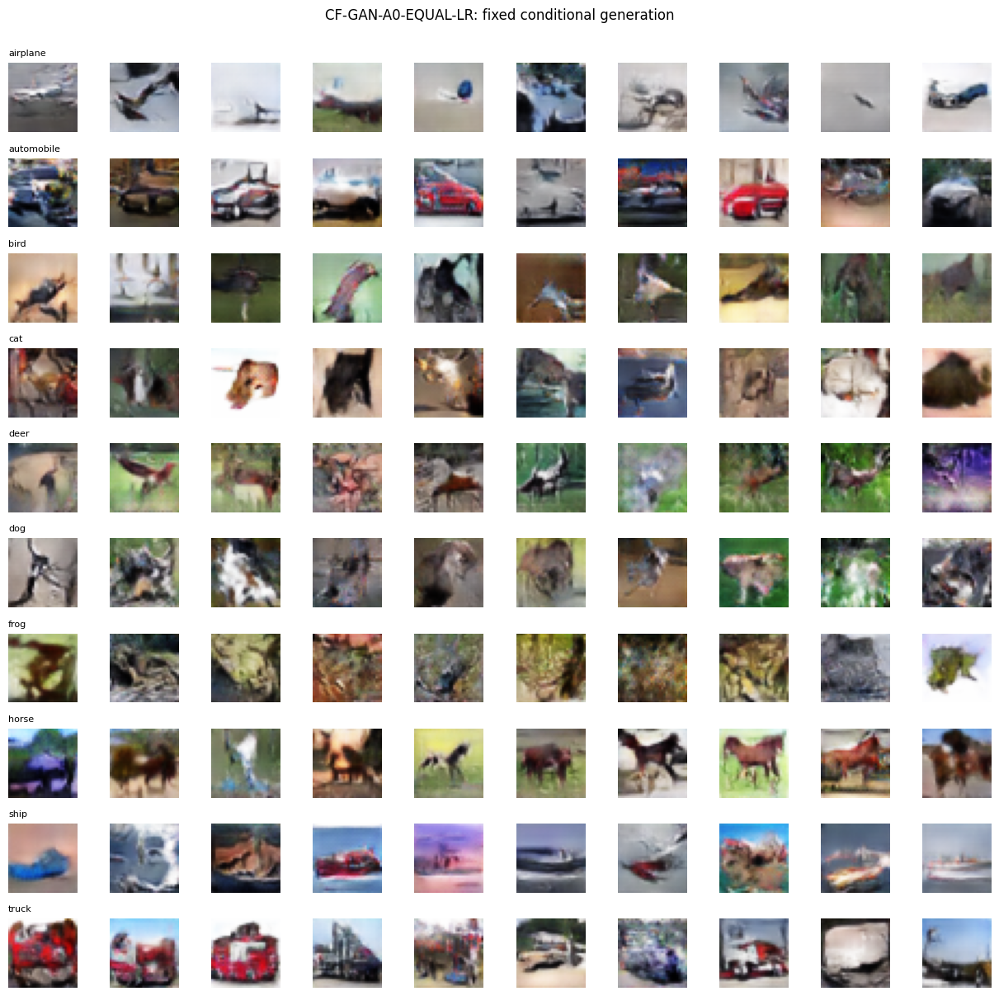

In [45]:
model_id = GAN_A0_ID
gan = cf_gan_models[model_id]
path = CHECKPOINT_DIR / model_id / "best_generator.weights.h5"

if path.exists():
    generated = gan.generator(
        [fixed_gan_noise, fixed_labels],
        training=False,
    ).numpy()
    plot_generated_by_class(
        generated,
        fixed_labels.numpy(),
        title=f"{model_id}: fixed conditional generation",
    )

#### Evaluation

A0 produces sharper edges, stronger object-like structure and more within-class variation than the VAE grids. The visual evidence agrees with its strong metrics: **FID 40.503 ± 0.478**, **IS 4.569 ± 0.016** and **60.34% conditioning accuracy**. It is retained as Chun Fei's GAN finalist.

### `GAN_A1` fixed conditional grid

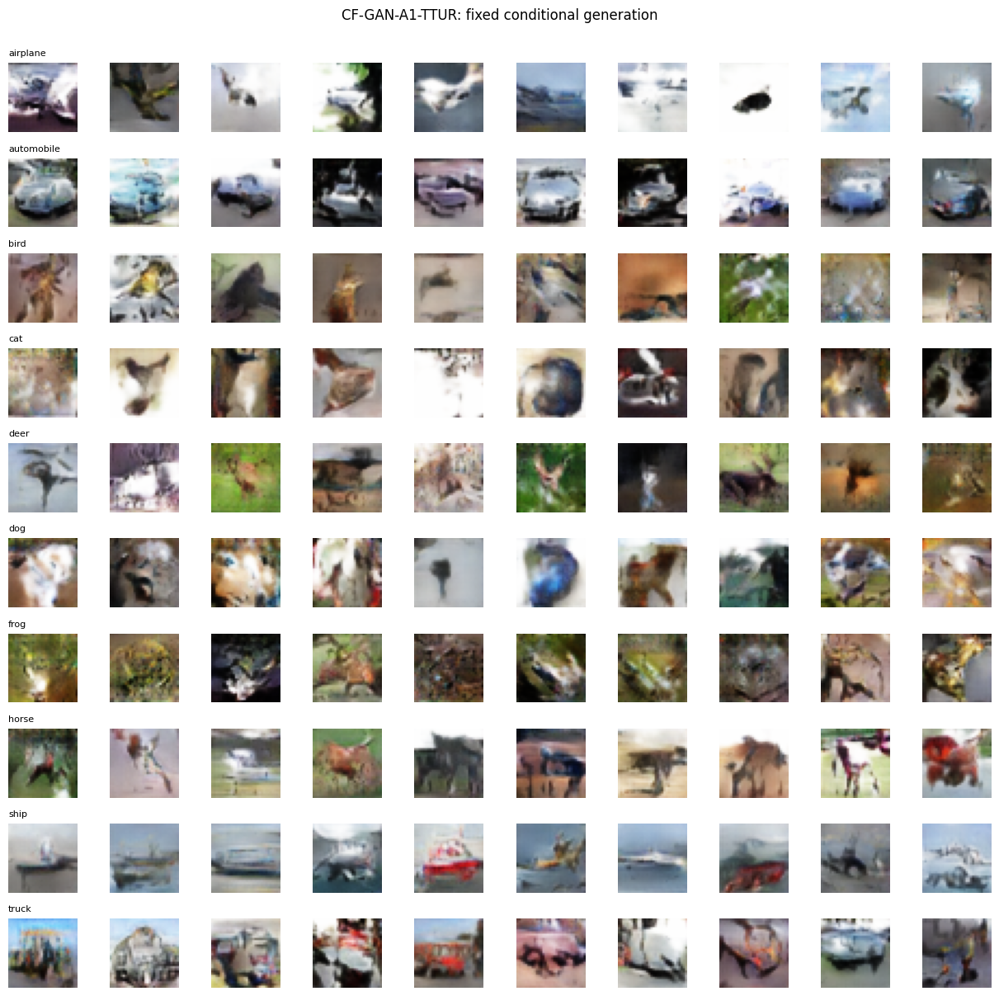

In [45]:
model_id = GAN_A1_ID
gan = cf_gan_models[model_id]
path = CHECKPOINT_DIR / model_id / "best_generator.weights.h5"

if path.exists():
    generated = gan.generator(
        [fixed_gan_noise, fixed_labels],
        training=False,
    ).numpy()
    plot_generated_by_class(
        generated,
        fixed_labels.numpy(),
        title=f"{model_id}: fixed conditional generation",
    )

#### Evaluation

The TTUR grid still contains varied CIFAR-10-like samples, but requested-class identity is less reliable. This matches the weaker **FID 46.090**, **IS 4.302** and **54.16% conditioning accuracy**, so the visual evidence does not justify replacing A0.

## GAN training dynamics

Each cell contains the **two directly related training plots** for one GAN: adversarial losses and discriminator logits.

### `GAN_A0` training curves

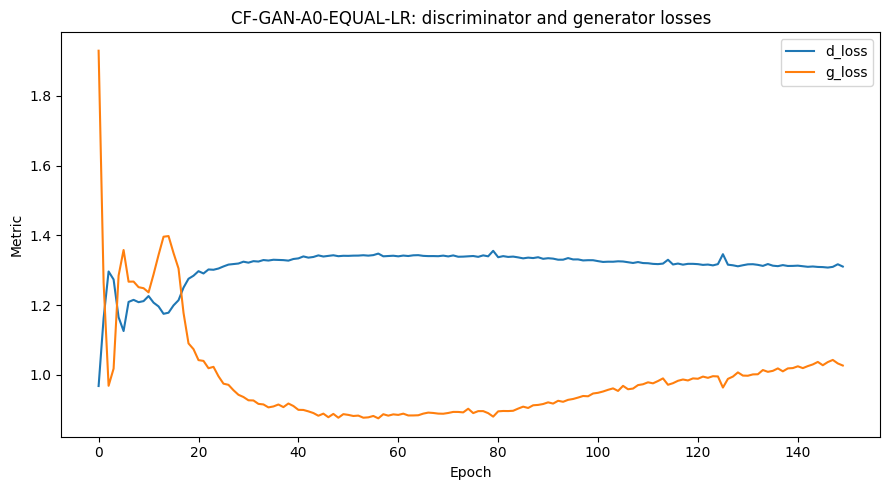

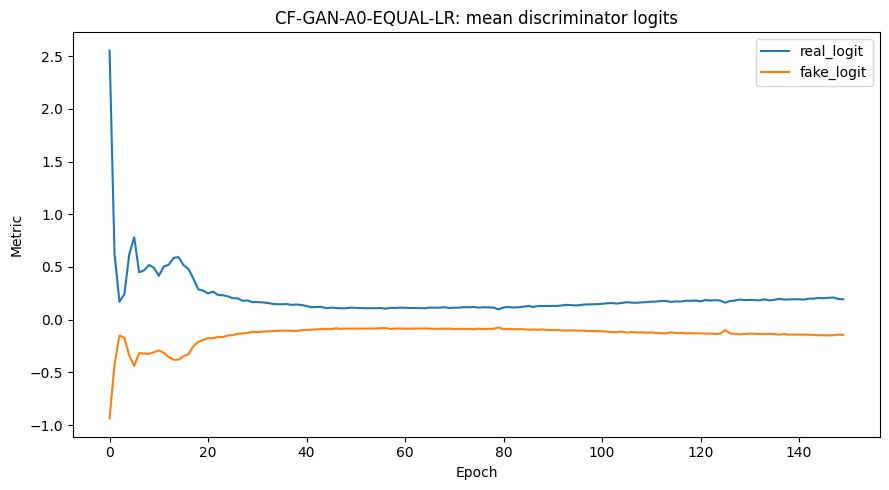

In [46]:
model_id = GAN_A0_ID
history_path = RESULT_DIR / f"{model_id}_history.json"

if history_path.exists():
    with open(history_path, "r", encoding="utf-8") as file:
        history_data = json.load(file)

    plot_history(
        history_data,
        ["d_loss", "g_loss"],
        f"{model_id}: discriminator and generator losses",
    )
    plot_history(
        history_data,
        ["real_logit", "fake_logit"],
        f"{model_id}: mean discriminator logits",
    )

#### Evaluation

The generator/discriminator losses oscillate early and then settle into a more stable adversarial regime. Real and fake logits move closer together over training, suggesting that neither network remains overwhelmingly dominant. This training behaviour is consistent with A0's stronger final FID, IS and class-control results.

### `GAN_A1` training curves

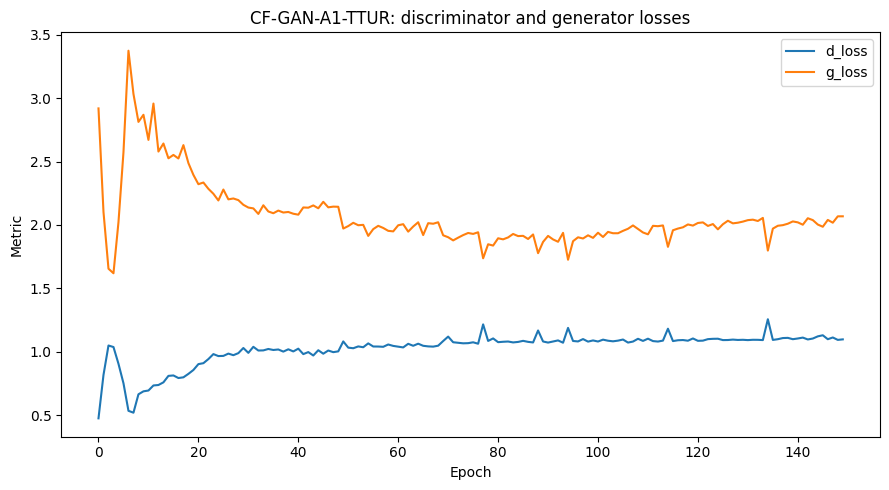

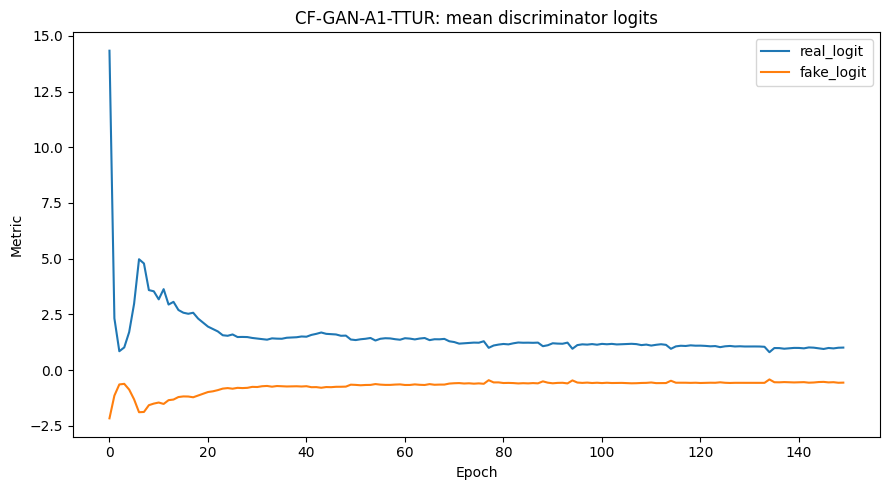

In [46]:
model_id = GAN_A1_ID
history_path = RESULT_DIR / f"{model_id}_history.json"

if history_path.exists():
    with open(history_path, "r", encoding="utf-8") as file:
        history_data = json.load(file)

    plot_history(
        history_data,
        ["d_loss", "g_loss"],
        f"{model_id}: discriminator and generator losses",
    )
    plot_history(
        history_data,
        ["real_logit", "fake_logit"],
        f"{model_id}: mean discriminator logits",
    )

#### Evaluation

With the slower generator, generator loss remains higher and the discriminator keeps a clearer separation between real and fake logits. In this setup, TTUR therefore leaves the discriminator comparatively stronger instead of improving the balance. The final metrics worsen across all major measures, so A1 is rejected.

In [47]:

GAN_CONFIGS = {
    GAN_A0_ID: {
        "g_learning_rate": GAN_A0_G_LR,
        "d_learning_rate": GAN_A0_D_LR,
    },
    GAN_A1_ID: {
        "g_learning_rate": GAN_A1_G_LR,
        "d_learning_rate": GAN_A1_D_LR,
    },
}


def evaluate_gan_model(
    model_id,
    gan,
    run_fid,
    run_is,
    evaluation_seed=SEED + 30_000,
):
    metric_results = repeated_distribution_evaluation(
        generate_fn=(
            lambda n, seed, g=gan:
            generate_gan_balanced(
                g,
                n_per_class=n,
                seed=seed,
            )
        ),
        model_id=model_id,
        run_fid=run_fid,
        run_is=run_is,
    )

    fid_result = (
        metric_results["fid"]
        or load_saved_metric_result(
            model_id,
            "fid",
        )
    )
    is_result = (
        metric_results["is"]
        or load_saved_metric_result(
            model_id,
            "is",
        )
    )

    images, labels = generate_gan_balanced(
        gan,
        n_per_class=500,
        seed=evaluation_seed,
    )

    conditioning = evaluate_conditioning(
        images,
        labels,
        classifier,
        show_confusion=False,
    )

    config = GAN_CONFIGS[model_id]

    return {
        "model_id": model_id,
        "g_learning_rate": config[
            "g_learning_rate"
        ],
        "d_learning_rate": config[
            "d_learning_rate"
        ],
        "fid5k_mean": (
            fid_result["fid_mean"]
            if fid_result is not None
            else np.nan
        ),
        "fid5k_std": (
            fid_result["fid_std"]
            if fid_result is not None
            else np.nan
        ),
        "is5k_mean": (
            is_result["is_mean"]
            if is_result is not None
            else np.nan
        ),
        "is5k_std": (
            is_result["is_std"]
            if is_result is not None
            else np.nan
        ),
        "conditioning_accuracy": (
            conditioning["overall_accuracy"]
        ),
        "mean_confidence": (
            conditioning["mean_confidence"]
        ),
        "requested_class_confidence": conditioning[
            "mean_requested_confidence"
        ],
        "exact_duplicate_rate": (
            exact_duplicate_rate(images)
        ),
        "generator_parameters": (
            gan.generator.count_params()
        ),
        "discriminator_parameters": (
            gan.discriminator.count_params()
        ),
    }


gan_rows = []

if (
    RUN_FID_EVALUATION_GAN
    or RUN_IS_EVALUATION_GAN
):
    for model_id in [
        GAN_A0_ID,
        GAN_A1_ID,
    ]:
        gan = cf_gan_models[model_id]
        path = (
            CHECKPOINT_DIR
            / model_id
            / "best_generator.weights.h5"
        )

        if not path.exists():
            print(
                "Skipping evaluation because weights "
                f"were not found for {model_id}."
            )
            continue

        gan_rows.append(
            evaluate_gan_model(
                model_id=model_id,
                gan=gan,
                run_fid=RUN_FID_EVALUATION_GAN,
                run_is=RUN_IS_EVALUATION_GAN,
            )
        )

    gan_comparison_table = pd.DataFrame(
        gan_rows,
    )
    gan_comparison_table.to_csv(
        RESULT_DIR
        / "CF_GAN_A0_vs_A1_TTUR_evaluation.csv",
        index=False,
    )
    display(gan_comparison_table)
else:
    print(
        "GAN FID/IS are not recomputed in this run. "
        "Previously saved GAN metrics are reused by SHOW_SAVED_REVIEW."
    )


GAN FID/IS are not recomputed in this run. Previously saved GAN metrics are reused by SHOW_SAVED_REVIEW.


## GAN decision — equal learning rates retained

| Metric | `CF-GAN-A0-EQUAL-LR` | `CF-GAN-A1-TTUR` | Better |
|---|---:|---:|---|
| FID@5k ↓ | **40.503 ± 0.478** | 46.090 ± 0.089 | **A0** |
| IS@5k ↑ | **4.569 ± 0.016** | 4.302 ± 0.042 | **A0** |
| Conditioning accuracy ↑ | **60.34%** | 54.16% | **A0** |
| Requested-class confidence ↑ | **57.52%** | 51.08% | **A0** |
| Exact duplicate rate ↓ | 0.00% | 0.00% | Tie |
| Generator parameters ↓ | 1,247,267 | 1,247,267 | Tie |

Lowering the generator learning rate from `2e-4` to `1e-4` while keeping the discriminator at `2e-4` worsened every major quality and class-control metric. TTUR is therefore **rejected**, and `CF-GAN-A0-EQUAL-LR` is retained as Chun Fei's GAN finalist.


In [48]:

if SELECTED_GAN_MODEL_ID not in cf_gan_models:
    raise ValueError(
        "SELECTED_GAN_MODEL_ID must be "
        f"{GAN_A0_ID!r} or {GAN_A1_ID!r}."
    )

FINAL_CF_GAN_ID = SELECTED_GAN_MODEL_ID

print(
    "Current Chun Fei GAN candidate:",
    FINAL_CF_GAN_ID,
)
print(
    "This is not the overall group winner."
)


Current Chun Fei GAN candidate: CF-GAN-A0-EQUAL-LR
This is not the overall group winner.


# 8. Chun Fei individual model selection

```text
Selected VAE: CF-VAE-A4-CCL
Selected GAN: CF-GAN-A0-EQUAL-LR
```

`CF-VAE-A4-CCL` is retained as Chun Fei's VAE finalist because the class-consistency objective produced the strongest class control among the VAE experiments while preserving a usable latent representation.

For the supporting GAN experiment, TTUR was rejected: decreasing only the generator learning rate from `2e-4` to `1e-4` worsened FID, Inception Score, conditioning accuracy and requested-class confidence. The equal-learning-rate baseline `CF-GAN-A0-EQUAL-LR` is therefore retained.

These two frozen checkpoints are handed to the shared final-evaluation notebook. The group-level four-finalist comparison, grayscale discussion, easiest/hardest-class verdict and final 1,000-image export are intentionally not duplicated here.


# 9. Individual finalist class-control diagnostics

You Xuan's individual notebook usefully opens whole-model scores into **class-level behaviour**. The same idea is added here for Chun Fei's two selected finalists.

This section is deliberately **individual**, not the final team answer to the easiest/hardest-class question. It asks:

- which requested classes each Chun Fei finalist follows more or less reliably;
- what classes the shared evaluator confuses with one another;
- whether generated samples retain reasonable within-class variation relative to real CIFAR-10 images.

The formal group-level class verdict remains in the shared notebook because all four finalists must be judged under one identical protocol.

Set `RUN_INDIVIDUAL_FINALIST_DIAGNOSTICS = True` for an evaluation-only run. No training occurs.


In [49]:
def individual_class_control_diagnostics(
    model_id,
    images,
    requested_labels,
    classifier_model,
):
    """Per-class accuracy, requested confidence and row-normalised confusion."""
    images = ensure_01(images)
    requested_labels = np.asarray(requested_labels).reshape(-1).astype(np.int32)

    probabilities = classifier_model.predict(
        images,
        batch_size=BATCH_SIZE,
        verbose=0,
    )
    predictions = probabilities.argmax(axis=1)
    requested_probability = probabilities[
        np.arange(len(requested_labels)),
        requested_labels,
    ]

    rows = []
    for class_id, class_name in enumerate(CLASS_NAMES):
        mask = requested_labels == class_id
        rows.append({
            "model_id": model_id,
            "class_id": class_id,
            "class_name": class_name,
            "conditioning_accuracy": float(
                np.mean(predictions[mask] == class_id)
            ),
            "mean_requested_class_confidence": float(
                requested_probability[mask].mean()
            ),
        })

    table = pd.DataFrame(rows)
    cm = confusion_matrix(
        requested_labels,
        predictions,
        labels=np.arange(NUM_CLASSES),
        normalize="true",
    )

    figure, axes = plt.subplots(1, 3, figsize=(18, 5.2))

    axes[0].barh(
        table["class_name"],
        table["conditioning_accuracy"],
    )
    axes[0].axvline(
        table["conditioning_accuracy"].mean(),
        linestyle="--",
        label=(
            "mean = "
            f"{table['conditioning_accuracy'].mean():.3f}"
        ),
    )
    axes[0].set_xlim(0, 1)
    axes[0].set_xlabel("Conditioning accuracy")
    axes[0].set_title(f"{model_id}: per-class accuracy")
    axes[0].legend()

    axes[1].barh(
        table["class_name"],
        table["mean_requested_class_confidence"],
    )
    axes[1].axvline(
        table["mean_requested_class_confidence"].mean(),
        linestyle="--",
        label=(
            "mean = "
            f"{table['mean_requested_class_confidence'].mean():.3f}"
        ),
    )
    axes[1].set_xlim(0, 1)
    axes[1].set_xlabel("Requested-class confidence")
    axes[1].set_title(f"{model_id}: requested confidence")
    axes[1].legend()

    image = axes[2].imshow(cm, vmin=0, vmax=1)
    axes[2].set_xticks(np.arange(NUM_CLASSES))
    axes[2].set_yticks(np.arange(NUM_CLASSES))
    axes[2].set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
    axes[2].set_yticklabels(CLASS_NAMES)
    axes[2].set_xlabel("Classifier prediction")
    axes[2].set_ylabel("Requested class")
    axes[2].set_title("Row-normalised confusion matrix")
    figure.colorbar(image, ax=axes[2], fraction=0.046, pad=0.04)

    figure.suptitle(f"Individual class-control diagnostic — {model_id}")
    plt.tight_layout()
    figure.savefig(
        REVIEW_FIGURE_DIR / f"{model_id}_individual_class_control.png",
        dpi=170, bbox_inches="tight"
    )
    plt.show()

    return table, cm


def mean_pairwise_pixel_distance(images):
    """Efficient mean Euclidean distance between all image pairs."""
    flat = ensure_01(images).reshape(len(images), -1).astype(np.float64)
    sq = np.sum(flat * flat, axis=1, keepdims=True)
    d2 = np.maximum(sq + sq.T - 2.0 * (flat @ flat.T), 0.0)
    distances = np.sqrt(d2)
    upper = np.triu_indices(len(flat), k=1)
    return float(distances[upper].mean())


def within_class_diversity_table(
    generated_sets,
    real_images,
    real_labels,
    n_per_class=60,
):
    """Pixel-space diversity is a rough collapse diagnostic, not a semantic metric."""
    rows = []

    for class_id, class_name in enumerate(CLASS_NAMES):
        real_class = ensure_01(
            real_images[np.asarray(real_labels).reshape(-1) == class_id]
        )[:n_per_class]
        real_distance = mean_pairwise_pixel_distance(real_class)
        rows.append({
            "source": "Real test images",
            "class_id": class_id,
            "class_name": class_name,
            "mean_pairwise_pixel_distance": real_distance,
            "relative_to_real": 1.0,
        })

        for model_id, (images, labels) in generated_sets.items():
            mask = np.asarray(labels).reshape(-1) == class_id
            generated_class = images[mask][:n_per_class]
            generated_distance = mean_pairwise_pixel_distance(generated_class)
            rows.append({
                "source": model_id,
                "class_id": class_id,
                "class_name": class_name,
                "mean_pairwise_pixel_distance": generated_distance,
                "relative_to_real": (
                    generated_distance / real_distance
                    if real_distance > 0 else np.nan
                ),
            })

    return pd.DataFrame(rows)


if RUN_INDIVIDUAL_FINALIST_DIAGNOSTICS:
    if not classifier_weights.exists() and not TRAIN_EVAL_CLASSIFIER:
        raise FileNotFoundError(
            "Shared evaluation-classifier weights are required for diagnostics."
        )

    vae_path = CHECKPOINT_DIR / FINAL_CF_VAE_ID / "best.weights.h5"
    gan_path = CHECKPOINT_DIR / FINAL_CF_GAN_ID / "best_generator.weights.h5"
    if not vae_path.exists():
        raise FileNotFoundError(vae_path)
    if not gan_path.exists():
        raise FileNotFoundError(gan_path)

    vae_images, vae_labels = generate_vae_balanced(
        cf_vae_models[FINAL_CF_VAE_ID],
        n_per_class=100,
        seed=SEED + 41_000,
    )
    gan_images, gan_labels = generate_gan_balanced(
        cf_gan_models[FINAL_CF_GAN_ID],
        n_per_class=100,
        seed=SEED + 42_000,
    )

    finalist_generated_sets = {
        FINAL_CF_VAE_ID: (vae_images, vae_labels),
        FINAL_CF_GAN_ID: (gan_images, gan_labels),
    }

    class_tables = []
    for model_id, (images, labels) in finalist_generated_sets.items():
        table, cm = individual_class_control_diagnostics(
            model_id,
            images,
            labels,
            classifier,
        )
        table.to_csv(
            RESULT_DIR / f"{model_id}_individual_per_class_control.csv",
            index=False,
        )
        np.save(
            RESULT_DIR / f"{model_id}_individual_confusion_matrix.npy",
            cm,
        )
        class_tables.append(table)

    individual_per_class_table = pd.concat(
        class_tables,
        ignore_index=True,
    )
    display(individual_per_class_table)

    diversity_table = within_class_diversity_table(
        finalist_generated_sets,
        x_test_vae,
        y_test,
        n_per_class=60,
    )
    diversity_table.to_csv(
        RESULT_DIR / "CF_individual_finalist_within_class_diversity.csv",
        index=False,
    )

    pivot = diversity_table.pivot(
        index="class_name",
        columns="source",
        values="mean_pairwise_pixel_distance",
    ).reindex(CLASS_NAMES)

    x = np.arange(NUM_CLASSES)
    sources = list(pivot.columns)
    width = 0.8 / len(sources)
    plt.figure(figsize=(13, 5))
    for source_index, source_name in enumerate(sources):
        offset = (source_index - (len(sources) - 1) / 2) * width
        plt.bar(
            x + offset,
            pivot[source_name].values,
            width=width,
            label=source_name,
        )
    plt.xticks(x, CLASS_NAMES, rotation=45)
    plt.ylabel("Mean pairwise pixel distance")
    plt.title(
        "Within-class diversity — Chun Fei finalists vs real test images\n"
        "Lower generated values may indicate reduced within-class variety"
    )
    plt.legend()
    plt.tight_layout()
    plt.savefig(
        REVIEW_FIGURE_DIR / "CF_individual_finalist_within_class_diversity.png",
        dpi=170, bbox_inches="tight"
    )
    plt.show()

    print(
        "These plots diagnose Chun Fei's own finalists only. "
        "Do not use them as the final group easiest/hardest-class verdict."
    )
else:
    print(
        "Set RUN_INDIVIDUAL_FINALIST_DIAGNOSTICS=True to run per-class "
        "accuracy, requested confidence, confusion matrices and diversity "
        "for Chun Fei's selected VAE and GAN."
    )


Set RUN_INDIVIDUAL_FINALIST_DIAGNOSTICS=True to run per-class accuracy, requested confidence, confusion matrices and diversity for Chun Fei's selected VAE and GAN.


## Optional memorisation screen

You Xuan also compares generated samples with their nearest real training examples. That is a useful **screening diagnostic** because a generator that simply reproduces training images would have unusually tiny nearest-neighbour distances.

The check below is intentionally optional and conservative:

- one high-confidence generated sample is selected per class for each Chun Fei finalist;
- the nearest real training image from the same class is displayed;
- pixel-space distance is reported.

This is **not proof of non-memorisation** and pixel distance is not a perceptual metric, but it adds a useful individual diagnostic that is different from the shared final comparison. Set `RUN_MEMORIZATION_SCREEN = True` after the finalist models and shared classifier are loaded.


In [50]:
def nearest_same_class_training_example(
    query_image,
    class_id,
    bank_size=1_000,
):
    class_bank = ensure_01(
        x_train_vae[np.asarray(y_train).reshape(-1) == class_id]
    )[:bank_size]
    flat_bank = class_bank.reshape(len(class_bank), -1).astype(np.float32)
    query = ensure_01(query_image[None, ...]).reshape(1, -1).astype(np.float32)
    distances = np.linalg.norm(flat_bank - query, axis=1)
    index = int(np.argmin(distances))
    return class_bank[index], float(distances[index])


def run_memorization_screen(model_id, images, labels):
    probabilities = classifier.predict(
        ensure_01(images),
        batch_size=BATCH_SIZE,
        verbose=0,
    )
    labels = np.asarray(labels).reshape(-1).astype(np.int32)

    selected_indices = []
    for class_id in range(NUM_CLASSES):
        class_indices = np.flatnonzero(labels == class_id)
        requested_probabilities = probabilities[class_indices, class_id]
        selected_indices.append(
            int(class_indices[np.argmax(requested_probabilities)])
        )

    selected_images = ensure_01(images[np.asarray(selected_indices)])
    nearest_images = []
    rows = []

    for class_id, generated_image in enumerate(selected_images):
        nearest_image, distance = nearest_same_class_training_example(
            generated_image,
            class_id,
        )
        nearest_images.append(nearest_image)
        rows.append({
            "model_id": model_id,
            "class_id": class_id,
            "class_name": CLASS_NAMES[class_id],
            "generated_to_nearest_training_pixel_distance": distance,
        })

    figure, axes = plt.subplots(2, NUM_CLASSES, figsize=(15, 3.4))
    for class_id in range(NUM_CLASSES):
        axes[0, class_id].imshow(selected_images[class_id])
        axes[0, class_id].axis("off")
        axes[0, class_id].set_title(CLASS_NAMES[class_id], fontsize=8)
        axes[1, class_id].imshow(nearest_images[class_id])
        axes[1, class_id].axis("off")
        axes[1, class_id].set_title(
            f"d={rows[class_id]['generated_to_nearest_training_pixel_distance']:.1f}",
            fontsize=7,
        )
    axes[0, 0].set_ylabel("Generated")
    axes[1, 0].set_ylabel("Nearest real")
    figure.suptitle(
        f"{model_id}: high-confidence generated sample vs nearest same-class training image"
    )
    plt.tight_layout()
    figure.savefig(
        REVIEW_FIGURE_DIR / f"{model_id}_nearest_real_screen.png",
        dpi=170, bbox_inches="tight"
    )
    plt.show()

    return pd.DataFrame(rows)


if RUN_MEMORIZATION_SCREEN:
    if not RUN_INDIVIDUAL_FINALIST_DIAGNOSTICS:
        # Generate the same compact diagnostic sets if the previous stage was not run.
        vae_images, vae_labels = generate_vae_balanced(
            cf_vae_models[FINAL_CF_VAE_ID],
            n_per_class=100,
            seed=SEED + 41_000,
        )
        gan_images, gan_labels = generate_gan_balanced(
            cf_gan_models[FINAL_CF_GAN_ID],
            n_per_class=100,
            seed=SEED + 42_000,
        )
        finalist_generated_sets = {
            FINAL_CF_VAE_ID: (vae_images, vae_labels),
            FINAL_CF_GAN_ID: (gan_images, gan_labels),
        }

    memorization_tables = []
    for model_id, (images, labels) in finalist_generated_sets.items():
        table = run_memorization_screen(model_id, images, labels)
        memorization_tables.append(table)

    memorization_table = pd.concat(memorization_tables, ignore_index=True)
    memorization_table.to_csv(
        RESULT_DIR / "CF_individual_finalist_nearest_real_screen.csv",
        index=False,
    )
    display(memorization_table)
else:
    print(
        "The optional nearest-real-image screen is not recomputed in this run. Any saved screen is reused by SHOW_SAVED_REVIEW."
    )


The optional nearest-real-image screen is not recomputed in this run. Any saved screen is reused by SHOW_SAVED_REVIEW.


# 10. Persistent saved-results review

This section provides a lightweight way to reload and display saved results without retraining: **rerunning a
cell replaces that cell's previous output**. Training flags therefore should
not be used as a way to preserve evidence.

Instead, `SHOW_SAVED_REVIEW = True` keeps this final review active. It reads
the already-saved histories, CSV/JSON/NPY files and checkpoints, then redraws
the graphs. It never calls `.fit()` and never overwrites a checkpoint.

That means a typical workflow is:

```text
train/evaluate a stage once
        ↓
results are saved to disk
        ↓
later Restart Kernel → Run All
        ↓
training flags can be False
        ↓
SHOW_SAVED_REVIEW = True
        ↓
plots/tables are reconstructed and remain visible in the final notebook
```

The review below follows the same saved-results workflow used across the project: each
small group of related plots is followed immediately by its interpretation.

In [51]:
# Purpose: lightweight helpers used only to reload and present saved evidence.
def _review_read_csv(path):
    path = Path(path)
    if not path.exists():
        print(f"[saved table not found] {path}")
        return None
    return pd.read_csv(path)


def _review_display_png(path, title=None):
    path = Path(path)
    if not path.exists():
        print(f"[saved figure not found] {path}")
        return False
    if title:
        display(Markdown(f"### {title}"))
    display(IPyImage(filename=str(path)))
    return True


def _review_grouped_percent_bars(
    table,
    model_col,
    value_cols,
    labels,
    title,
):
    x = np.arange(len(table))
    width = 0.8 / len(value_cols)

    fig, ax = plt.subplots(figsize=(11, 5))
    for j, (column, label) in enumerate(zip(value_cols, labels)):
        if column not in table.columns:
            continue
        offset = (j - (len(value_cols) - 1) / 2) * width
        ax.bar(
            x + offset,
            100.0 * table[column].astype(float).to_numpy(),
            width=width,
            label=label,
        )

    ax.set_xticks(x)
    ax.set_xticklabels(table[model_col], rotation=35, ha="right")
    ax.set_ylabel("Percent")
    ax.set_ylim(0, 100)
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.25, axis="y")
    plt.tight_layout()
    plt.show()


def _review_two_metric_bars(
    table,
    model_col,
    left_col,
    right_col,
    left_title,
    right_title,
):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

    axes[0].bar(table[model_col], table[left_col].astype(float))
    axes[0].set_title(left_title)
    axes[0].tick_params(axis="x", rotation=35)
    axes[0].grid(alpha=0.25, axis="y")

    axes[1].bar(table[model_col], table[right_col].astype(float))
    axes[1].set_title(right_title)
    axes[1].tick_params(axis="x", rotation=35)
    axes[1].grid(alpha=0.25, axis="y")

    plt.tight_layout()
    plt.show()


def _review_confusion_from_npy(model_id):
    path = RESULT_DIR / f"{model_id}_individual_confusion_matrix.npy"
    if not path.exists():
        print(f"[saved confusion matrix not found] {path}")
        return

    cm = np.load(path)
    fig, ax = plt.subplots(figsize=(7.2, 6.2))
    image = ax.imshow(cm, vmin=0, vmax=1)
    ax.set_xticks(np.arange(NUM_CLASSES))
    ax.set_yticks(np.arange(NUM_CLASSES))
    ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
    ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("Classifier prediction")
    ax.set_ylabel("Requested class")
    ax.set_title(f"{model_id}: row-normalised confusion matrix")
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()


if SHOW_SAVED_REVIEW:
    print(
        "Persistent saved-results review is active. "
        "No model training is performed by this review section."
    )
else:
    print("Persistent saved-results review is disabled.")

Persistent saved-results review is active. No model training is performed by this review section.


## 10.1 VAE distribution-quality comparison

FID and Inception Score describe complementary aspects of the generated
distribution. Lower FID is better; higher IS is better. They are presented
together here because neither should be used as the only VAE selection rule.

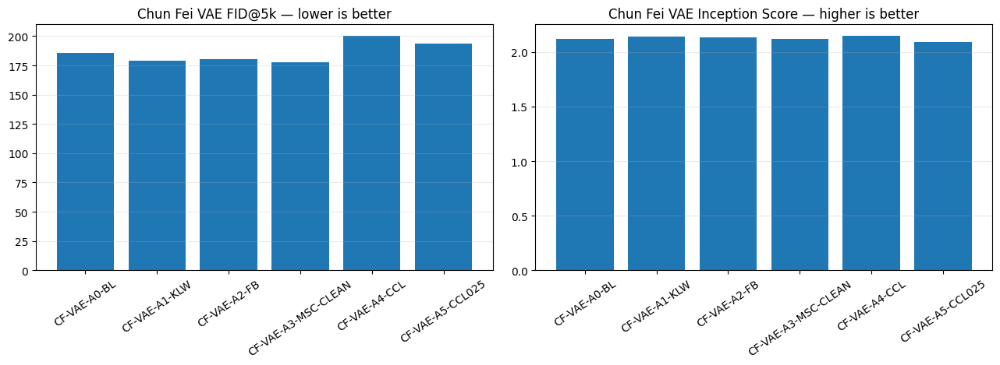

In [52]:
if SHOW_SAVED_REVIEW:
    _vae_review = _review_read_csv(
        RESULT_DIR / "CF_VAE_RETAINED_PATH_evaluation.csv"
    )

    if _vae_review is not None and not _vae_review.empty:
        needed = {"model_id", "fid5k_mean", "is5k_mean"}
        if needed.issubset(_vae_review.columns):
            _review_two_metric_bars(
                _vae_review,
                model_col="model_id",
                left_col="fid5k_mean",
                right_col="is5k_mean",
                left_title="Chun Fei VAE FID@5k — lower is better",
                right_title="Chun Fei VAE Inception Score — higher is better",
            )
        else:
            print("Saved VAE table is missing one or more quality columns:", needed)

### Evaluation

The VAE results show why a single metric is insufficient. `CF-VAE-A3-MSC-CLEAN`
has the strongest FID, whereas `CF-VAE-A4-CCL` has the strongest VAE
Inception Score and, more importantly for a conditional generator, a much
larger class-control improvement. A4 is therefore not described as the best
VAE on every metric; it is the selected **conditional** VAE after accepting a
FID penalty for substantially stronger semantic control.

## 10.2 VAE requested-class control

Conditioning accuracy checks whether the evaluator predicts the requested
CIFAR-10 label. Requested-class confidence measures how much probability the
evaluator assigns to that requested label. These two related measures are
shown together.

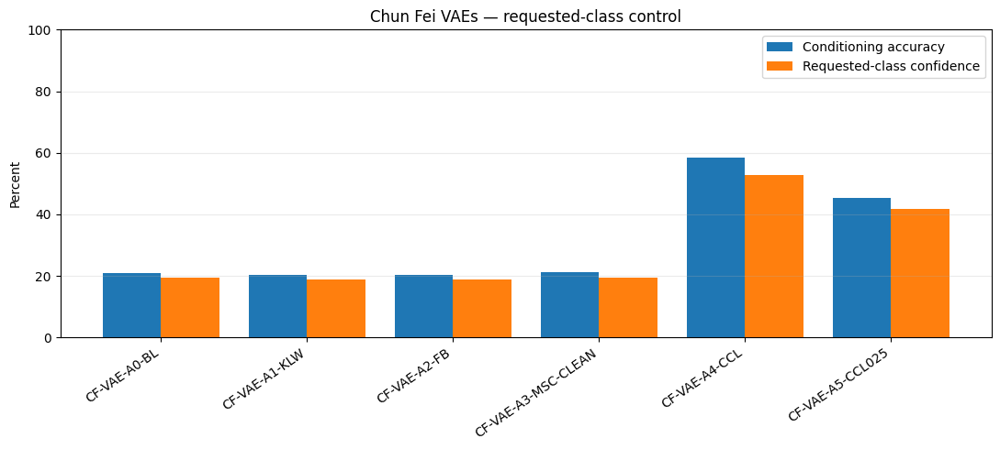

In [53]:
if SHOW_SAVED_REVIEW and "_vae_review" in globals():
    if _vae_review is not None and not _vae_review.empty:
        cols = {
            "model_id",
            "conditioning_accuracy",
            "requested_class_confidence",
        }
        if cols.issubset(_vae_review.columns):
            _review_grouped_percent_bars(
                _vae_review,
                model_col="model_id",
                value_cols=[
                    "conditioning_accuracy",
                    "requested_class_confidence",
                ],
                labels=[
                    "Conditioning accuracy",
                    "Requested-class confidence",
                ],
                title="Chun Fei VAEs — requested-class control",
            )

### Evaluation

A0–A3 remain close to weak class-control levels even when their FID improves.
The decisive change is the auxiliary class-consistency objective: A4 raises
conditioning accuracy from about 21% in A3 to about 58%, while A5 shows that a
lighter weight gives back some FID but loses a substantial part of that class
control. This directly supports choosing A4 over A5 for specified-class
generation.

## 10.3 VAE latent-space usage

A useful VAE should not achieve good reconstruction by ignoring most latent
dimensions. The saved latent summary therefore checks the number of active
dimensions and total raw KL information.

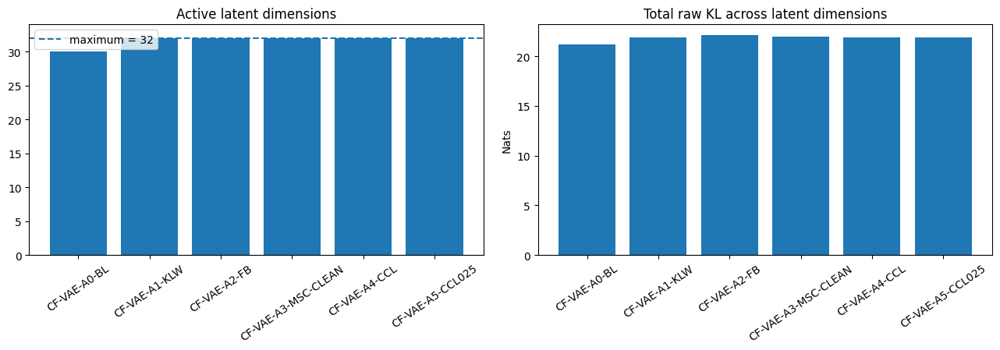

In [54]:
if SHOW_SAVED_REVIEW:
    _latent_review = _review_read_csv(
        RESULT_DIR / "CF_VAE_latent_summary.csv"
    )
    if _latent_review is not None and not _latent_review.empty:
        fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

        axes[0].bar(
            _latent_review["model_id"],
            _latent_review["active_dimensions"],
        )
        axes[0].axhline(
            VAE_LATENT_DIM,
            linestyle="--",
            label=f"maximum = {VAE_LATENT_DIM}",
        )
        axes[0].set_ylim(0, VAE_LATENT_DIM + 2)
        axes[0].set_title("Active latent dimensions")
        axes[0].legend()
        axes[0].tick_params(axis="x", rotation=35)

        axes[1].bar(
            _latent_review["model_id"],
            _latent_review["total_raw_kl"],
        )
        axes[1].set_title("Total raw KL across latent dimensions")
        axes[1].set_ylabel("Nats")
        axes[1].tick_params(axis="x", rotation=35)

        plt.tight_layout()
        plt.show()

### Evaluation

The baseline uses 30 of 32 dimensions, while the later VAE checkpoints use all
32 under the chosen activity threshold. In particular, A4's large gain in
requested-class control is **not** accompanied by a collapse of the latent
representation. The free-bits branch also shows why a mechanism should be
judged by whether it was actually active: at the evaluated A2 checkpoint, the
0.125-nat floor was not meaningfully constraining the dimensions.

## 10.4 Supporting GAN — A0 versus TTUR

The supporting GAN experiment changes only the learning-rate balance. FID/IS
and requested-class control are reloaded from the saved evaluation table so
the comparison remains visible without recomputing Inception features.

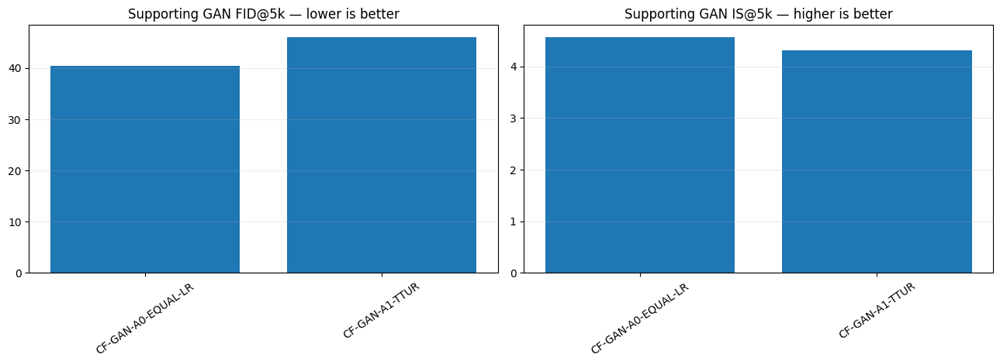

In [55]:
if SHOW_SAVED_REVIEW:
    _gan_review = _review_read_csv(
        RESULT_DIR / "CF_GAN_A0_vs_A1_TTUR_evaluation.csv"
    )
    if _gan_review is not None and not _gan_review.empty:
        needed = {"model_id", "fid5k_mean", "is5k_mean"}
        if needed.issubset(_gan_review.columns):
            _review_two_metric_bars(
                _gan_review,
                model_col="model_id",
                left_col="fid5k_mean",
                right_col="is5k_mean",
                left_title="Supporting GAN FID@5k — lower is better",
                right_title="Supporting GAN IS@5k — higher is better",
            )

### Evaluation

The equal-learning-rate A0 model remains better on both reporting metrics.
TTUR is therefore retained as a **negative controlled result**, not hidden:
lowering only the generator learning rate worsened FID from about 40.5 to 46.1
and also reduced Inception Score. The result shows that a published technique
is not automatically beneficial under every architecture and training budget.

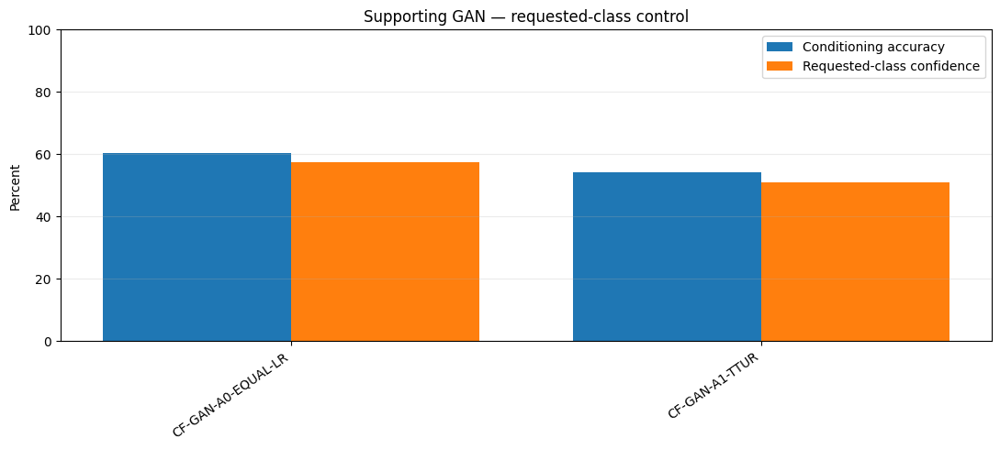

In [56]:
if SHOW_SAVED_REVIEW and "_gan_review" in globals():
    if _gan_review is not None and not _gan_review.empty:
        cols = {
            "model_id",
            "conditioning_accuracy",
            "requested_class_confidence",
        }
        if cols.issubset(_gan_review.columns):
            _review_grouped_percent_bars(
                _gan_review,
                model_col="model_id",
                value_cols=[
                    "conditioning_accuracy",
                    "requested_class_confidence",
                ],
                labels=[
                    "Conditioning accuracy",
                    "Requested-class confidence",
                ],
                title="Supporting GAN — requested-class control",
            )

### Evaluation

The class-control evidence agrees with the distribution metrics: A0 reaches
about 60% conditioning accuracy and 58% requested-class confidence, while the
TTUR variant is lower on both. Since the generator/discriminator architecture
and other settings are fixed, the learning-rate change has no measured
advantage in this experiment.

## 10.5 Selected-finalist requested-class grids

The following grids are regenerated from the **frozen selected checkpoints**
using a fixed seed and 10 images per requested class. This is a lightweight
inference-only check, not a training stage.

### Selected VAE — fixed-seed grid

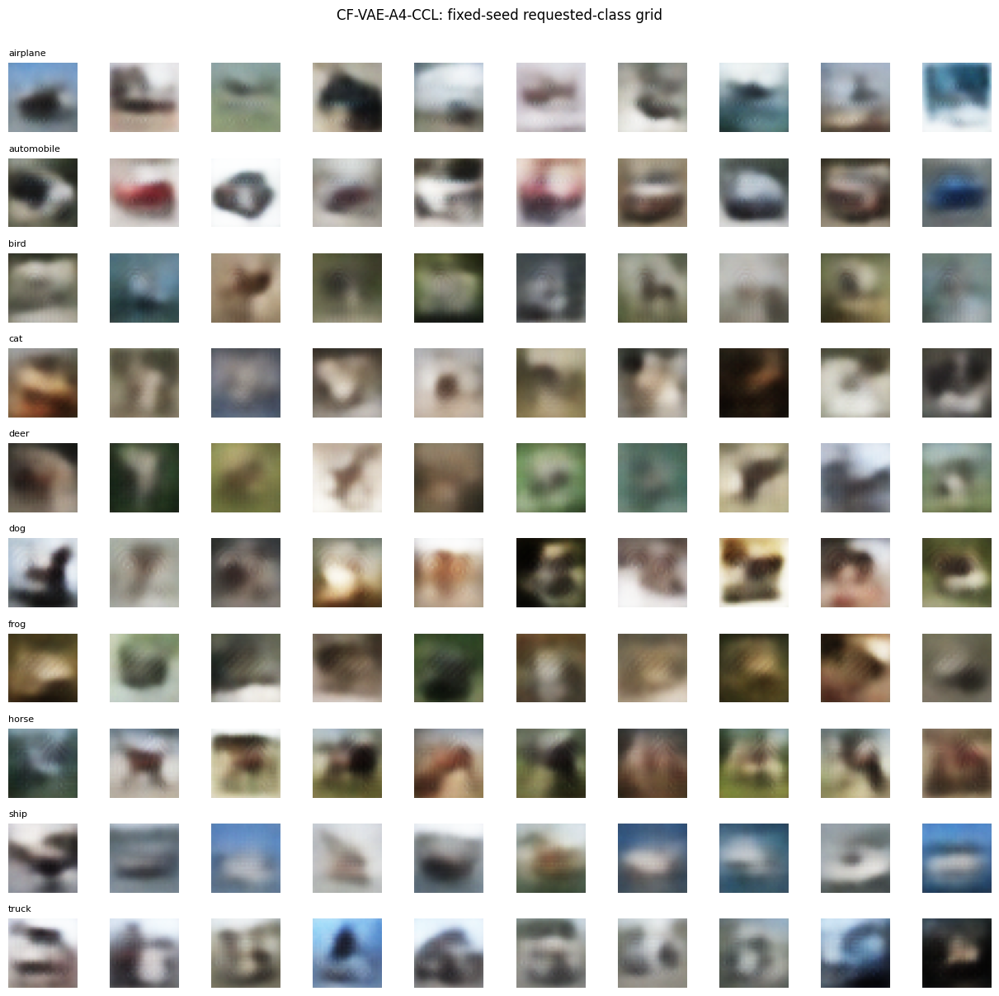

In [57]:
if SHOW_SAVED_REVIEW:
    _review_vae_path = CHECKPOINT_DIR / FINAL_CF_VAE_ID / "best.weights.h5"
    if _review_vae_path.exists():
        _review_vae_images, _review_vae_labels = generate_vae_balanced(
            cf_vae_models[FINAL_CF_VAE_ID],
            n_per_class=10,
            seed=SEED + 61_000,
        )
        plot_generated_by_class(
            _review_vae_images,
            _review_vae_labels,
            f"{FINAL_CF_VAE_ID}: fixed-seed requested-class grid",
            samples_per_class=10,
        )

#### Evaluation

`CF-VAE-A4-CCL` produces smooth, prototype-like images with stronger requested-class cues than the earlier VAEs, but fine detail remains limited. This is consistent with A4 being selected for **class control**, not for the best FID or sharpest appearance.

### Selected GAN — fixed-seed grid

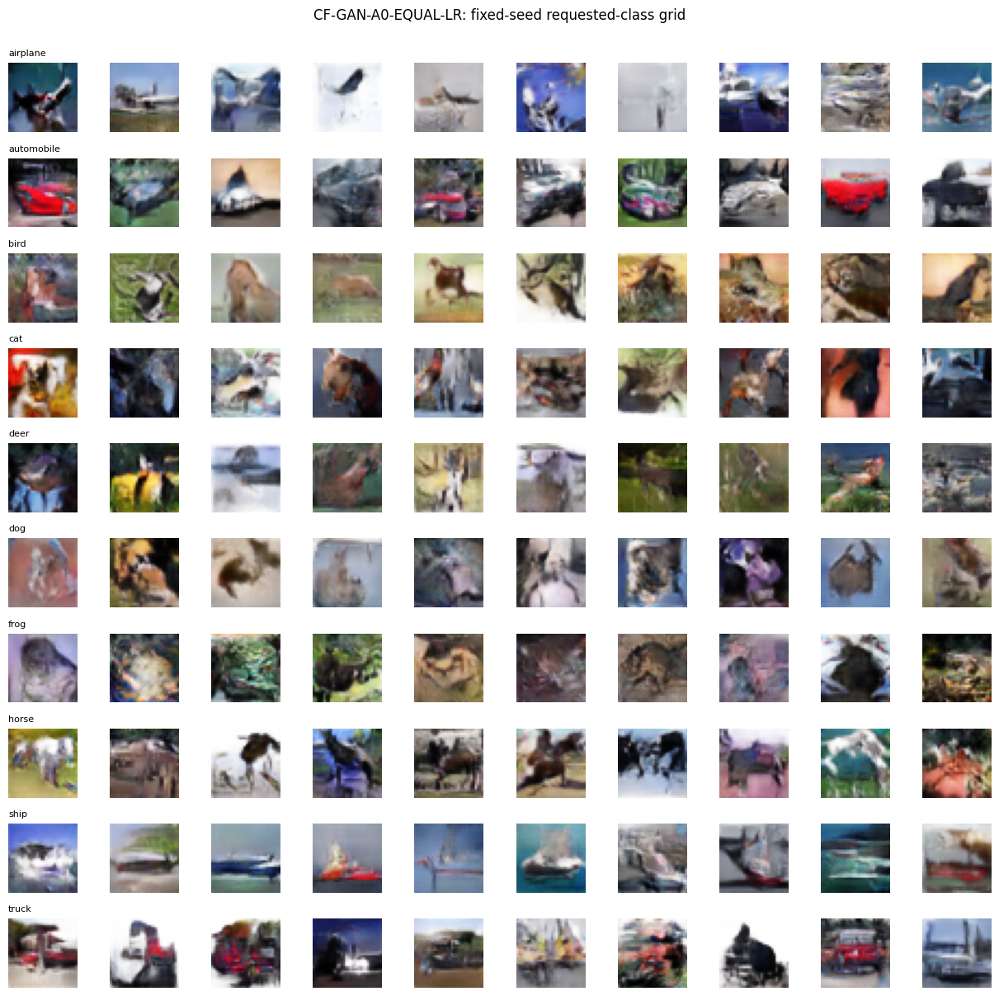

In [57]:
if SHOW_SAVED_REVIEW:
    _review_gan_path = CHECKPOINT_DIR / FINAL_CF_GAN_ID / "best_generator.weights.h5"
    if _review_gan_path.exists():
        _review_gan_images, _review_gan_labels = generate_gan_balanced(
            cf_gan_models[FINAL_CF_GAN_ID],
            n_per_class=10,
            seed=SEED + 62_000,
        )
        plot_generated_by_class(
            _review_gan_images,
            _review_gan_labels,
            f"{FINAL_CF_GAN_ID}: fixed-seed requested-class grid",
            samples_per_class=10,
        )

#### Evaluation

`CF-GAN-A0-EQUAL-LR` produces visibly sharper edges, stronger object structure and greater variation in colour/background. The grid supports the quantitative result that A0 is the stronger of Chun Fei's two finalists for **fidelity and diversity**.

## 10.6 Per-class accuracy, confidence and confusion

Whole-model averages can hide class-specific failure. The saved individual
diagnostic is therefore re-plotted separately for each Chun Fei finalist.
These are **individual finalist diagnostics**, not the final four-model group
answer to the easiest/hardest-class question.

### 10.6A — Selected VAE: per-class accuracy and requested confidence

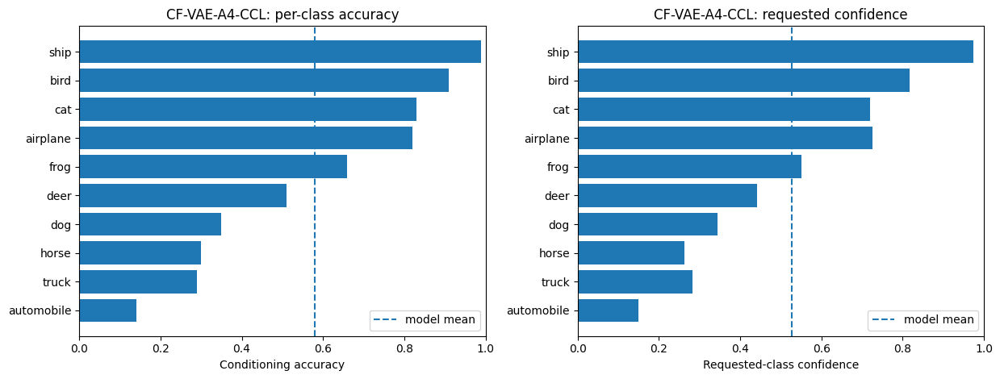

In [58]:
if SHOW_SAVED_REVIEW:
    _model_id = FINAL_CF_VAE_ID
    _path = RESULT_DIR / f"{_model_id}_individual_per_class_control.csv"
    _table = _review_read_csv(_path)

    if _table is not None and not _table.empty:
        _order = np.argsort(
            _table["conditioning_accuracy"].astype(float).to_numpy()
        )

        fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))

        axes[0].barh(
            _table["class_name"].iloc[_order],
            _table["conditioning_accuracy"].astype(float).iloc[_order],
        )
        axes[0].axvline(
            _table["conditioning_accuracy"].astype(float).mean(),
            linestyle="--",
            label="model mean",
        )
        axes[0].set_xlim(0, 1)
        axes[0].set_xlabel("Conditioning accuracy")
        axes[0].set_title(f"{_model_id}: per-class accuracy")
        axes[0].legend()

        axes[1].barh(
            _table["class_name"].iloc[_order],
            _table["mean_requested_class_confidence"].astype(float).iloc[_order],
        )
        axes[1].axvline(
            _table["mean_requested_class_confidence"].astype(float).mean(),
            linestyle="--",
            label="model mean",
        )
        axes[1].set_xlim(0, 1)
        axes[1].set_xlabel("Requested-class confidence")
        axes[1].set_title(f"{_model_id}: requested confidence")
        axes[1].legend()

        plt.tight_layout()
        plt.show()

#### Evaluation

The two bars are directly related measures of class control. For `CF-VAE-A4-CCL`, **ship (0.99)**, **bird (0.91)**, **cat (0.83)** and **airplane (0.82)** are the strongest classes in this individual diagnostic. The weakest are **automobile (0.14)**, **truck (0.29)**, **horse (0.30)** and **dog (0.35)**. Requested-class confidence follows a similar ranking, so these are genuine class-control differences rather than accuracy-only noise.

### 10.6B — Selected VAE: confusion matrix

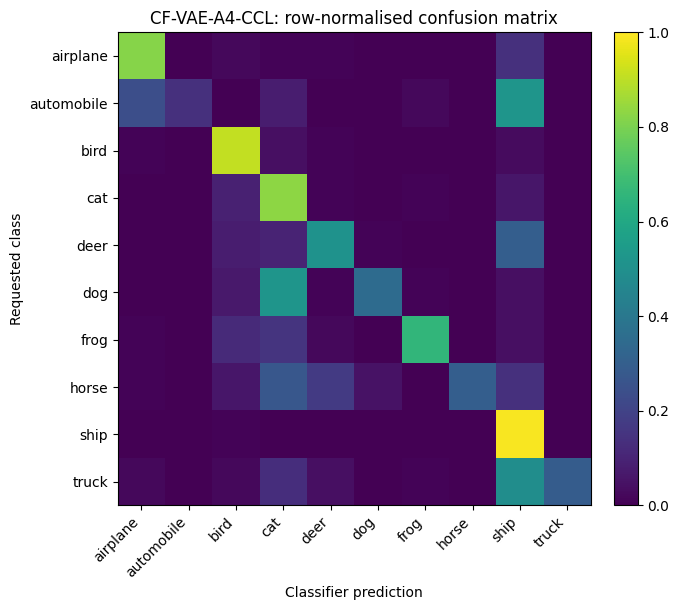

In [58]:
if SHOW_SAVED_REVIEW:
    _review_confusion_from_npy(FINAL_CF_VAE_ID)

#### Evaluation

The VAE confusion matrix shows that weak requested classes are often redirected into particular alternative categories instead of failing randomly. For example, automobile/truck and several animal rows contain concentrated off-diagonal mass. This explains why A4 can have strong overall class-control improvement while still being highly uneven by class.

### 10.6C — Selected GAN: per-class accuracy and requested confidence

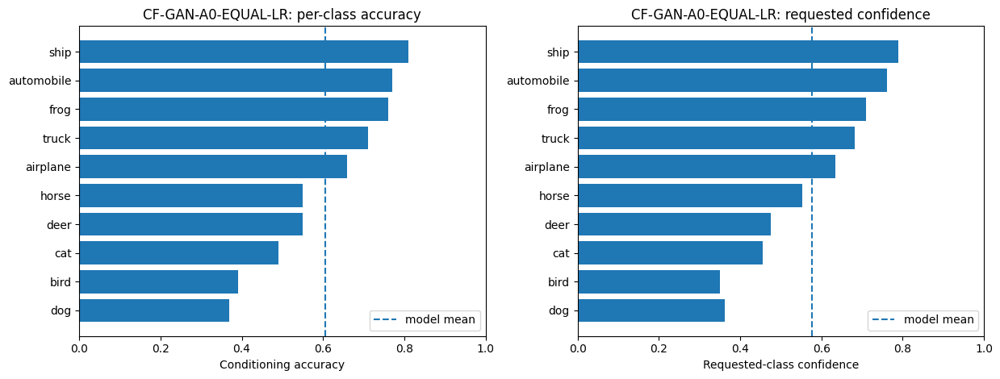

In [58]:
if SHOW_SAVED_REVIEW:
    _model_id = FINAL_CF_GAN_ID
    _path = RESULT_DIR / f"{_model_id}_individual_per_class_control.csv"
    _table = _review_read_csv(_path)

    if _table is not None and not _table.empty:
        _order = np.argsort(
            _table["conditioning_accuracy"].astype(float).to_numpy()
        )

        fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))

        axes[0].barh(
            _table["class_name"].iloc[_order],
            _table["conditioning_accuracy"].astype(float).iloc[_order],
        )
        axes[0].axvline(
            _table["conditioning_accuracy"].astype(float).mean(),
            linestyle="--",
            label="model mean",
        )
        axes[0].set_xlim(0, 1)
        axes[0].set_xlabel("Conditioning accuracy")
        axes[0].set_title(f"{_model_id}: per-class accuracy")
        axes[0].legend()

        axes[1].barh(
            _table["class_name"].iloc[_order],
            _table["mean_requested_class_confidence"].astype(float).iloc[_order],
        )
        axes[1].axvline(
            _table["mean_requested_class_confidence"].astype(float).mean(),
            linestyle="--",
            label="model mean",
        )
        axes[1].set_xlim(0, 1)
        axes[1].set_xlabel("Requested-class confidence")
        axes[1].set_title(f"{_model_id}: requested confidence")
        axes[1].legend()

        plt.tight_layout()
        plt.show()

#### Evaluation

`CF-GAN-A0-EQUAL-LR` is more balanced across classes. Its stronger classes include **ship (0.81)**, **automobile (0.77)**, **frog (0.76)**, **truck (0.71)** and **airplane (0.66)**. Its main weaknesses are **dog (0.37)** and **bird (0.39)**, with cat also below the model mean. The confidence plot broadly supports the same ordering.

### 10.6D — Selected GAN: confusion matrix

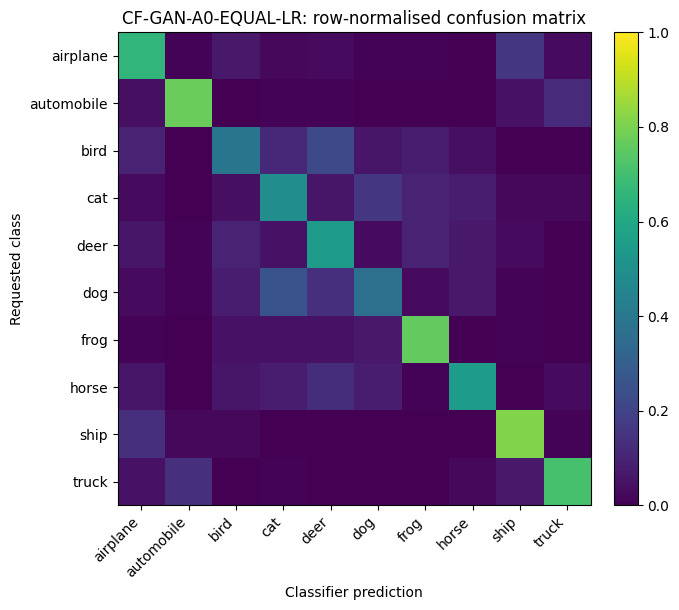

In [58]:
if SHOW_SAVED_REVIEW:
    _review_confusion_from_npy(FINAL_CF_GAN_ID)

#### Evaluation

The GAN confusion matrix is less dominated by a few extreme failures than the VAE matrix, although animal categories still overlap. The remaining off-diagonal errors show why class-specific reporting is necessary: one overall conditioning-accuracy number cannot describe which requested labels the model handles reliably.

## 10.7 Within-class diversity

Conditioning accuracy answers “is it the requested class?”, whereas diversity
asks “does the model keep producing different examples of that class?”. The
saved pixel-distance diagnostic is replotted against real test images as a
rough mode-collapse screen.

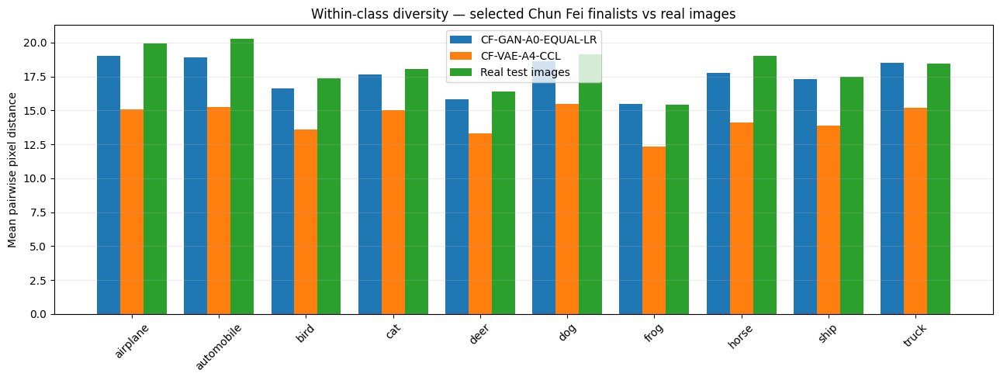

In [59]:
if SHOW_SAVED_REVIEW:
    _diversity_review = _review_read_csv(
        RESULT_DIR / "CF_individual_finalist_within_class_diversity.csv"
    )
    if _diversity_review is not None and not _diversity_review.empty:
        _pivot = _diversity_review.pivot(
            index="class_name",
            columns="source",
            values="mean_pairwise_pixel_distance",
        ).reindex(CLASS_NAMES)

        _x = np.arange(NUM_CLASSES)
        _sources = list(_pivot.columns)
        _width = 0.8 / max(len(_sources), 1)

        fig, ax = plt.subplots(figsize=(13, 5))
        for _j, _source in enumerate(_sources):
            _offset = (_j - (len(_sources) - 1) / 2) * _width
            ax.bar(
                _x + _offset,
                _pivot[_source].to_numpy(),
                width=_width,
                label=_source,
            )

        ax.set_xticks(_x)
        ax.set_xticklabels(CLASS_NAMES, rotation=45)
        ax.set_ylabel("Mean pairwise pixel distance")
        ax.set_title(
            "Within-class diversity — selected Chun Fei finalists vs real images"
        )
        ax.legend()
        ax.grid(alpha=0.25, axis="y")
        plt.tight_layout()
        plt.show()

### Evaluation

A generated class sitting far below the real-data reference can indicate
reduced within-class variety even when its requested-class accuracy is high.
This makes diversity a separate failure axis from class correctness. The
pixel-distance measure is deliberately treated as a **screening proxy**, not a
perceptual metric, so it supports rather than replaces the generated grids.

## 10.8 Nearest-real-image memorisation screen

The nearest-real diagnostic is reloaded as a distance plot. A very small
generated-to-training distance would be a warning sign for copying; ordinary
non-zero distances are only supporting evidence against blatant reproduction.

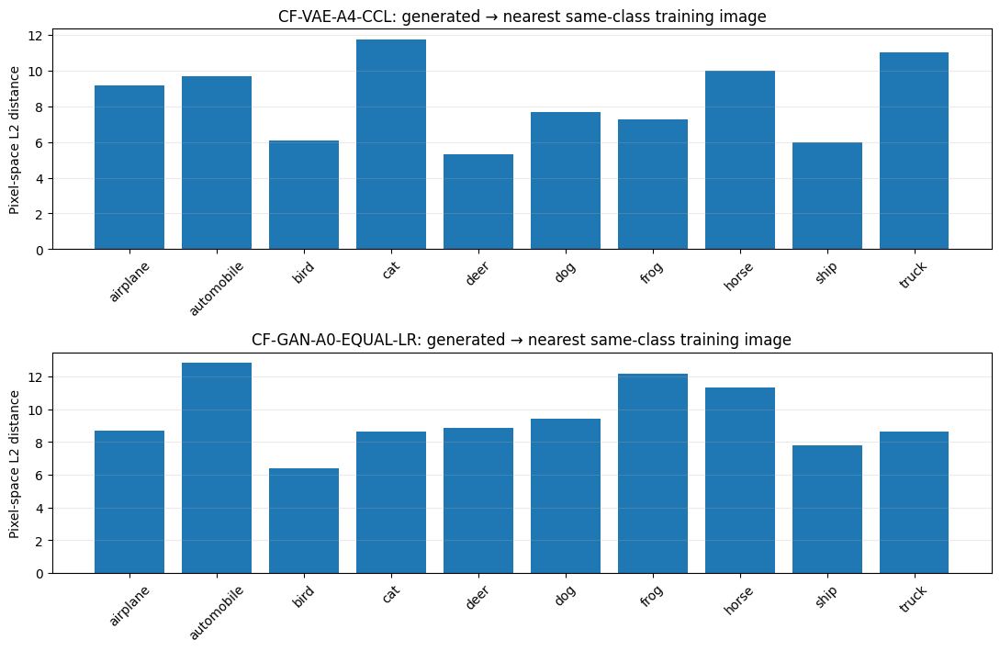

[saved figure not found] chun_fei_ca2_yx_split/results/review_figures/CF-VAE-A4-CCL_nearest_real_screen.png
[saved figure not found] chun_fei_ca2_yx_split/results/review_figures/CF-GAN-A0-EQUAL-LR_nearest_real_screen.png


In [60]:
if SHOW_SAVED_REVIEW:
    _mem_review = _review_read_csv(
        RESULT_DIR / "CF_individual_finalist_nearest_real_screen.csv"
    )
    if _mem_review is not None and not _mem_review.empty:
        _models = list(_mem_review["model_id"].drop_duplicates())
        fig, axes = plt.subplots(
            len(_models),
            1,
            figsize=(11, 3.6 * max(len(_models), 1)),
            squeeze=False,
        )

        for _row, _model_id in enumerate(_models):
            _sub = _mem_review[_mem_review["model_id"] == _model_id]
            axes[_row, 0].bar(
                _sub["class_name"],
                _sub["generated_to_nearest_training_pixel_distance"],
            )
            axes[_row, 0].set_title(
                f"{_model_id}: generated → nearest same-class training image"
            )
            axes[_row, 0].set_ylabel("Pixel-space L2 distance")
            axes[_row, 0].tick_params(axis="x", rotation=45)
            axes[_row, 0].grid(alpha=0.25, axis="y")

        plt.tight_layout()
        plt.show()

        for _model_id in _models:
            _review_display_png(
                REVIEW_FIGURE_DIR / f"{_model_id}_nearest_real_screen.png",
                title=f"{_model_id} — generated vs nearest real examples",
            )

### Evaluation

This check is intentionally conservative. Pixel-space nearest-neighbour
distance is sensitive to shifts, colour and alignment, so it cannot prove the
absence of memorisation. Its value is to identify obvious near-copy behaviour
and to complement the diversity plots. The generated-versus-nearest-real grids
are saved whenever the optional memorisation diagnostic is run.

## 10.9 Did the EDA predict my selected VAE's hard classes?

To mirror the class-difficulty validation used in You Xuan's notebook, this
cell tests two **real-data-only** EDA proxies against the measured per-class
accuracy of my selected VAE:

1. mean per-pixel variability within each real class;
2. class isolation — distance from each class-mean image to its three nearest
   class means.

The proxies are computed from real training data; the y-axis comes from the
saved A4 per-class diagnostic. The purpose is to test an EDA hypothesis, not
to force the data to agree with it.

A4 accuracy vs pixel variability: Pearson r=-0.358, Spearman rho=-0.394
A4 accuracy vs class isolation: Pearson r=+0.048, Spearman rho=-0.224


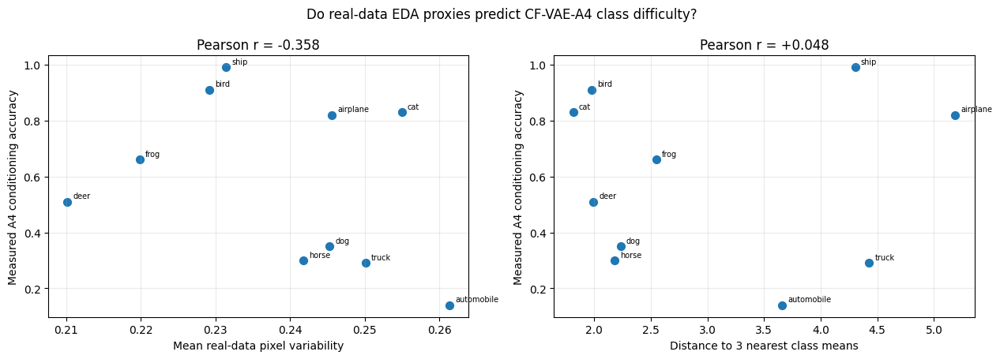

In [61]:
if SHOW_SAVED_REVIEW:
    _a4_path = RESULT_DIR / f"{FINAL_CF_VAE_ID}_individual_per_class_control.csv"
    _a4_per = _review_read_csv(_a4_path)

    if _a4_per is not None and not _a4_per.empty:
        _acc_by_class = (
            _a4_per
            .set_index("class_name")
            .reindex(CLASS_NAMES)["conditioning_accuracy"]
            .astype(float)
            .to_numpy()
        )

        _train_labels = np.asarray(y_train).reshape(-1)
        _pixel_variability = np.array([
            x_train_vae[_train_labels == class_id].std(axis=0).mean()
            for class_id in range(NUM_CLASSES)
        ])

        _class_means = np.stack([
            x_train_vae[_train_labels == class_id].mean(axis=0)
            for class_id in range(NUM_CLASSES)
        ])
        _flat_means = _class_means.reshape(NUM_CLASSES, -1)
        _distance_matrix = np.linalg.norm(
            _flat_means[:, None, :] - _flat_means[None, :, :],
            axis=-1,
        )
        _class_isolation = np.array([
            np.sort(_distance_matrix[class_id])[1:4].mean()
            for class_id in range(NUM_CLASSES)
        ])

        _pearson_var = float(
            np.corrcoef(_acc_by_class, _pixel_variability)[0, 1]
        )
        _spearman_var = float(
            spearmanr(_acc_by_class, _pixel_variability).statistic
        )
        _pearson_iso = float(
            np.corrcoef(_acc_by_class, _class_isolation)[0, 1]
        )
        _spearman_iso = float(
            spearmanr(_acc_by_class, _class_isolation).statistic
        )

        print(
            f"A4 accuracy vs pixel variability: "
            f"Pearson r={_pearson_var:+.3f}, "
            f"Spearman rho={_spearman_var:+.3f}"
        )
        print(
            f"A4 accuracy vs class isolation: "
            f"Pearson r={_pearson_iso:+.3f}, "
            f"Spearman rho={_spearman_iso:+.3f}"
        )

        fig, axes = plt.subplots(1, 2, figsize=(12.8, 4.6))
        for _axis, _proxy, _name, _r in [
            (
                axes[0],
                _pixel_variability,
                "Mean real-data pixel variability",
                _pearson_var,
            ),
            (
                axes[1],
                _class_isolation,
                "Distance to 3 nearest class means",
                _pearson_iso,
            ),
        ]:
            _axis.scatter(_proxy, _acc_by_class, s=50)
            for _class_id, _class_name in enumerate(CLASS_NAMES):
                _axis.annotate(
                    _class_name,
                    (_proxy[_class_id], _acc_by_class[_class_id]),
                    fontsize=7,
                    textcoords="offset points",
                    xytext=(5, 3),
                )
            _axis.set_xlabel(_name)
            _axis.set_ylabel("Measured A4 conditioning accuracy")
            _axis.set_title(f"Pearson r = {_r:+.3f}")
            _axis.grid(alpha=0.25)

        plt.suptitle(
            "Do real-data EDA proxies predict CF-VAE-A4 class difficulty?"
        )
        plt.tight_layout()
        plt.show()

### Evaluation

This validation step tests whether the EDA proxy is supported by the measured results. A strong correlation would
support the corresponding EDA proxy; a weak correlation means that the proxy
does not explain A4's class-specific behaviour well. That outcome is still
useful: A4 includes an explicit class-consistency training objective, so its
per-class strengths may differ from a model whose errors are driven mainly by
raw CIFAR-10 class overlap. The final group-level easiest/hardest conclusion
therefore remains based on all four finalists in the shared notebook.

## 10.10 Saved VAE conditioning diagnostics and latent figures

Where available, figures produced by the optional diagnostic stages are loaded
directly from `results/` / `review_figures/`. This allows the evidence to be reviewed again without rerunning t-SNE or the larger label-swap diagnostic.

### Fixed-z label sweep

### CF-VAE-A5-CCL025 diagnostic fixed z label sweep

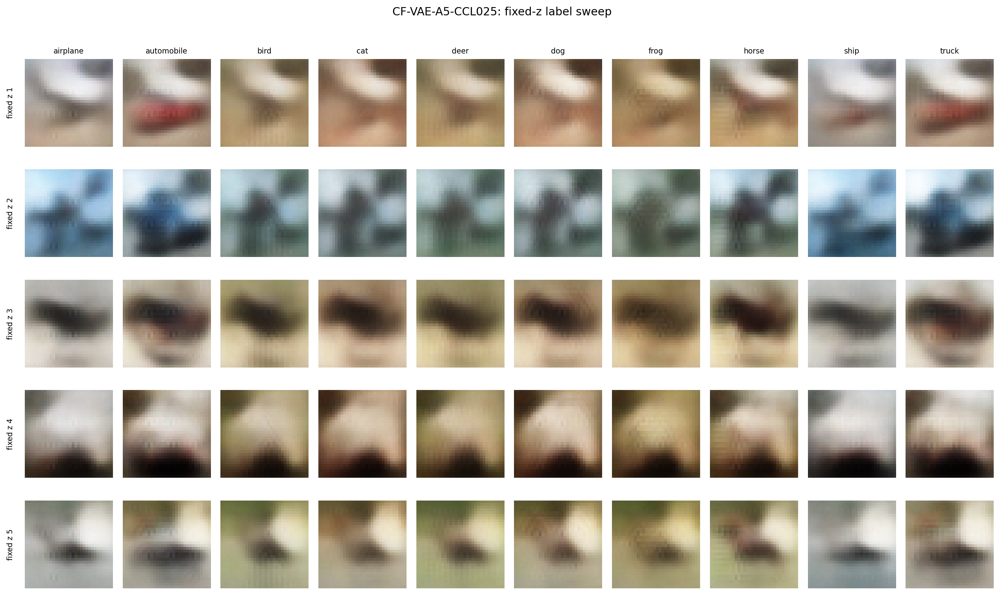

In [62]:
if SHOW_SAVED_REVIEW:
    _path = RESULT_DIR / f"{DIAGNOSTIC_VAE_MODEL_ID}_diagnostic_fixed_z_label_sweep.png"
    if _path.exists():
        _review_display_png(_path, _path.stem.replace("_", " "))

#### Evaluation

With the latent vector held fixed, changing only the requested label changes colour and some semantic features, but a large amount of row structure is preserved. The decoder therefore **uses the label**, but the latent representation still has strong influence over the output. This supports the conclusion that conditioning is improved rather than perfectly disentangled.

### Reconstruction versus random-prior conditioning

### CF-VAE-A5-CCL025 diagnostic reconstruction vs prior

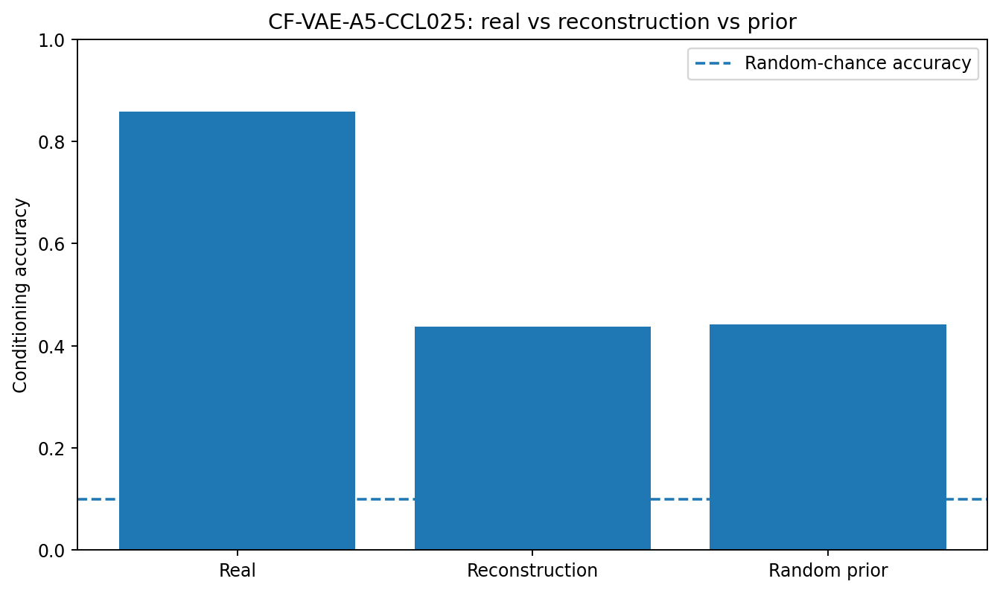

In [62]:
if SHOW_SAVED_REVIEW:
    _path = RESULT_DIR / f"{DIAGNOSTIC_VAE_MODEL_ID}_diagnostic_reconstruction_vs_prior.png"
    if _path.exists():
        _review_display_png(_path, _path.stem.replace("_", " "))

#### Evaluation

The frozen classifier is much more accurate on real CIFAR-10 images than on either VAE reconstructions or random-prior generations; the latter two are both around the mid-40% range in the saved diagnostic. This indicates that the VAE's semantic information is substantially weaker after passing through the generative bottleneck, not only when sampling from the prior.

### Posterior label-swap diagnostic

### CF-VAE-A5-CCL025 diagnostic posterior label swap

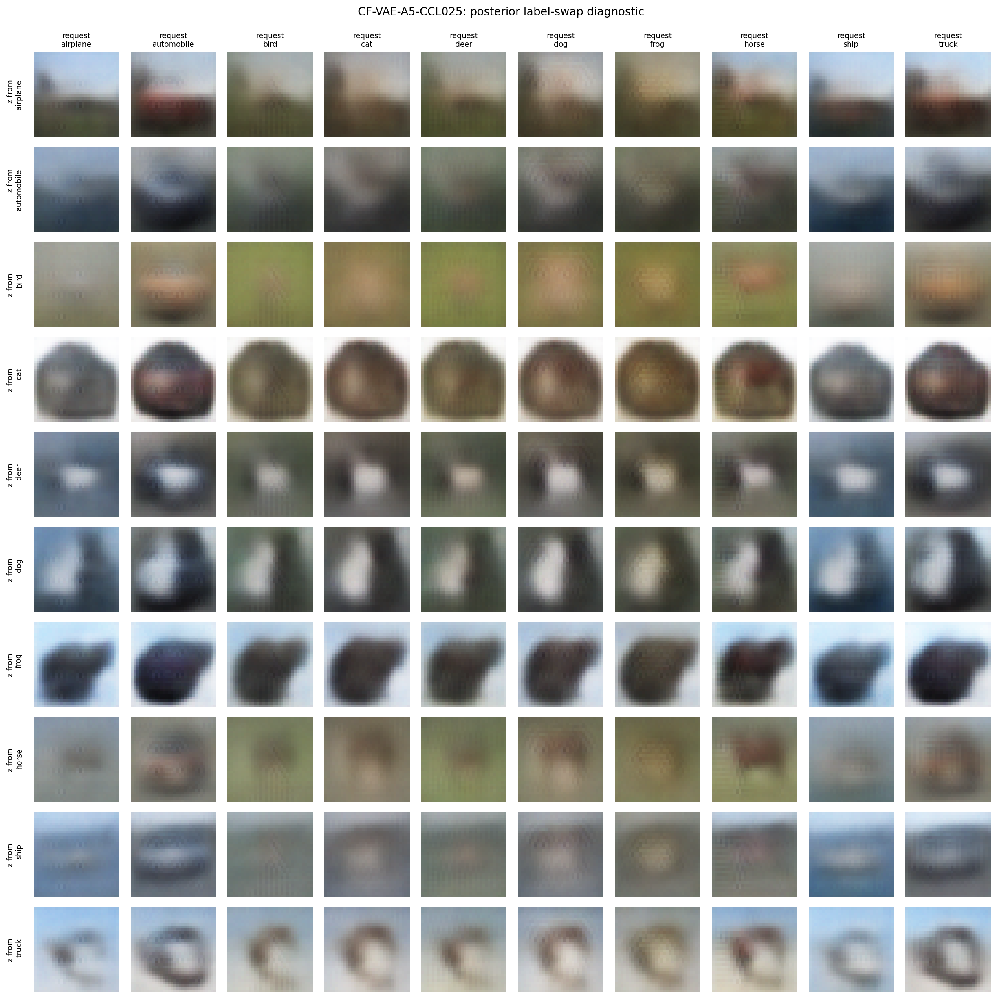

In [62]:
if SHOW_SAVED_REVIEW:
    _path = RESULT_DIR / f"{DIAGNOSTIC_VAE_MODEL_ID}_diagnostic_posterior_label_swap.png"
    if _path.exists():
        _review_display_png(_path, _path.stem.replace("_", " "))

#### Evaluation

Changing the requested label while holding the posterior latent fixed alters visible characteristics, but many outputs remain ambiguous. The explicit label therefore affects generation, yet it does not fully override the information already stored in the latent code. This is supporting evidence for the remaining class-control limitation of the VAE.

# 11. Limitations

The main limitations are:

- CIFAR-10 images are only 32 × 32;
- FID and Inception Score are sample- and implementation-dependent;
- ImageNet-based Inception Score is imperfect for 32 × 32 CIFAR-10 images
  and does not measure whether the requested CIFAR-10 label was followed;
- repeated FID sets estimate generation-sampling variation, not full
  retraining variation;
- classifier-based class accuracy depends on classifier quality;
- exact duplicate rate does not capture every near-duplicate;
- limited training budgets may prevent convergence;
- the selected result may vary with random initialisation.

Additional VAE-specific limitations:

- the 20-epoch warm-up and 0.125 free-bits threshold are fixed choices;
- free bits changes the objective only in A2;
- only two non-zero class-loss weights, 0.25 and 1.00, are tested;
- A4 and A5 use the same helper classifier, so helper-specific bias may
  influence both models;
- the helper may reward class-recognisable cues that humans still find
  blurry or unnatural;
- using a separate evaluation classifier reduces, but does not eliminate,
  classifier-related bias;
- A3, A4 and A5 total losses are not directly comparable because the weighted
  objectives differ;
- the class-consistency prior term introduces extra computation and
  stochasticity;
- active-dimension thresholds and t-SNE plots are diagnostic aids rather
  than definitive representation measures.


# 12. Conclusion

This investigation developed a conditional VAE experiment chain and a
supporting conditional GAN comparison for CIFAR-10, using the shared
stratified data split and common evaluation assets. The results show that
**image fidelity, latent-space behaviour and requested-class control do not
improve together automatically**; each technique changes a different part of
the generative problem.

### VAE findings

The VAE sequence produced three main findings.

First, **KL warm-up was useful**. Compared with A0, A1 improved FID from
**185.82 to 179.37**, increased IS from **2.1176 to 2.1440**, and increased
active latent dimensions from **30/32 to 32/32**. The training curves show a
controlled transition as beta rises to 1 rather than an unstable collapse of
the KL term.

Second, **free bits was not useful under the tested setting**. A2's
free-bits-active fraction stays essentially at zero, and its final FID, IS and
class-control results do not improve on A1. The technique is therefore retained
as negative evidence rather than being carried forward.

Third, **class control required explicit semantic pressure**. A3's multi-stage
conditioning achieved the best VAE FID (**177.88**) but only **21.18%**
conditioning accuracy. Adding the strong class-consistency objective in A4
raised conditioning accuracy to **58.36%** and requested-class confidence to
**52.83%**, while keeping all 32 latent dimensions active. The cost was a worse
FID of **200.08**. Reducing the class-loss weight in A5 recovered some FID
(**193.84**) but reduced conditioning accuracy to **45.38%** and produced the
lowest VAE IS (**2.0923**). Therefore, **`CF-VAE-A4-CCL` is selected as my VAE
finalist** because the goal is specified-class generation and A4
provides by far the strongest VAE class control.

The VAE grids and reconstructions also show the family's main limitation:
outputs preserve coarse colour, background and structure but remain visibly
soft. Per-class behaviour is uneven; in the individual 100-per-class
diagnostic, A4 is strongest on ship, bird, cat and airplane but weak on
automobile, truck, horse and dog. Its within-class pixel diversity is also
consistently below the real-data reference.

### GAN findings

The supporting GAN experiment gives a clear controlled result. Lowering only
the generator learning rate in the TTUR variant did **not** improve this
architecture. The equal-rate A0 model achieves:

- **FID:** 40.503 ± 0.478 vs 46.090 ± 0.089 for TTUR;
- **IS:** 4.569 ± 0.016 vs 4.302 ± 0.042;
- **conditioning accuracy:** 60.34% vs 54.16%;
- **requested-class confidence:** 57.52% vs 51.08%.

The training curves support these numbers: A0 settles into a more balanced
adversarial regime, while A1 retains a higher generator loss and a larger
real/fake-logit separation, indicating that the discriminator remains
comparatively stronger. **`CF-GAN-A0-EQUAL-LR` is therefore retained as my GAN
finalist and TTUR is rejected.**

Qualitatively, A0 generates much sharper and more varied samples than the VAE.
Its within-class diversity bars remain close to the real-test reference for
most classes, and the fixed-seed grid shows substantial variation in pose,
colour and background. The nearest-real screen also shows non-zero distances
for every class, providing supporting evidence against simple training-image
copying.

### Final individual decision

My two frozen finalists are therefore:

```text
CF-VAE-A4-CCL
CF-GAN-A0-EQUAL-LR
```

Within my own experiments, the GAN is stronger for **fidelity, sharpness and
within-class diversity**, while the selected VAE is valuable for demonstrating
a **structured latent representation and the trade-off between semantic class
control and distribution similarity**.

The individual notebook does not declare the overall team winner. These two
checkpoints are passed to the shared final-evaluation notebook together with
`YX-VAE-B1` and `YX-GAN-B4`, where all four finalists are compared using the
same FID, Inception Score, frozen classifier, per-class diagnostics, diversity
checks and fixed-seed visual evidence before the final 1,000-image generator
is chosen.
